In [1]:
%pip install matplotlib seaborn


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install pandas


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


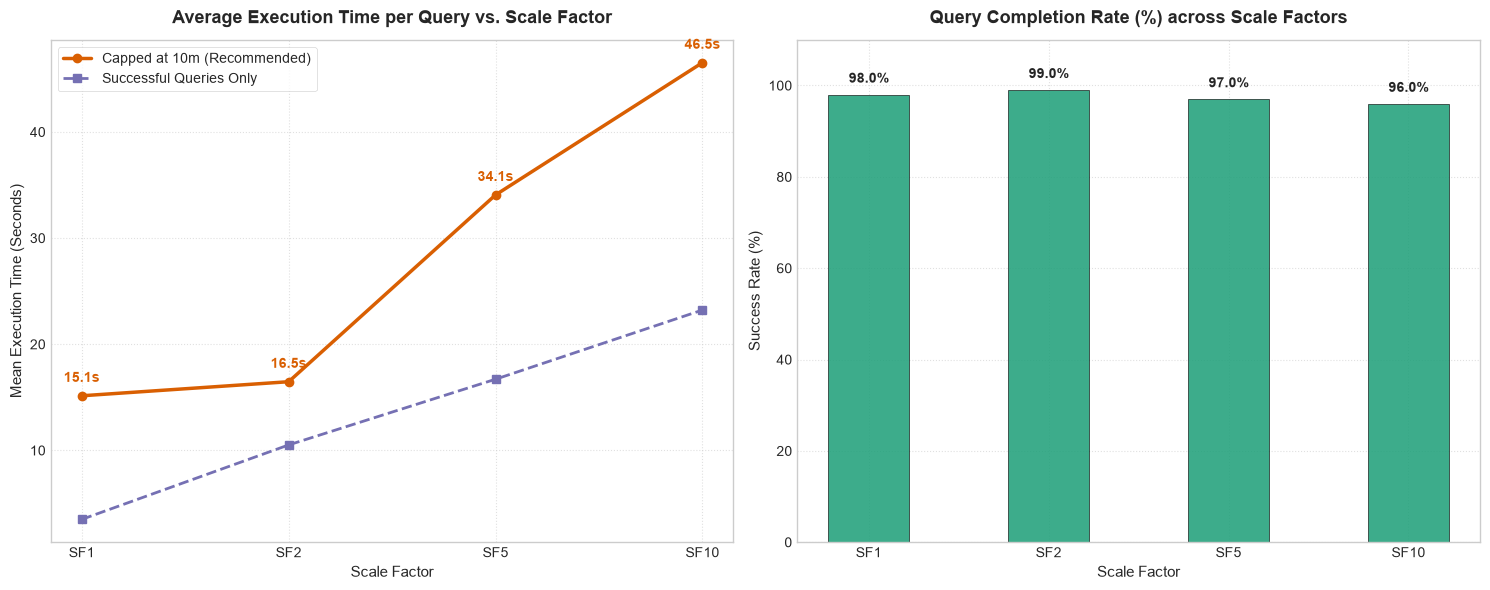

,Scale Factor,Success Rate (%),Avg Time (Capped 600s),Avg Time (Success Only),Total Workload Time (s)
0,SF1,97.979798,15.143667,3.500536,1499.223
1,SF2,98.989899,16.468909,10.514510,1630.422
2,SF5,96.969697,34.067091,16.704385,3372.642
3,SF10,95.959596,46.526152,23.221989,4606.089


In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurable Parameters
TIMEOUT_SECONDS = 600.0  # 10 minutes timeout limit
SCALE_FACTOR_FILES = {
    'SF1': './benchmarks/sf1/results_baseline/exec_time_details.csv',
    'SF2': './benchmarks/sf2/results_baseline/exec_time_details.csv',
    'SF5': './benchmarks/sf5/results_baseline/exec_time_details.csv',
    'SF10': './benchmarks/sf10/results_baseline/exec_time_details.csv'
}

summary_records = []

# Process each Scale Factor CSV
for sf_label, file_path in SCALE_FACTOR_FILES.items():
    # Load dataset (Replace file_path with df object if already loaded in memory)
    df = pd.read_csv(file_path)
    
    total_queries = len(df)
    successful_df = df[df['status'] == 'SUCCESS']
    success_count = len(successful_df)
    timeout_count = total_queries - success_count
    
    # 1. Successful Queries Only (Excluding Timeouts)
    avg_succ_only = successful_df['avg_exec_time'].mean()
    
    # 2. Capped at Timeout Limit (Imputing 600s for FAILED/NaN)
    capped_exec_times = df['avg_exec_time'].fillna(TIMEOUT_SECONDS)
    # Handle rows where status == 'FAILED' even if avg_exec_time wasn't NaN
    capped_exec_times.loc[df['status'] == 'FAILED'] = TIMEOUT_SECONDS
    
    avg_capped = capped_exec_times.mean()
    total_workload_time = capped_exec_times.sum()
    
    summary_records.append({
        'Scale Factor': sf_label,
        'Total Queries': total_queries,
        'Success Count': success_count,
        'Timeout Count': timeout_count,
        'Success Rate (%)': (success_count / total_queries) * 100,
        'Avg Time (Capped 600s)': avg_capped,
        'Avg Time (Success Only)': avg_succ_only,
        'Total Workload Time (s)': total_workload_time
    })

metrics_df = pd.DataFrame(summary_records)

# Plotting Configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Average Execution Time vs Scale Factor
x_axis = metrics_df['Scale Factor']

axes[0].plot(x_axis, metrics_df['Avg Time (Capped 600s)'], marker='o', linewidth=2.5, color='#d95f02', label='Capped at 10m (Recommended)')
axes[0].plot(x_axis, metrics_df['Avg Time (Success Only)'], marker='s', linewidth=2.0, linestyle='--', color='#7570b3', label='Successful Queries Only')

axes[0].set_title('Average Execution Time per Query vs. Scale Factor', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Scale Factor', fontsize=11)
axes[0].set_ylabel('Mean Execution Time (Seconds)', fontsize=11)
axes[0].legend(frameon=True)
axes[0].grid(True, linestyle=':', alpha=0.6)

# Annotate values on the capped line
for i, txt in enumerate(metrics_df['Avg Time (Capped 600s)']):
    axes[0].annotate(f"{txt:.1f}s", (x_axis[i], metrics_df['Avg Time (Capped 600s)'][i]),
                     textcoords="offset points", xytext=(0, 10), ha='center', fontweight='bold', color='#d95f02')

# Plot 2: Query Completion Rate (%)
bars = axes[1].bar(x_axis, metrics_df['Success Rate (%)'], color='#1b9e77', width=0.45, edgecolor='black', alpha=0.85)

axes[1].set_title('Query Completion Rate (%) across Scale Factors', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Scale Factor', fontsize=11)
axes[1].set_ylabel('Success Rate (%)', fontsize=11)
axes[1].set_ylim(0, 110)
axes[1].grid(True, linestyle=':', alpha=0.6)

# Annotate completion percentages on bar chart
for bar in bars:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + 2, f"{yval:.1f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Display summary metrics table
display(metrics_df[['Scale Factor', 'Success Rate (%)', 'Avg Time (Capped 600s)', 'Avg Time (Success Only)', 'Total Workload Time (s)']])

In [4]:
import pandas as pd

# Read the CSV file
df = pd.read_csv("./benchmarks/sf10/results_baseline/exec_time_details.csv")

df["avg_exec_time"] = df["avg_exec_time"].fillna(600)

df = df.sort_values(by="avg_exec_time", ascending=False)

# Keep only two columns
df = df[["query", "avg_exec_time"]]

df[:20]

,query,avg_exec_time
0,Q01,600.000
73,Q74,600.000
3,Q04,600.000
5,Q06,600.000
29,Q30,421.559
94,Q95,359.831
10,Q11,350.196
80,Q81,336.032
13,Q14,302.013
15,Q16,81.279


In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Change these paths to your actual CSV files
files = {
    1: "benchmarks/sf1/results_baseline/exec_time_details.csv",
    2: "benchmarks/sf2/results_baseline/exec_time_details.csv",
    5: "benchmarks/sf5/results_baseline/exec_time_details.csv",
    10: "benchmarks/sf10/results_baseline/exec_time_details.csv"
}

TIMEOUT = 600  # 10 minutes in seconds

all_data = []

for sf, path in files.items():

    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()

    # Convert execution times to numeric
    df["avg_exec_time"] = pd.to_numeric(
        df["avg_exec_time"], errors="coerce"
    )

    # Identify queries that exceeded the timeout
    df["timeout"] = (
        df["avg_exec_time"].isna()
        & df["error"].fillna("").str.contains(
            "statement timeout", case=False
        )
    )

    # Check for other failures or missing values
    unknown = df[
        df["avg_exec_time"].isna() & ~df["timeout"]
    ]

    if not unknown.empty:
        raise ValueError(
            f"SF{sf}: Missing times without a confirmed timeout: "
            f"{unknown['query'].tolist()}"
        )

    # Use 600 seconds as a lower bound for timed-out queries
    df["plot_time"] = df["avg_exec_time"].fillna(TIMEOUT)

    # Display timeout values as >10 min
    df["display_time"] = df["avg_exec_time"].map(
        lambda x: f"{x:.3f}"
        if pd.notna(x) else ">10 min"
    )

    # Extract query number for correct sorting
    df["query_no"] = (
        df["query"].str.extract(r"(\d+)").astype(int)
    )

    df = df.sort_values("query_no")

    # Validate that all 99 queries are present
    if (
        len(df) != 99
        or set(df["query_no"]) != set(range(1, 100))
    ):
        raise ValueError(f"SF{sf}: Expected Q01 through Q99")

    df["SF"] = sf

    # Save a simplified CSV with >10 min displayed
    df[["query", "display_time"]].to_csv(
        f"sf{sf}_cleaned.csv", index=False
    )

    all_data.append(df)

# Combine all scale factors
data = pd.concat(all_data, ignore_index=True)

display(data[["SF", "query", "display_time", "timeout"]].head(15))

,SF,query,display_time,timeout
0,1,Q01,19.359,False
1,1,Q02,0.157,False
2,1,Q03,0.012,False
3,1,Q04,>10 min,True
4,1,Q05,0.192,False
5,1,Q06,38.741,False
6,1,Q07,0.214,False
7,1,Q08,0.025,False
8,1,Q09,0.417,False
9,1,Q10,1.719,False


In [49]:
summary = (
    data.groupby("SF")
    .agg(
        total_time_sec=("plot_time", "sum"),
        avg_query_time_sec=("plot_time", "mean"),
        timeout_count=("timeout", "sum")
    )
    .reset_index()
    .sort_values("SF")
)

summary["total_time_min"] = summary["total_time_sec"] / 60

display(summary)

,SF,total_time_sec,avg_query_time_sec,timeout_count,total_time_min
0,1,1499.223,15.143667,1,24.98705
1,2,1630.422,16.468909,1,27.17370
2,5,3372.642,34.067091,2,56.21070
3,10,4606.089,46.526152,4,76.76815


,SF,total_time_sec,query_count,timeout_count,total_time_min
0,1,58.770,94,0,0.979500
1,2,207.802,94,0,3.463367
2,5,942.934,94,0,15.715567
3,10,1855.893,94,0,30.931550


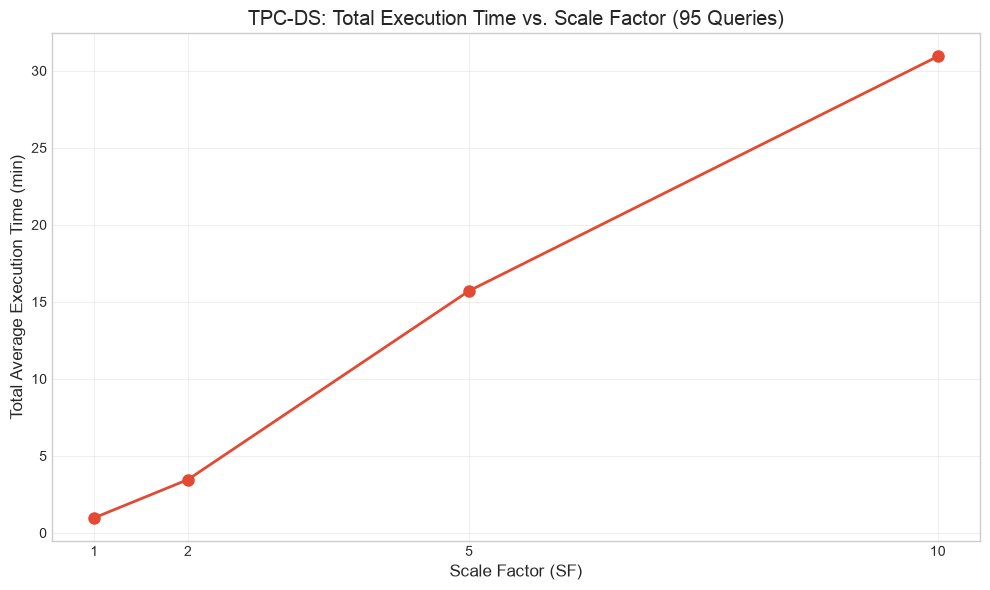

In [51]:
# Queries to exclude from all scale factors
excluded_queries = [1, 4, 6, 11, 74]

# Filter data without modifying original CSV files
filtered_data = data[
    ~data["query_no"].isin(excluded_queries)
].copy()

# Calculate total average execution time for each SF
summary = (
    filtered_data.groupby("SF")
    .agg(
        total_time_sec=("avg_exec_time", "sum"),
        query_count=("query_no", "count"),
        timeout_count=("timeout", "sum")
    )
    .reset_index()
    .sort_values("SF")
)

# Make sure all remaining queries completed successfully
assert (summary["query_count"] == 94).all(), "Unexpected query count"
assert (summary["timeout_count"] == 0).all(), "Other timed-out queries remain"

# Convert seconds to minutes
summary["total_time_min"] = summary["total_time_sec"] / 60

display(summary)

# Plot
plt.figure(figsize=(10, 6))

plt.plot(
    summary["SF"],
    summary["total_time_min"],
    marker="o",
    linewidth=2,
    markersize=8
)

plt.xlabel("Scale Factor (SF)")
plt.ylabel("Total Average Execution Time (min)")
plt.title("TPC-DS: Total Execution Time vs. Scale Factor (95 Queries)")

plt.xticks([1, 2, 5, 10])
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

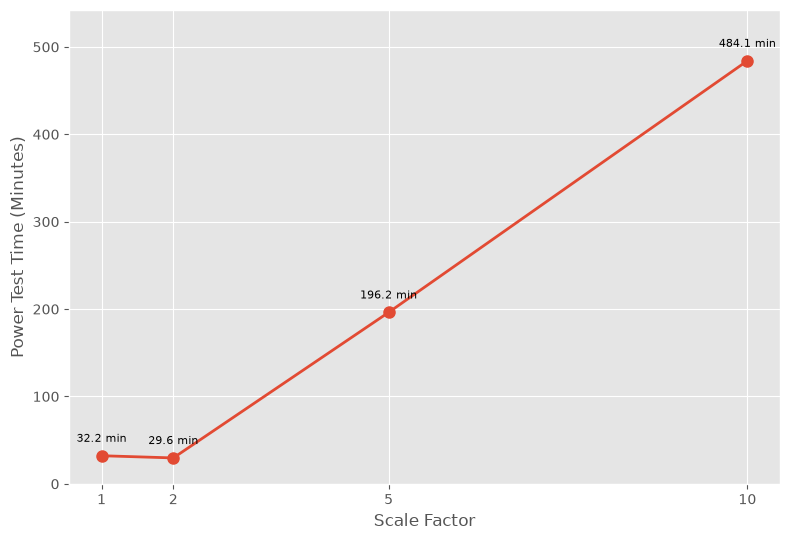

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

# --- EDIT: path to each scale factor's CSV ---
files = {
    1:  "./benchmarks/sf1/results_no_timeout_rerun/exec_time_details.csv",
    2:  "./benchmarks/sf2/results_no_timeout_rerun/exec_time_details.csv",
    5:  "./benchmarks/sf5/results_no_timeout/exec_time_details.csv",
    10: "./benchmarks/sf10/results-baseline-original-without-timeout/exec_time_details.csv",
}

totals_min = {}
for sf, path in files.items():
    df = pd.read_csv(path)
    df = df[df["status"] == "SUCCESS"]               # ignore failed queries
    totals_min[sf] = df["avg_exec_time"].sum() / 60  # seconds -> minutes

sfs = list(totals_min.keys())
vals = list(totals_min.values())

plt.style.use("ggplot")
fig, ax = plt.subplots(figsize=(8, 5.5))

ax.plot(sfs, vals, marker="o", markersize=8, linewidth=2, color="#E24A33")

# small value label next to each point
for x, y in zip(sfs, vals):
    ax.annotate(f"{y:.1f} min", (x, y), textcoords="offset points",
                xytext=(0, 10), ha="center", fontsize=8)

ax.set_xticks(sfs)
ax.set_xlabel("Scale Factor", fontsize=12)
ax.set_ylabel("Power Test Time (Minutes)", fontsize=12)
# ax.set_title("TPC-DS Baseline on PostgreSQL 16:\nTotal Execution Time of 99 Queries vs. Scale Factor",
#              fontsize=13)
ax.set_ylim(0, max(vals) * 1.12)

plt.tight_layout()
plt.savefig("power_test_by_scale_factor.png", dpi=200)
plt.show()

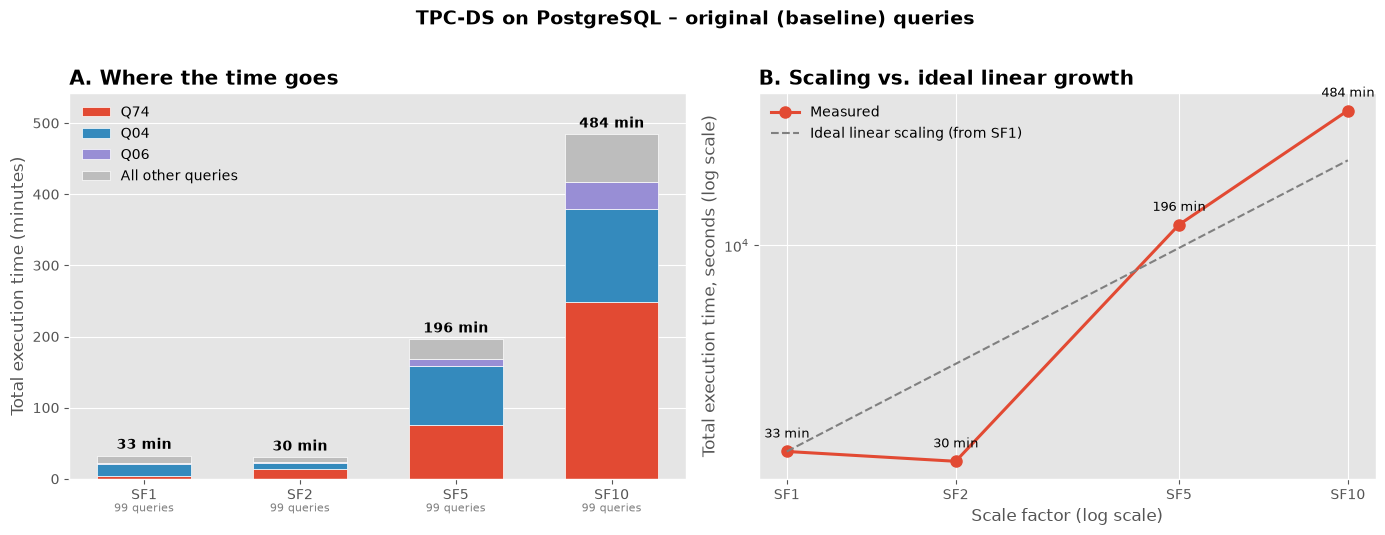

,# Queries,Time (min),x vs SF1,x data size
SF1,99,32.6,1.0,1.0
SF2,99,30.2,0.9,2.0
SF5,99,196.2,6.0,5.0
SF10,99,484.1,14.8,10.0


In [19]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plt.style.use("ggplot")

# ============================== CONFIG ==============================
# scale factor -> csv path of the ORIGINAL (baseline) run
FILES = {
    "SF1":  "./benchmarks/sf1/results_no_timeout/exec_time_details.csv",
    "SF2":  "./benchmarks/sf2/results_no_timeout/exec_time_details.csv",
    "SF5":  "./benchmarks/sf5/results_no_timeout/exec_time_details.csv",
    "SF10": "./benchmarks/sf10/results-baseline-original-without-timeout/exec_time_details.csv",
}

# OPTIONAL: optimized runs. If filled in, only queries present in ALL of these
# files are used, so the numbers match your before/after plots.
# Leave as {} to use every query in the original files.
OPTIMIZED_FILES = {
    # "SF1":  "./benchmarks/sf1/results_optimization/exec_time_details.csv",
    # "SF2":  "./benchmarks/sf2/results_optimization/exec_time_details.csv",
    # "SF5":  "./benchmarks/sf5/results_optimization/exec_time_details.csv",
    # "SF10": "./benchmarks/sf10/results_optimization/exec_time_details.csv",
}

QUERY_COL = None             # set if the query-id column is not auto-detected correctly
TIME_COL  = "avg_exec_time"  # set to your execution-time column name
TOP_N     = 3                # heaviest queries (at the largest SF) shown separately
REF_IDX   = 0                # which SF anchors the "ideal linear scaling" line (0 = SF1, 1 = SF2, ...)
COLOR     = "#E24A33"
# ====================================================================


def qnum(v):
    """Q04 / query_04 / 4 / 'query04.sql' -> 4"""
    m = re.search(r"(\d+)", str(v))
    return int(m.group(1)) if m else None


def guess_cols(df):
    qc = QUERY_COL or next((c for c in df.columns if "query" in c.lower() or c.lower() in ("q", "id", "name")), df.columns[0])
    if TIME_COL:
        tc = TIME_COL
    else:
        num = [c for c in df.select_dtypes("number").columns if c != qc]
        pref = [c for c in num if any(k in c.lower() for k in ("exec", "time", "sec", "duration", "elapsed"))]
        tc = (pref or num)[-1]
    return qc, tc


def load(path):
    df = pd.read_csv(path)
    qc, tc = guess_cols(df)
    df = df[[qc, tc]].copy()
    df["q"] = df[qc].map(qnum)
    df = df.dropna(subset=["q", tc])
    return df.groupby("q")[tc].mean()   # one time per query (averages repeated runs)


# ---- load everything ----
orig = {sf: load(p) for sf, p in FILES.items()}

if OPTIMIZED_FILES:
    keep = set.intersection(*[set(load(p).index) for p in OPTIMIZED_FILES.values()])
    orig = {sf: s[s.index.isin(keep)] for sf, s in orig.items()}

sfs = list(orig.keys())
xn = [int(re.search(r"\d+", s).group()) for s in sfs]

g = pd.DataFrame({
    "# Queries": {sf: len(s) for sf, s in orig.items()},
    "Value (s)": {sf: s.sum() for sf, s in orig.items()},
})

# ---- data prep for the stacked bars ----
big = orig[sfs[-1]].sort_values(ascending=False)
top_q = list(big.index[:TOP_N])

parts = pd.DataFrame({
    sf: {**{f"Q{int(q):02d}": s.get(q, 0) for q in top_q},
         "All other queries": s.drop(index=top_q, errors="ignore").sum()}
    for sf, s in orig.items()
}).T / 60  # minutes

total_min = g["Value (s)"] / 60
palette = ["#E24A33", "#348ABD", "#988ED5", "#BDBDBD", "#8EBA42", "#FBC15E"][: len(parts.columns)]

# ---- figure ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# Panel A: stacked bars (minutes)
bottom = np.zeros(len(parts))
for col, c in zip(parts.columns, palette):
    ax1.bar(parts.index, parts[col], bottom=bottom, label=col, color=c, edgecolor="white", width=0.6)
    bottom += parts[col].values
for i, (sf, v) in enumerate(total_min.items()):
    ax1.text(i, v + total_min.max() * 0.01, f"{v:,.0f} min", ha="center", va="bottom",
             fontweight="bold", fontsize=10)
    ax1.text(i, -total_min.max() * 0.07, f"{int(g.loc[sf, '# Queries'])} queries",
             ha="center", va="top", fontsize=8, color="gray")
ax1.set_ylabel("Total execution time (minutes)")
ax1.set_title("A. Where the time goes", loc="left", fontweight="bold")
ax1.legend(frameon=False, loc="upper left")
ax1.set_ylim(0, total_min.max() * 1.12)
ax1.grid(axis="x", visible=False)

# Panel B: log-log vs ideal linear scaling
y = g["Value (s)"].values
ax2.plot(xn, y, marker="o", markersize=8, linewidth=2.2, color=COLOR, label="Measured")
ideal = y[REF_IDX] * np.array(xn) / xn[REF_IDX]
ax2.plot(xn, ideal, "--", color="gray", linewidth=1.5, label=f"Ideal linear scaling (from SF{xn[REF_IDX]})")
for x, v in zip(xn, y):
    ax2.annotate(f"{v/60:,.0f} min", (x, v), textcoords="offset points", xytext=(0, 10),
                 ha="center", fontsize=9)
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xticks(xn)
ax2.get_xaxis().set_major_formatter(FuncFormatter(lambda v, _: f"SF{int(v)}"))
ax2.minorticks_off()
ax2.set_xlabel("Scale factor (log scale)")
ax2.set_ylabel("Total execution time, seconds (log scale)")
ax2.set_title("B. Scaling vs. ideal linear growth", loc="left", fontweight="bold")
ax2.legend(frameon=False, loc="upper left")

fig.suptitle("TPC-DS on PostgreSQL – original (baseline) queries", fontsize=14, fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig("original_overview.png", dpi=200, bbox_inches="tight")
plt.show()

# ---- summary table ----
summary = g.copy()
summary["Time (min)"] = (summary["Value (s)"] / 60).round(1)
summary["x vs SF1"] = (summary["Value (s)"] / summary["Value (s)"].iloc[0]).round(1)
summary["x data size"] = [x / xn[0] for x in xn]
display(summary[["# Queries", "Time (min)", "x vs SF1", "x data size"]])


Scale Factor 1
Upper fence: 11.354 s | Lower fence: 0.004 s
query  median_exec_time
  Q04          1028.124
  Q11           563.187
  Q74           233.587
  Q06            40.972
  Q01            19.637
  Q81            18.565
  Q14            12.981


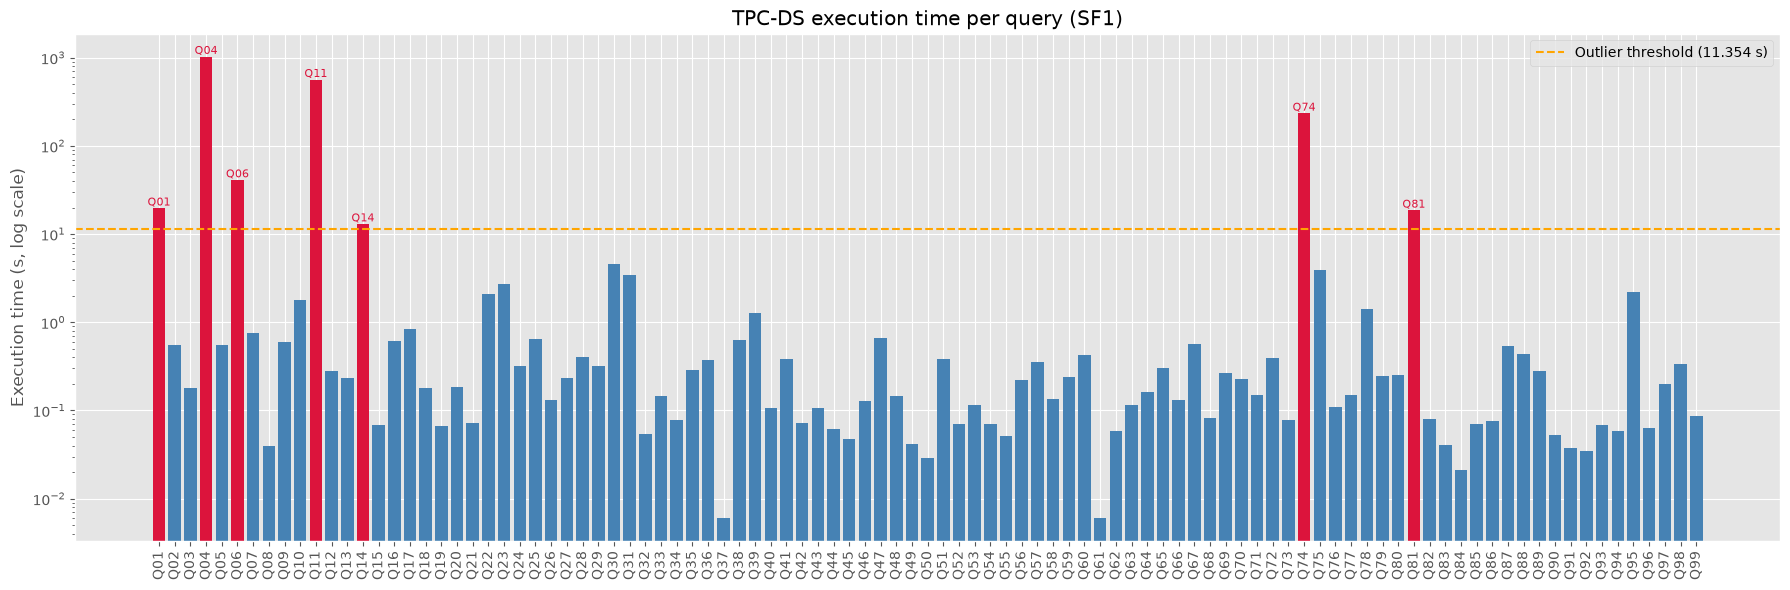

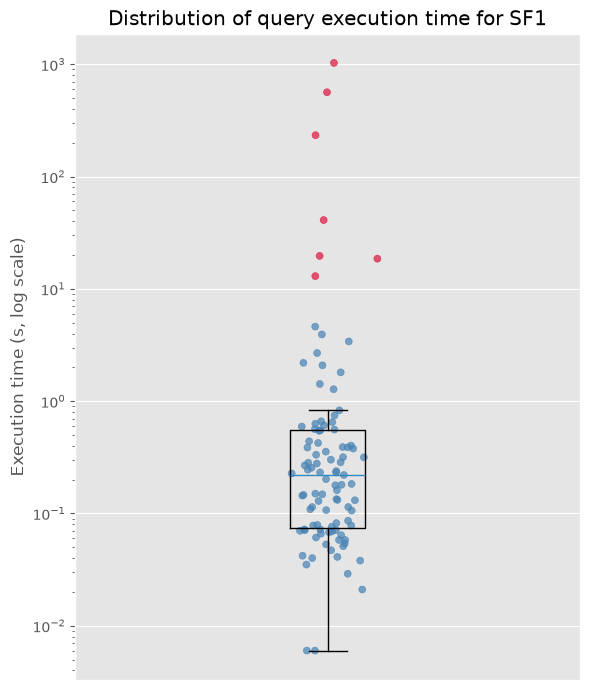


Scale Factor 2
Upper fence: 23.954 s | Lower fence: 0.005 s
query  median_exec_time
  Q74           787.017
  Q04           536.608
  Q06           124.312
  Q11            90.114
  Q01            75.055
  Q81            72.873
  Q14            36.160


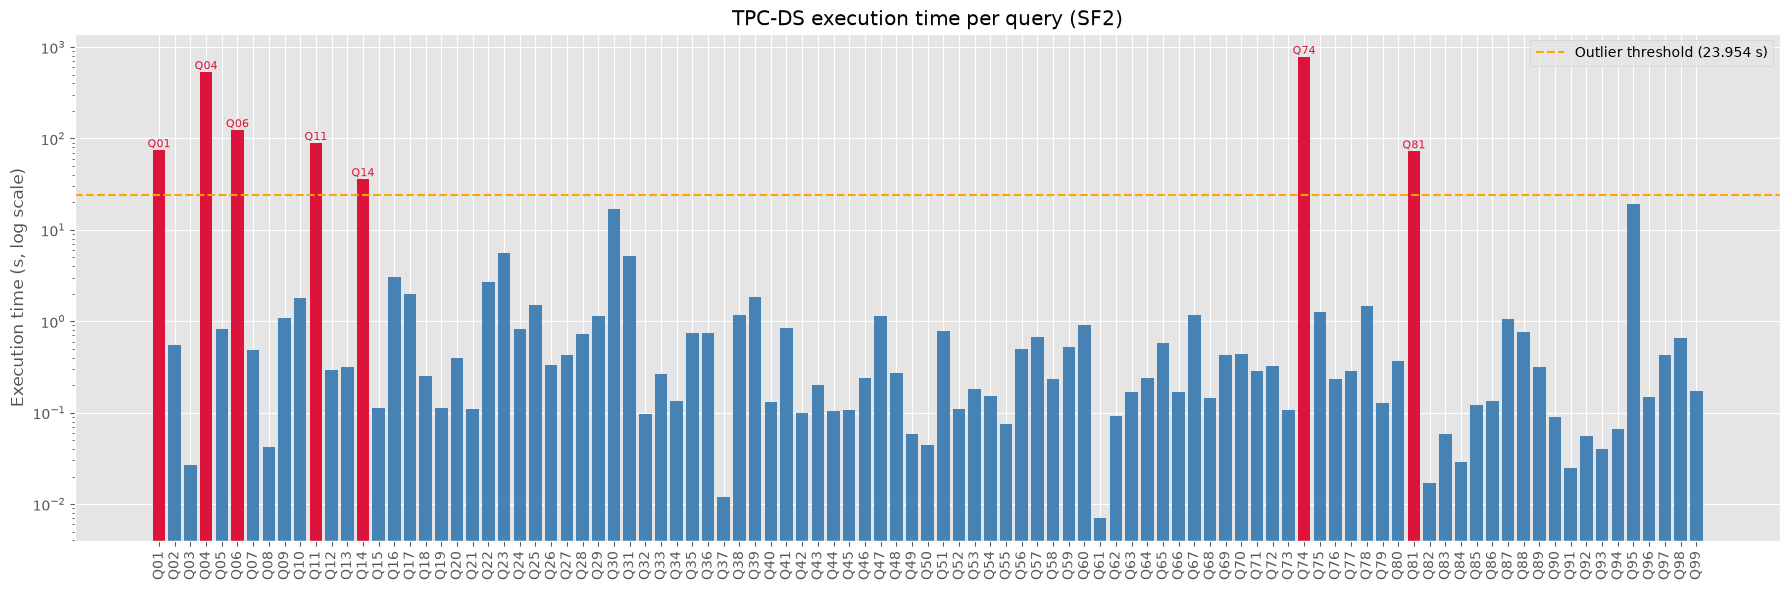

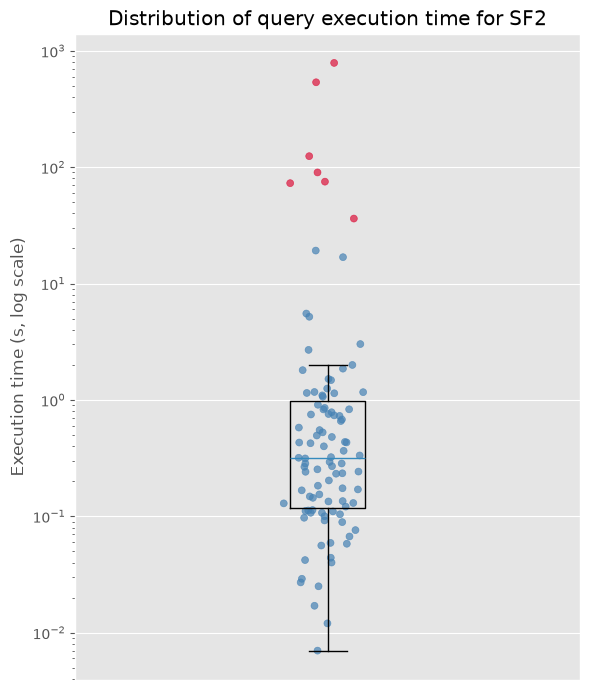


Scale Factor 5
Upper fence: 45.077 s | Lower fence: 0.027 s
query  median_exec_time
  Q04          4934.266
  Q74          4537.976
  Q06           602.195
  Q01           486.684
  Q81           461.990
  Q95           197.480
  Q11           184.014
  Q30           106.186
  Q14            88.809
  Q37             0.020
  Q61             0.011


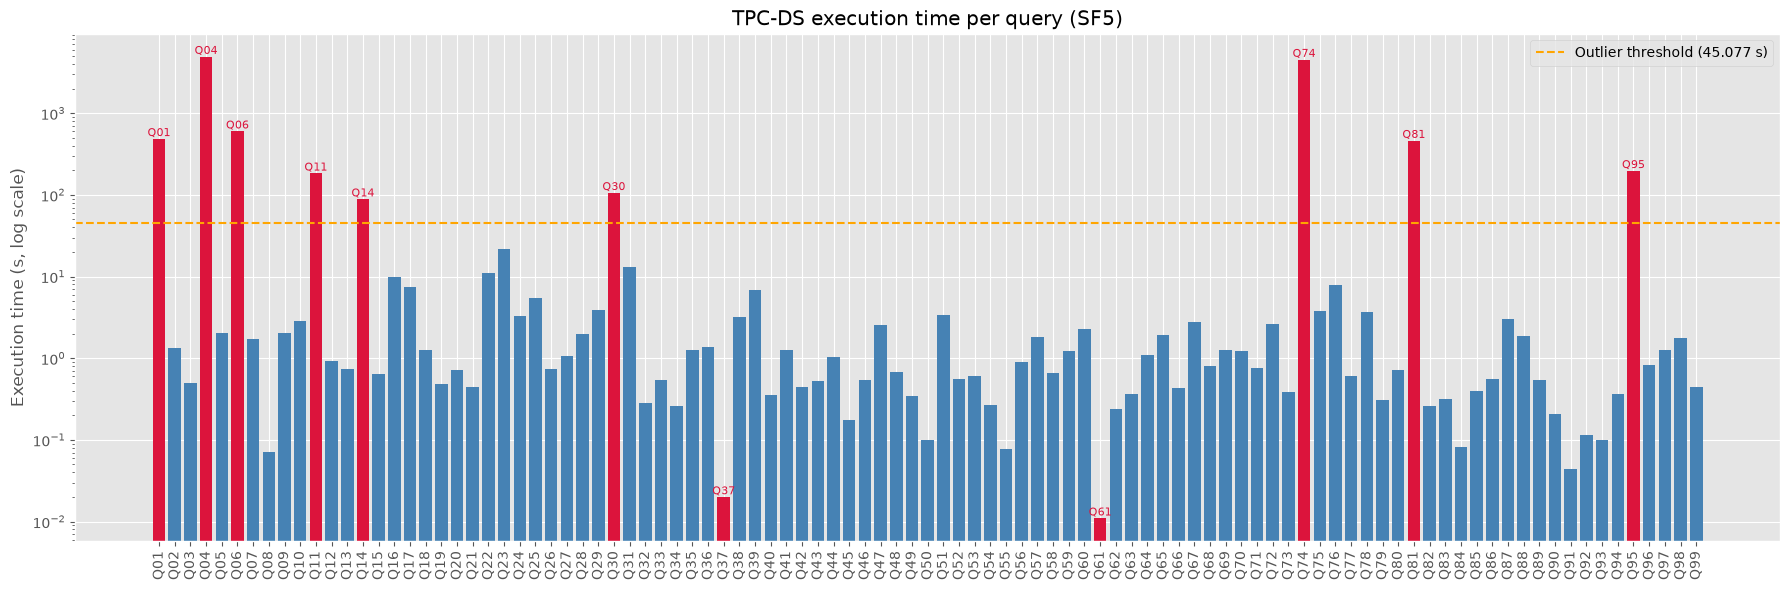

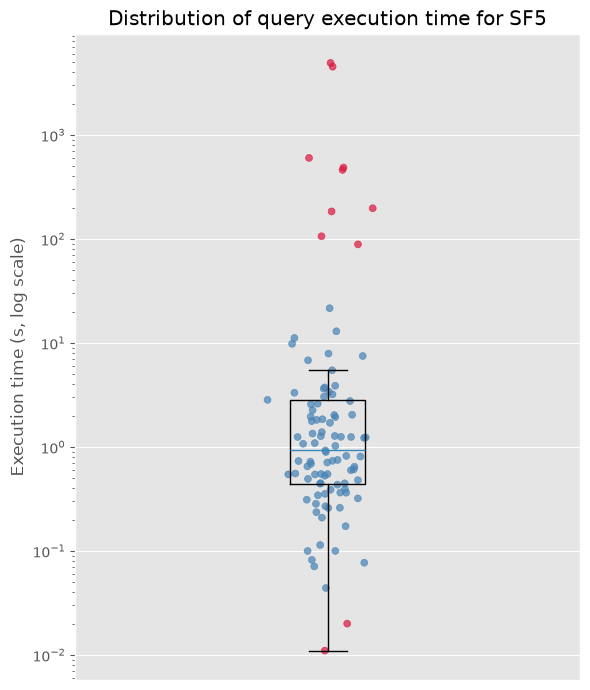

In [11]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Scale factors
scale_factors = [1, 2, 5]

for sf in scale_factors:

    print(f"\n{'='*50}")
    print(f"Scale Factor {sf}")
    print(f"{'='*50}")

    # --- Load ---
    file_path = f"./benchmarks/sf{sf}/results_no_timeout/exec_time_details.csv"

    df = pd.read_csv(file_path)
    df = df[df["status"] == "SUCCESS"].copy()

    # Use the median time (same as run_1 if you only ran once)
    col = "median_exec_time"
    df["log_t"] = np.log10(df[col])

    # --- Outlier detection: IQR on log scale ---
    q1, q3 = df["log_t"].quantile([0.25, 0.75])
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    lower = q1 - 1.5 * iqr

    df["outlier"] = (df["log_t"] > upper) | (df["log_t"] < lower)

    print(f"Upper fence: {10**upper:.3f} s | Lower fence: {10**lower:.3f} s")
    print(df.loc[df["outlier"], ["query", col]]
            .sort_values(col, ascending=False)
            .to_string(index=False))

    # --- Plot 1: bar chart per query ---
    fig, ax = plt.subplots(figsize=(18, 6))
    colors = np.where(df["outlier"], "crimson", "steelblue")

    ax.bar(df["query"], df[col], color=colors)
    ax.set_yscale("log")
    ax.axhline(10**upper, color="orange", ls="--",
               label=f"Outlier threshold ({10**upper:.3f} s)")
    ax.set_ylabel("Execution time (s, log scale)")
    ax.set_title(f"TPC-DS execution time per query (SF{sf})")
    ax.tick_params(axis="x", rotation=90)

    for _, r in df[df["outlier"]].iterrows():
        ax.annotate(r["query"], (r["query"], r[col]),
                    ha="center", va="bottom", fontsize=8, color="crimson")

    ax.legend()
    plt.tight_layout()
    plt.show()

    # --- Plot 2: boxplot (log scale) with outlier points labeled ---
    fig, ax = plt.subplots(figsize=(6, 7))
    ax.boxplot(df[col], whis=1.5, showfliers=False)

    ax.scatter(np.random.normal(1, 0.04, len(df)), df[col],
               c=colors, alpha=0.7, s=25)

    ax.set_yscale("log")
    ax.set_ylabel("Execution time (s, log scale)")
    ax.set_xticks([])
    ax.set_title(f"Distribution of query execution time for SF{sf}")

    plt.tight_layout()
    plt.show()


In [5]:
import pandas as pd

# Path to the execution time CSV
file_path = "benchmarks/sf10/results-baseline-original-without-timeout/exec_time_details.csv"

# Read the CSV file
df = pd.read_csv(file_path)

# Display available columns
print("Columns:", df.columns.tolist())

# Sort queries by execution time (slowest first)
df = df.sort_values(by="avg_exec_time", ascending=False)

# Get the 20 slowest queries
slowest_20 = df.head(20)

# Display results
print("\nTop 20 Slowest Queries (SF10 Baseline):")
print(slowest_20.to_string(index=False))

Columns: ['query', 'status', 'exec_time_run_1', 'avg_exec_time', 'median_exec_time', 'min_exec_time', 'max_exec_time', 'error']

Top 20 Slowest Queries (SF10 Baseline):
query  status  exec_time_run_1  avg_exec_time  median_exec_time  min_exec_time  max_exec_time  error
  Q74 SUCCESS        14910.551      14910.551         14910.551      14910.551      14910.551    NaN
  Q04 SUCCESS         7834.531       7834.531          7834.531       7834.531       7834.531    NaN
  Q06 SUCCESS         2311.894       2311.894          2311.894       2311.894       2311.894    NaN
  Q01 SUCCESS         1900.796       1900.796          1900.796       1900.796       1900.796    NaN
  Q30 SUCCESS          417.729        417.729           417.729        417.729        417.729    NaN
  Q95 SUCCESS          356.683        356.683           356.683        356.683        356.683    NaN
  Q81 SUCCESS          336.430        336.430           336.430        336.430        336.430    NaN
  Q11 SUCCESS          

Number of queries: 99


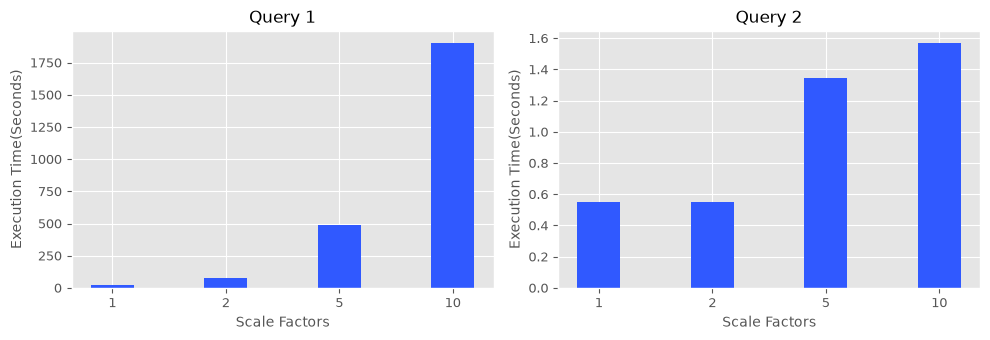

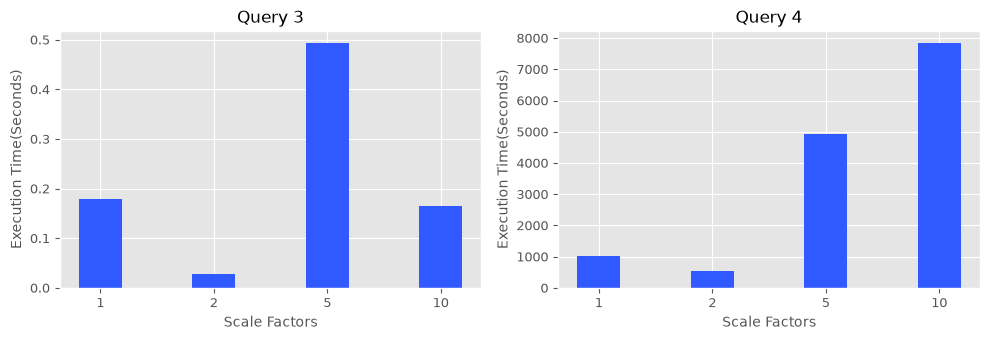

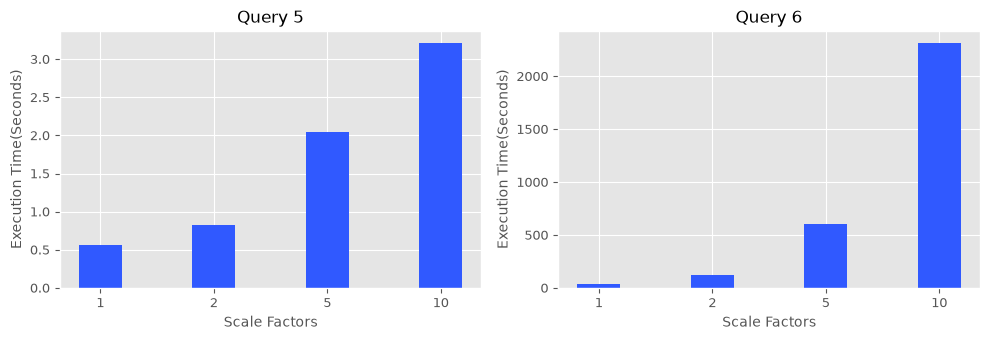

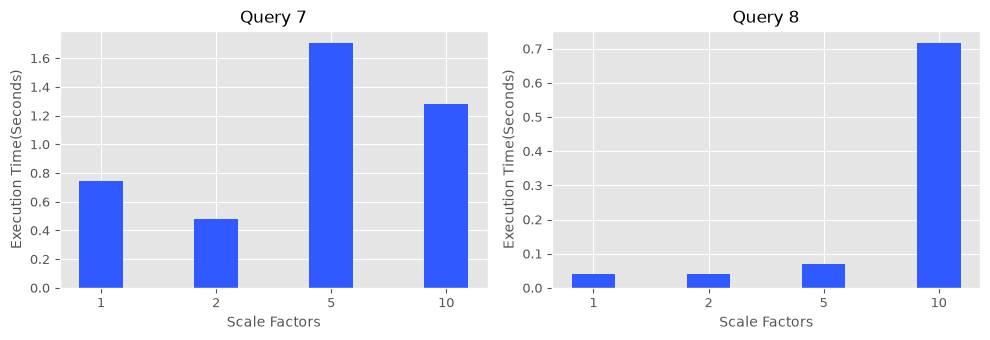

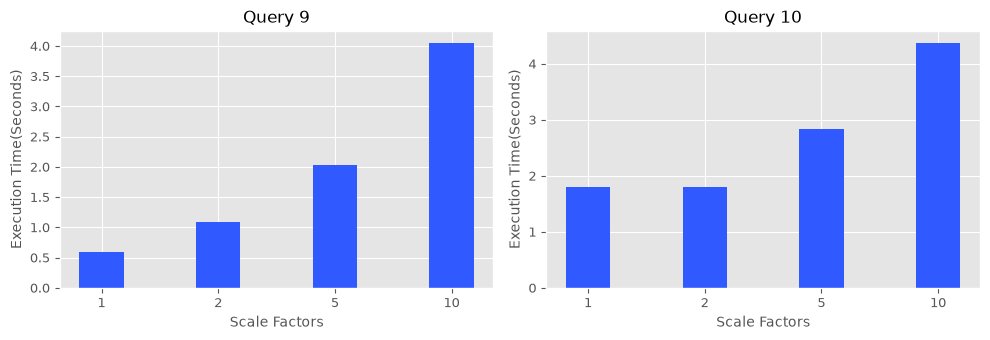

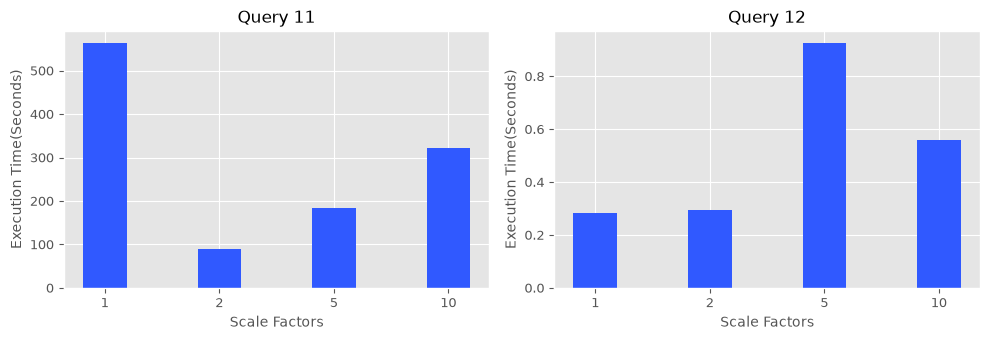

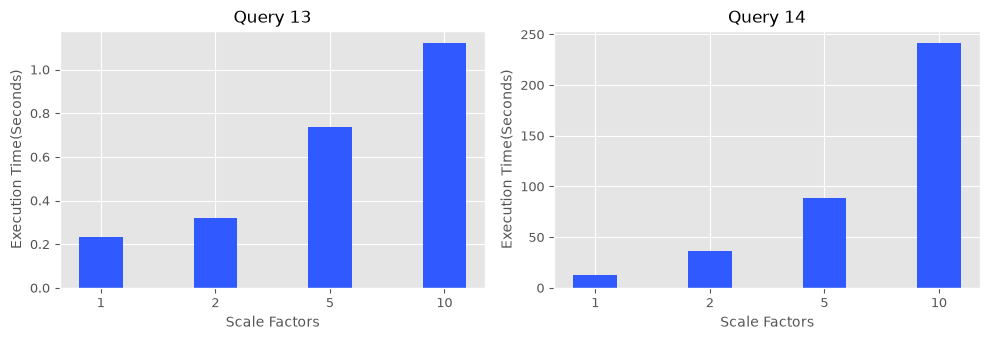

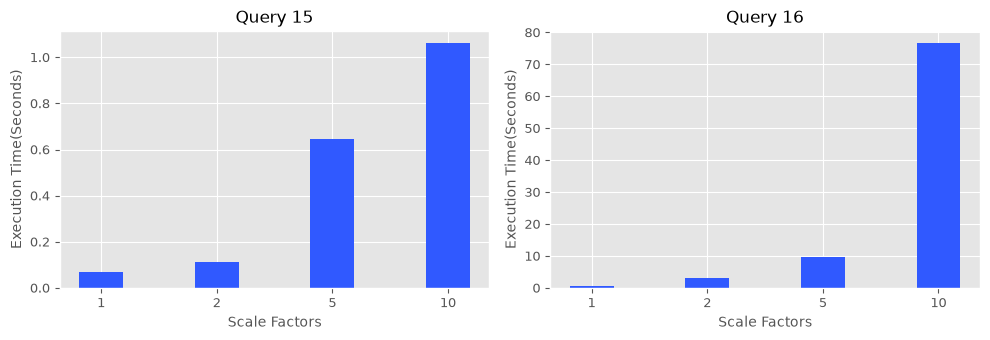

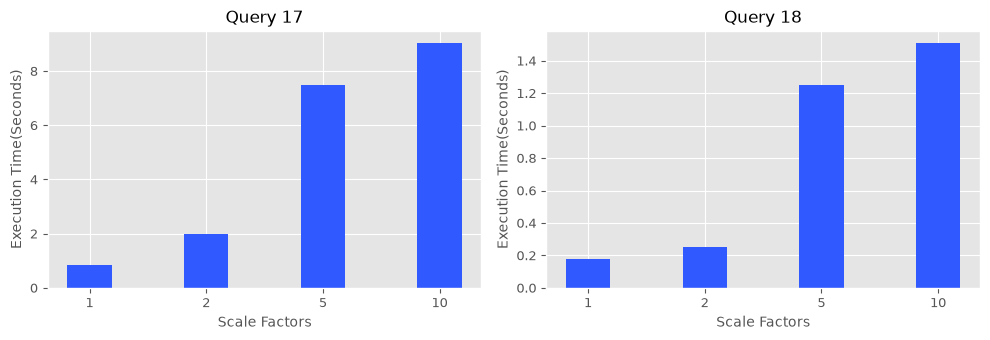

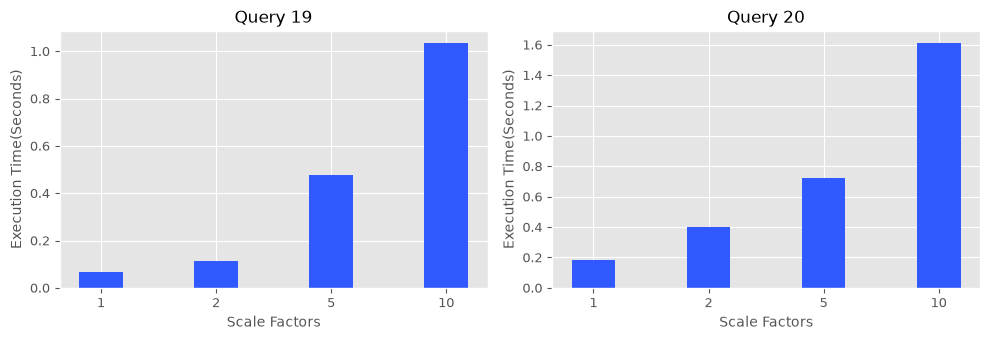

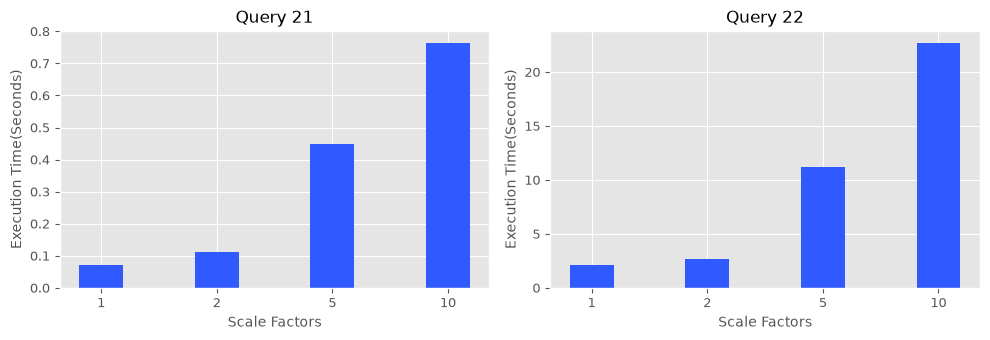

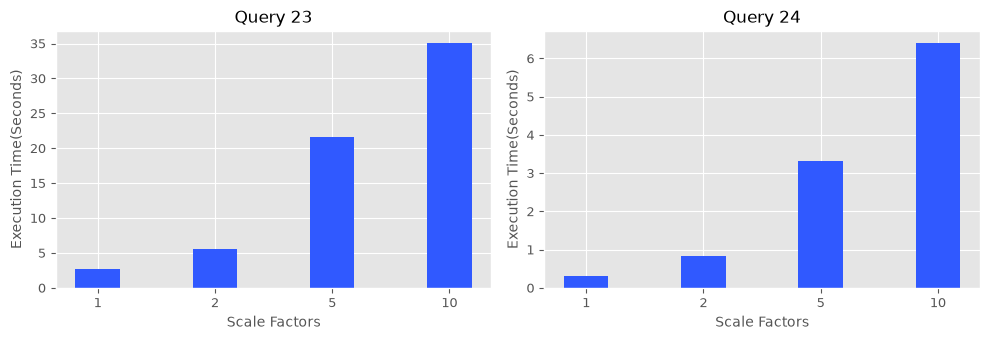

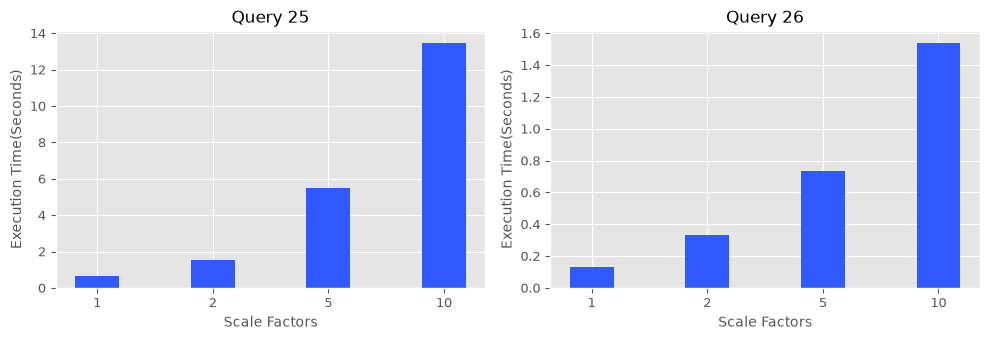

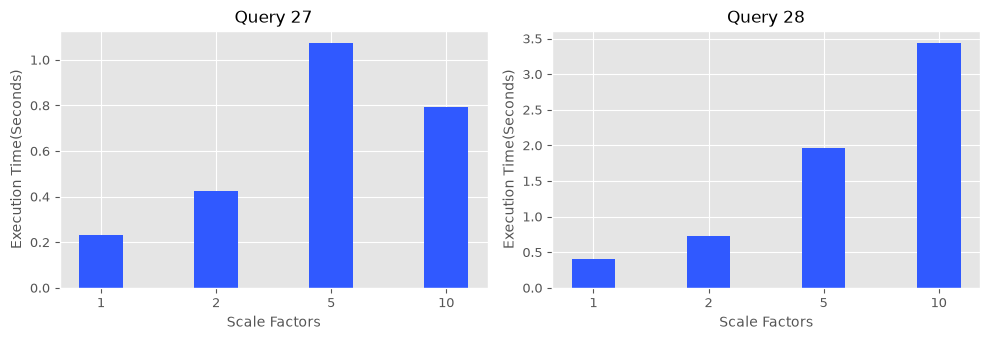

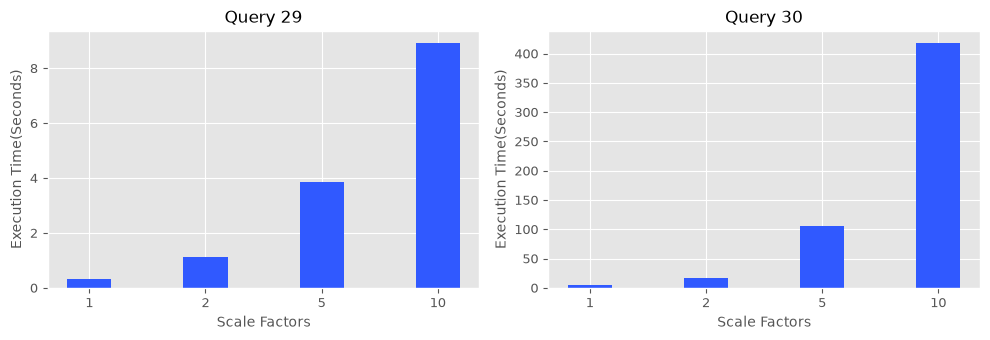

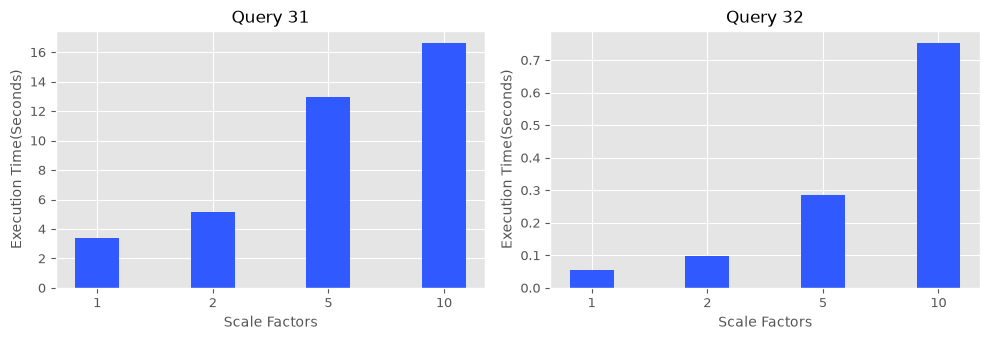

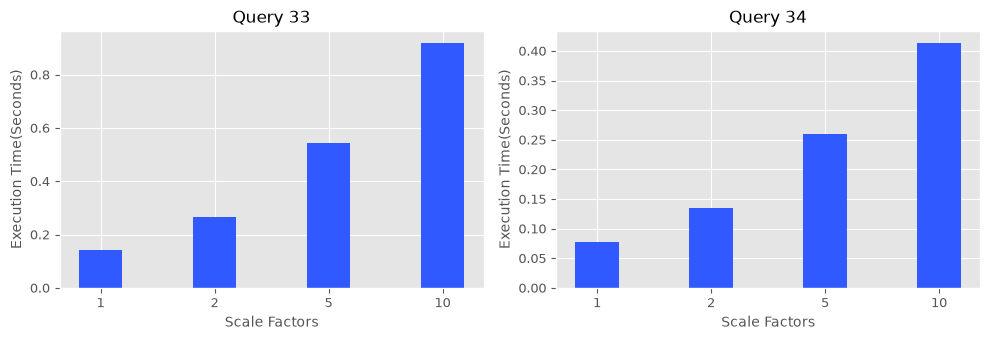

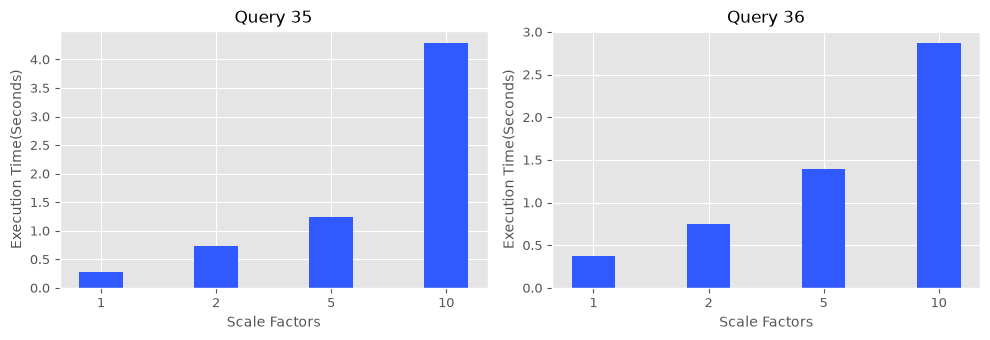

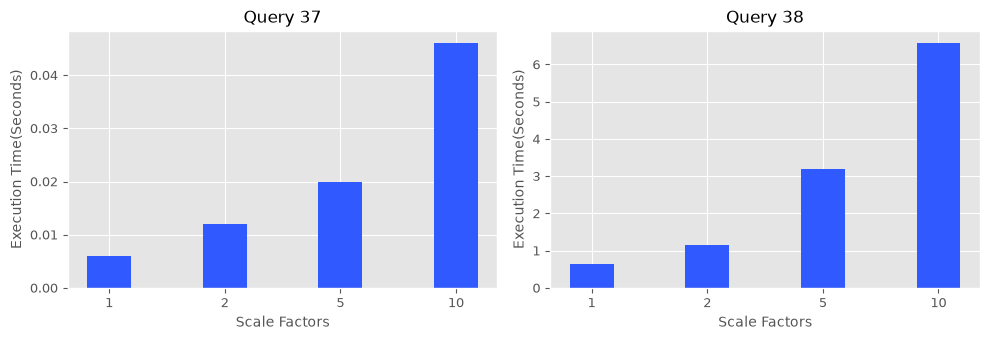

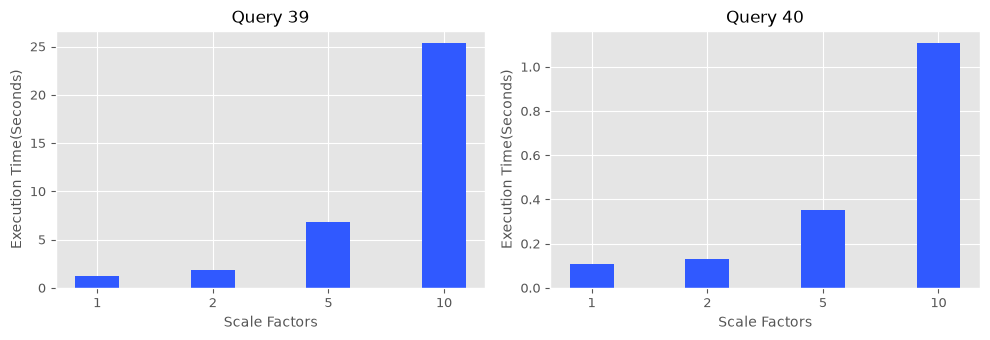

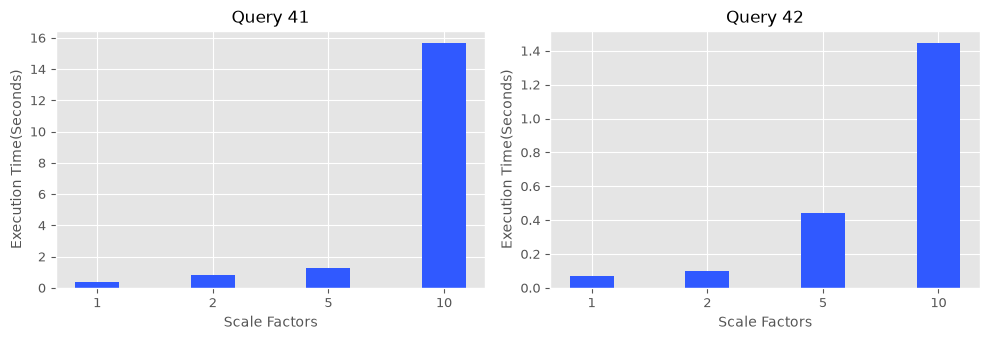

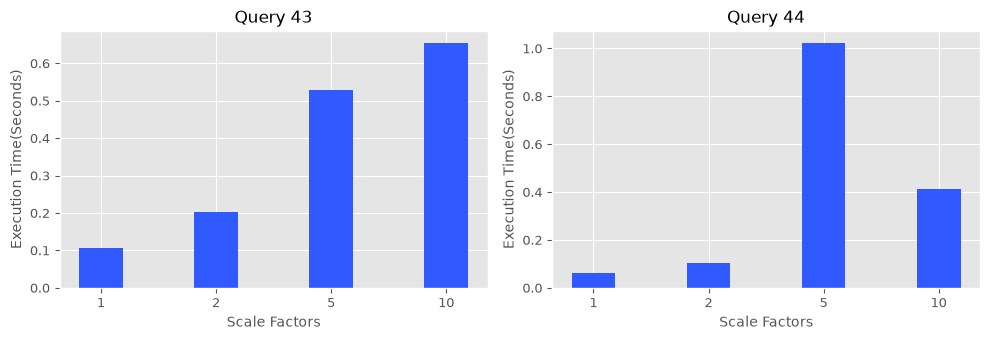

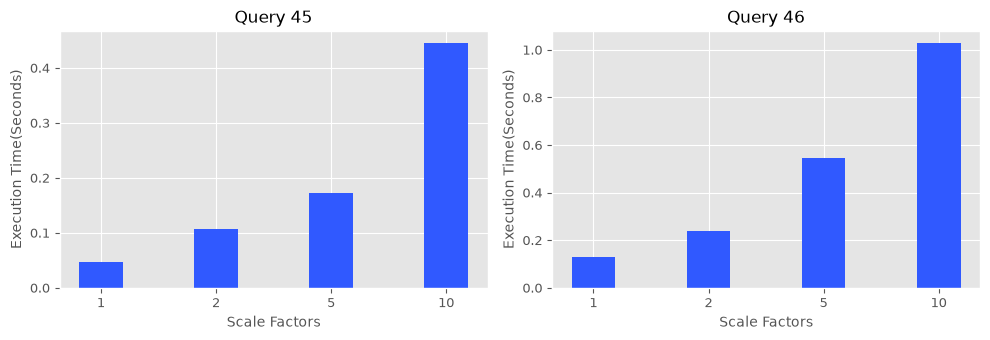

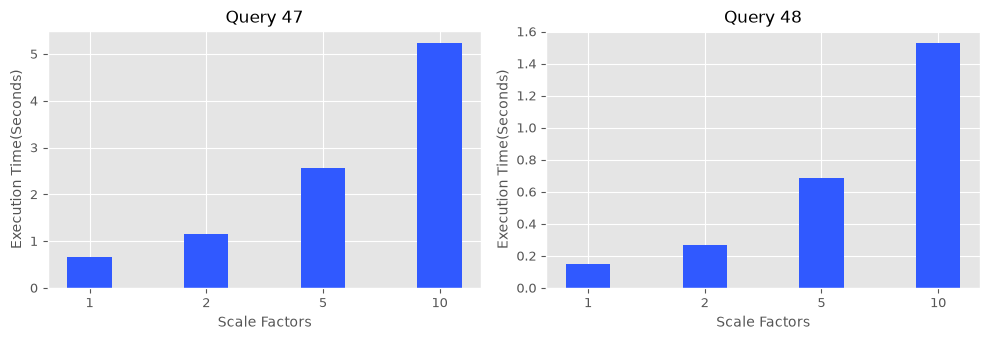

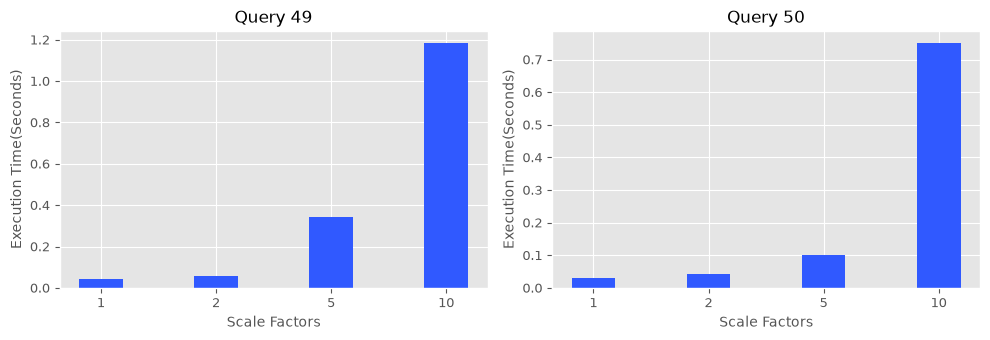

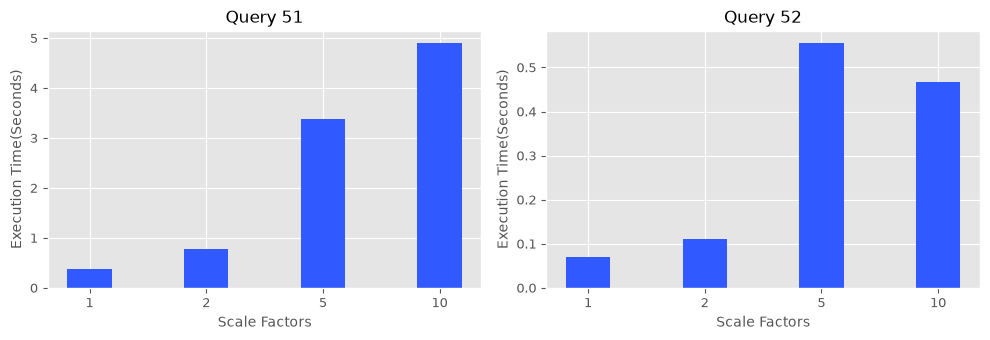

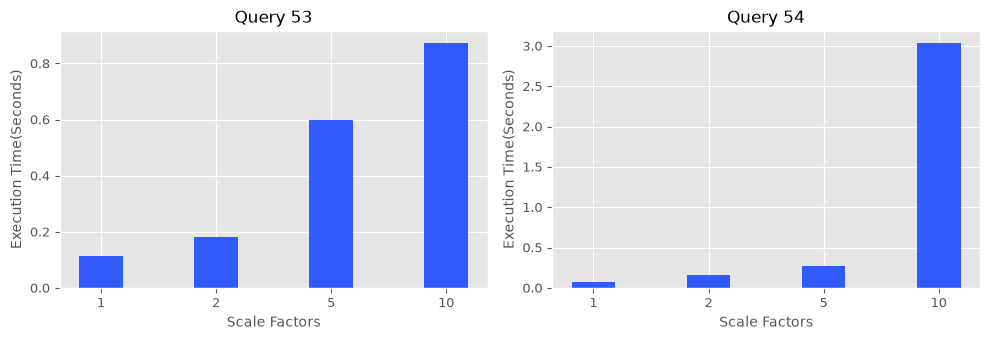

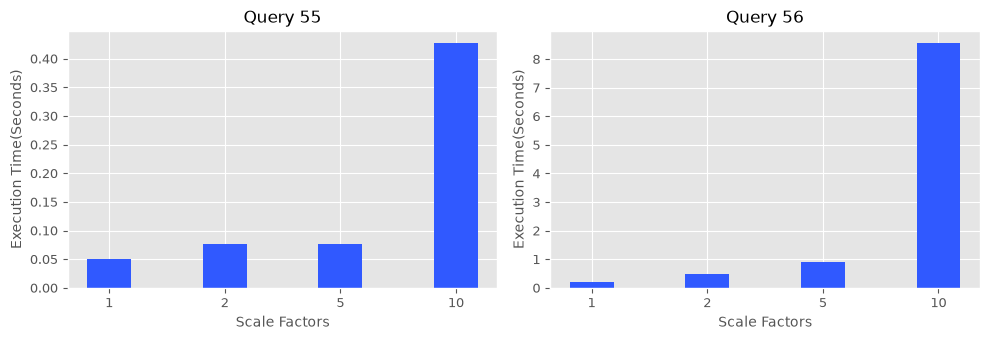

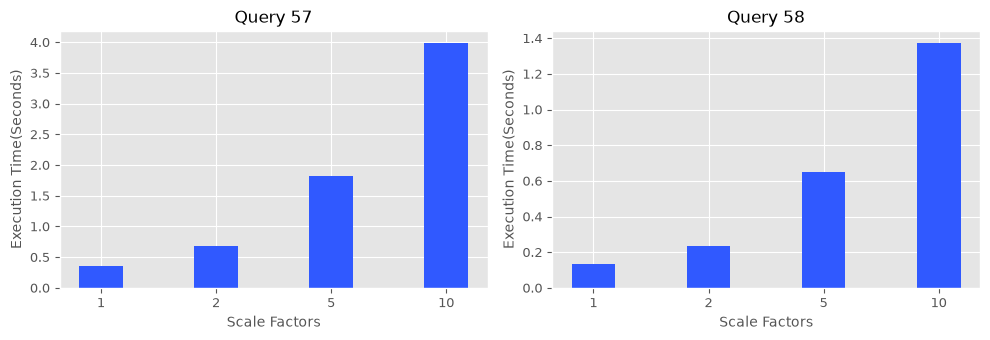

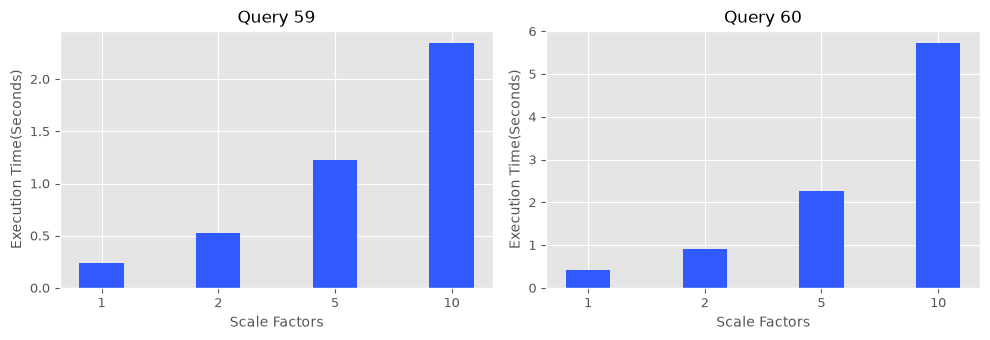

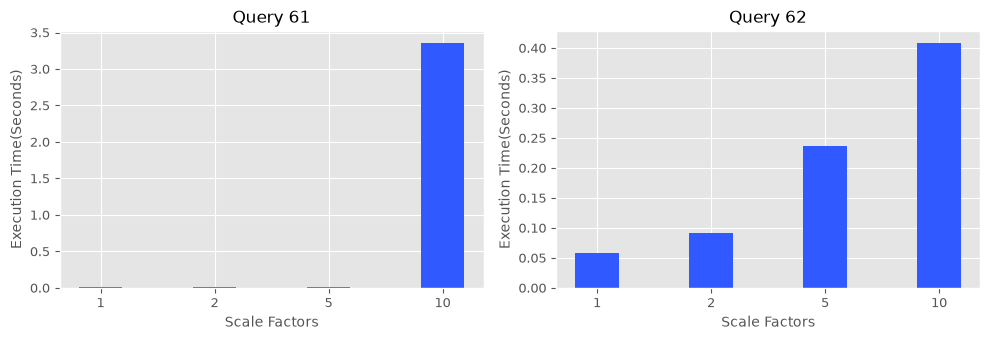

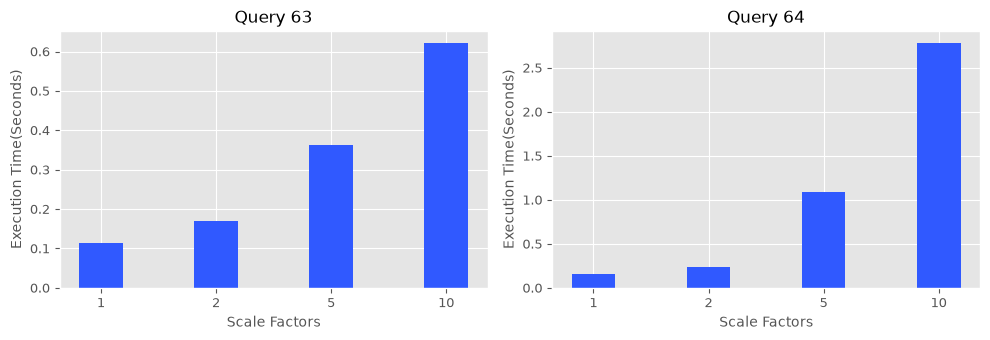

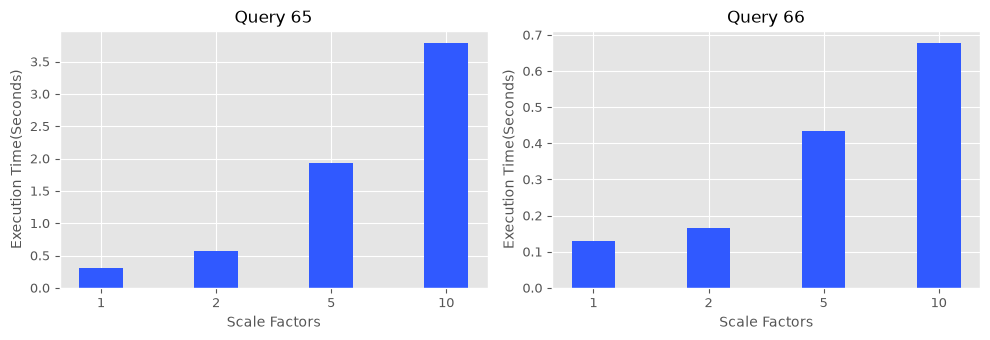

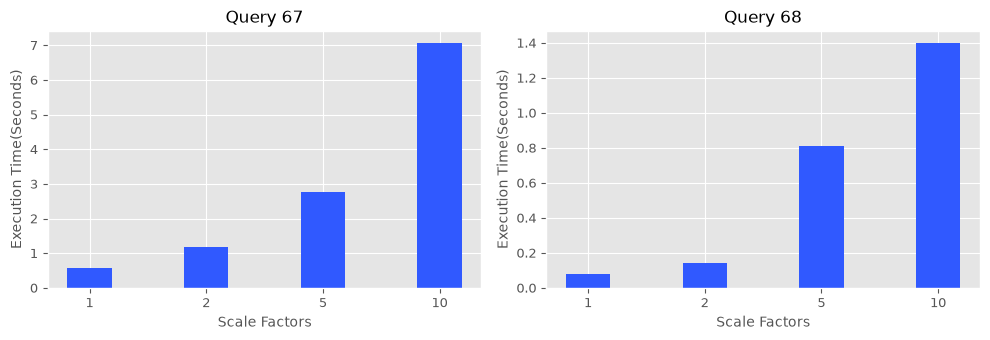

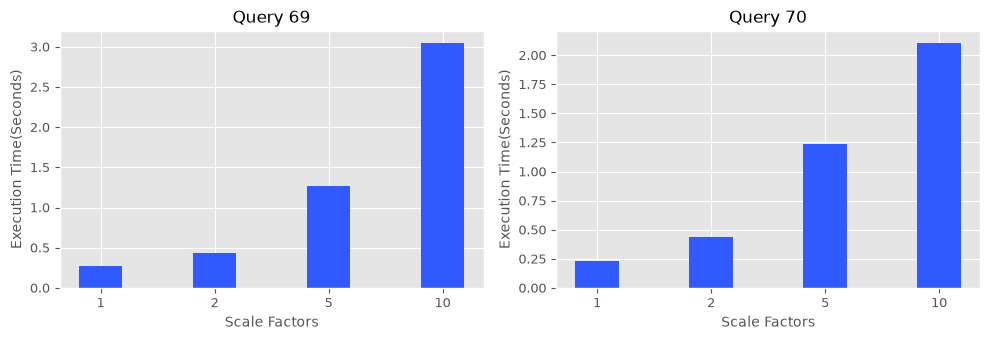

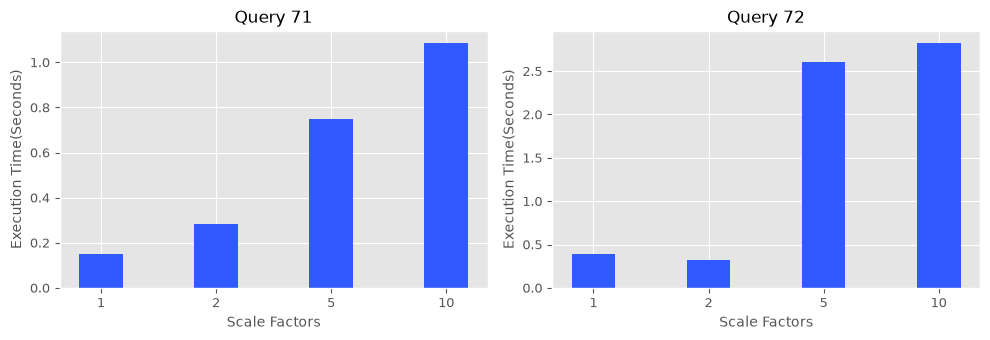

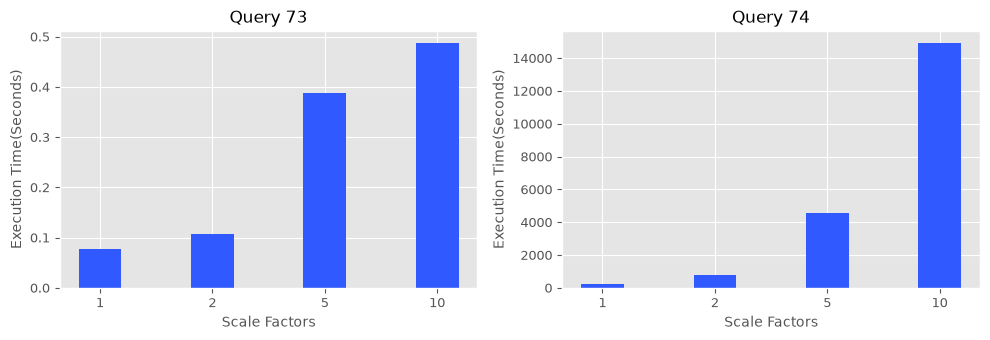

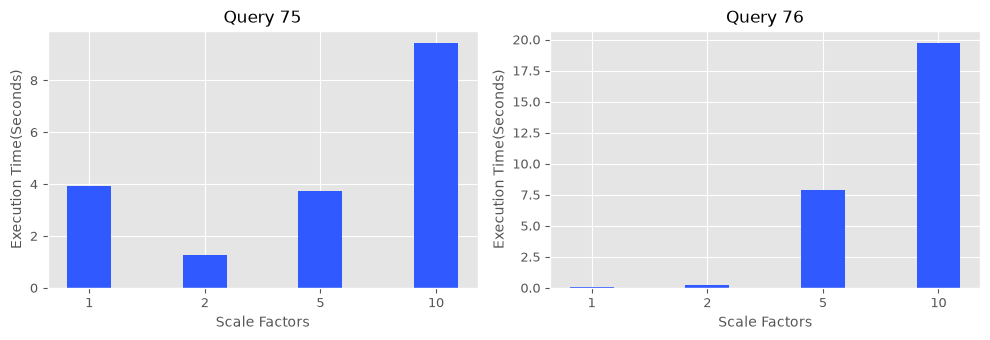

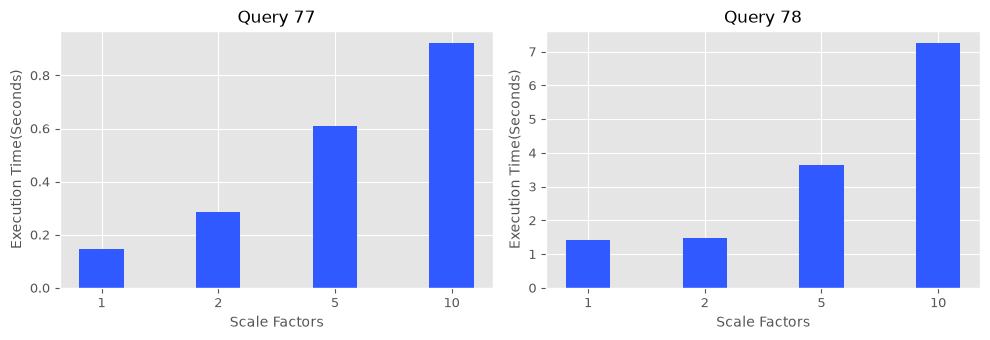

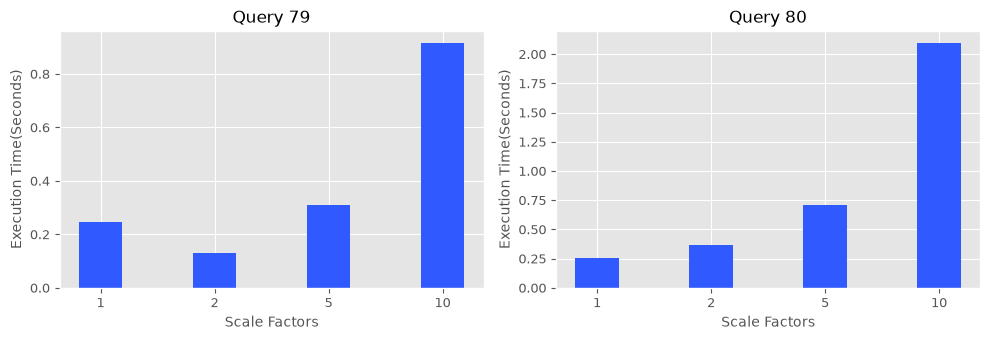

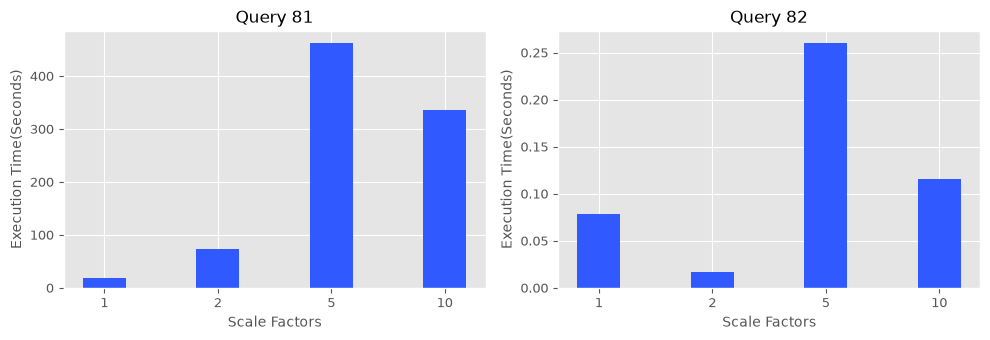

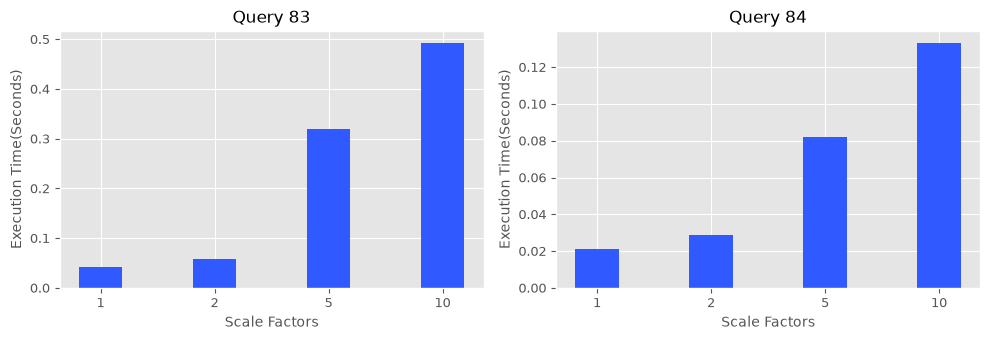

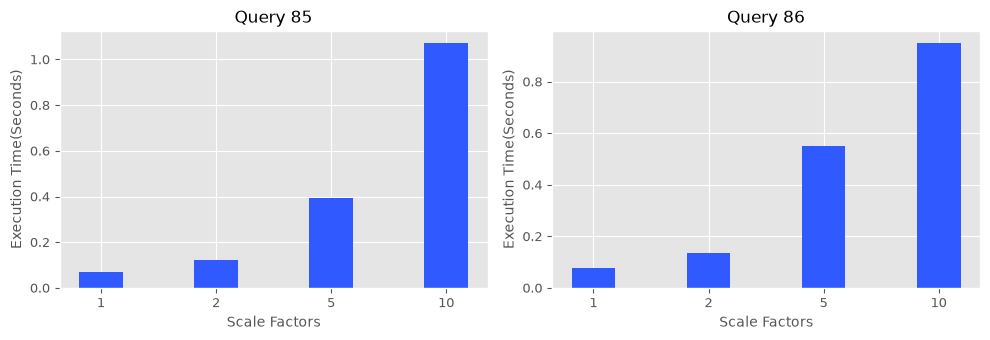

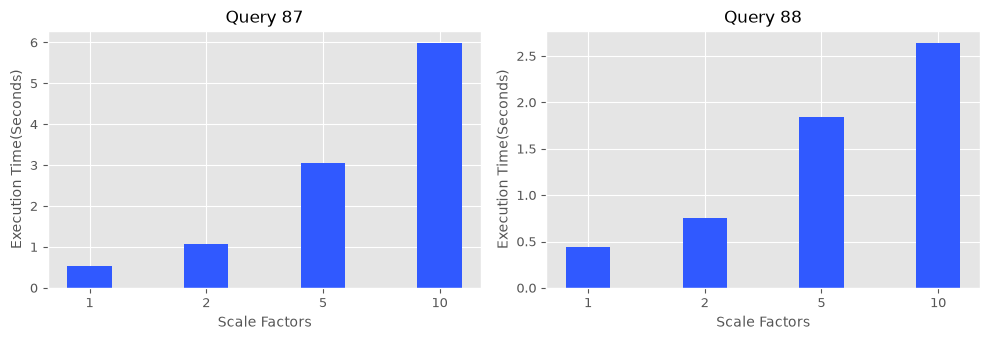

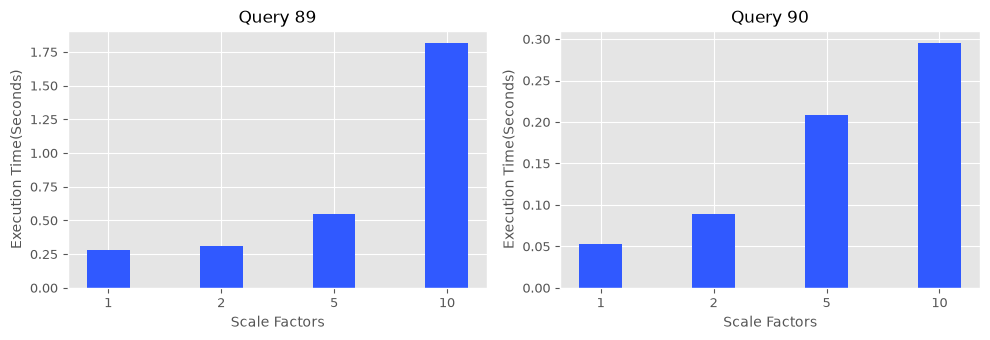

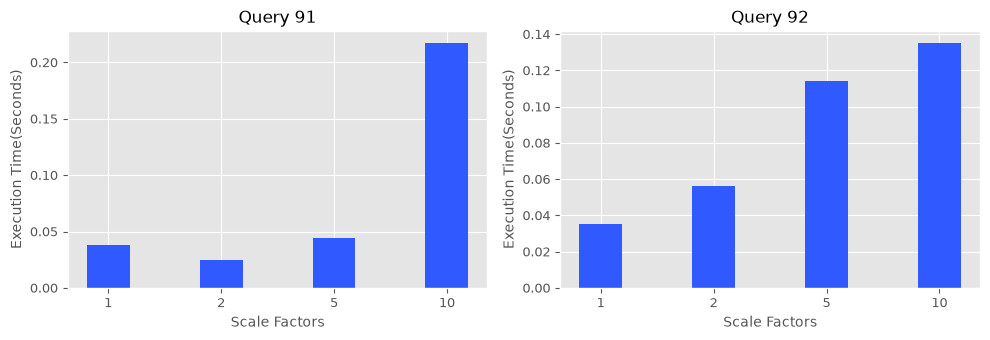

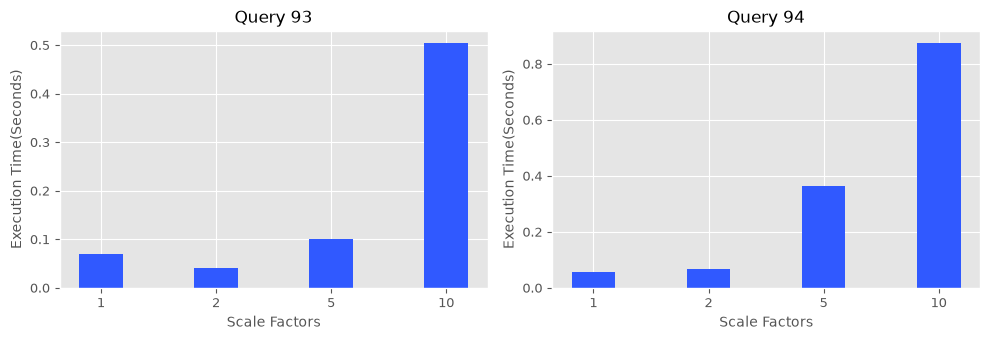

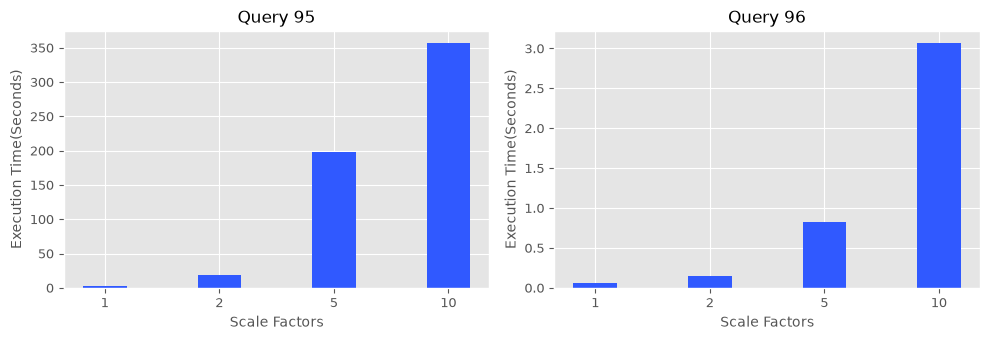

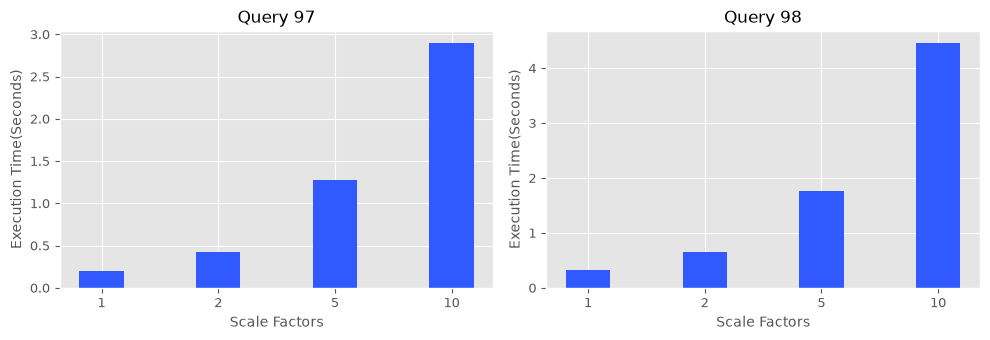

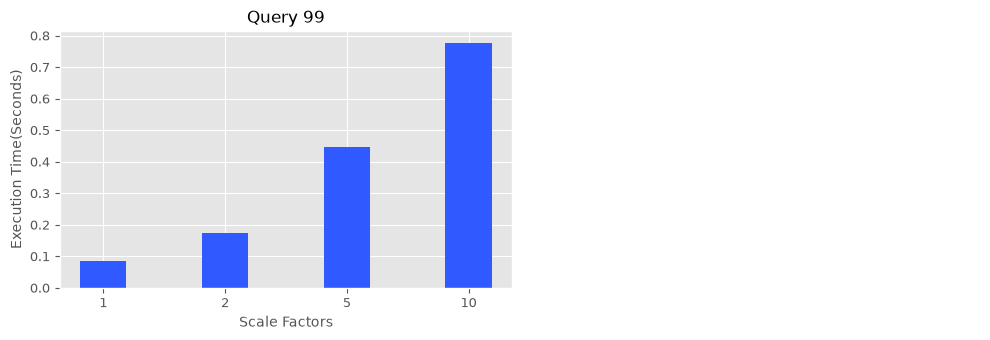

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Same visual style as your screenshot
plt.style.use("ggplot")

# ==========================================
# 1. CSV FILE PATHS
# ==========================================

files = {
    1: "benchmarks/sf1/results_no_timeout/exec_time_details.csv",
    2: "benchmarks/sf2/results_no_timeout/exec_time_details.csv",
    5: "benchmarks/sf5/results_no_timeout/exec_time_details.csv",
    10: "benchmarks/sf10/results-baseline-original-without-timeout/exec_time_details.csv"
}

excluded_queries = {}
scale_factors = [1, 2, 5, 10]

output_dir = Path("plots/query_scaling")
output_dir.mkdir(parents=True, exist_ok=True)

# ==========================================
# 2. LOAD DATA
# ==========================================

all_data = []

for sf, path in files.items():

    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()

    df["query_num"] = pd.to_numeric(
        df["query"].astype(str).str.extract(r"(\d+)")[0],
        errors="coerce"
    )

    df["avg_exec_time"] = pd.to_numeric(
        df["avg_exec_time"],
        errors="coerce"
    )

    df = df[
        ~df["query_num"].isin(excluded_queries)
        & (df["status"].astype(str).str.upper() == "SUCCESS")
    ].copy()

    df["scale_factor"] = sf

    all_data.append(
        df[["query_num", "scale_factor", "avg_exec_time"]]
    )

combined = pd.concat(all_data, ignore_index=True)

comparison = combined.pivot_table(
    index="query_num",
    columns="scale_factor",
    values="avg_exec_time"
)

comparison = comparison.reindex(columns=scale_factors)

# Keep only queries with data at all 4 scale factors
missing = comparison[comparison.isna().any(axis=1)].index.tolist()
if missing:
    print("Queries with incomplete data:", missing)

comparison = comparison.dropna().sort_index()

queries = comparison.index.astype(int).tolist()

print(f"Number of queries: {len(queries)}")

# ==========================================
# 3. PLOT EXACTLY LIKE THE SCREENSHOT
# ==========================================

for i in range(0, len(queries), 2):

    pair = queries[i:i+2]

    fig, axes = plt.subplots(
        1, 2,
        figsize=(10, 3.5)
    )

    for j, q in enumerate(pair):

        ax = axes[j]

        times = comparison.loc[q, scale_factors].values

        x = np.arange(len(scale_factors))

        ax.bar(
            x,
            times,
            color="#3059FF",
            width=0.38
        )

        ax.set_title(f"Query {q}", fontsize=12)
        ax.set_xlabel("Scale Factors", fontsize=10)
        ax.set_ylabel("Execution Time(Seconds)", fontsize=10)

        ax.set_xticks(x)
        ax.set_xticklabels(scale_factors)

        ax.set_ylim(bottom=0)

        ax.tick_params(axis="both", labelsize=9)

    if len(pair) == 1:
        axes[1].axis("off")

    plt.tight_layout()

    filename = output_dir / (
        f"queries_{'_'.join(f'Q{q:02d}' for q in pair)}.png"
    )

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


In [3]:
import numpy as np
import pandas as pd

# ==========================================
# 1. CONFIGURATION
# ==========================================

R2_THRESHOLD = 0.90
MODEL_DIFFERENCE = 0.05
DROP_TOLERANCE = 0.05

x = np.array(scale_factors, dtype=float)

# ==========================================
# 2. HELPER FUNCTIONS
# ==========================================

def calculate_r2(actual, predicted):
    ss_res = np.sum((actual - predicted) ** 2)
    ss_tot = np.sum((actual - np.mean(actual)) ** 2)

    if ss_tot < 1e-20:
        return 0.0

    return 1 - ss_res / ss_tot


def fit_linear(x, y):
    coefficients = np.polyfit(x, y, 1)
    predicted = np.polyval(coefficients, x)
    return calculate_r2(y, predicted)


def fit_exponential(x, y):
    # Fit y = a * exp(b * (x - x.min()))
    # Search for b and optimize a using least squares.
    rates = np.linspace(0, 2, 2001)

    exponential_terms = np.exp(
        rates[:, None] * (x - x.min())
    )

    amplitudes = (
        exponential_terms @ y
    ) / np.sum(exponential_terms ** 2, axis=1)

    predictions = amplitudes[:, None] * exponential_terms

    errors = np.sum((predictions - y) ** 2, axis=1)

    best_index = np.argmin(errors)

    return calculate_r2(y, predictions[best_index])


# ==========================================
# 3. CLASSIFY EACH QUERY
# ==========================================

results = []

for query in comparison.index:

    y = comparison.loc[query, scale_factors].to_numpy(
        dtype=float
    )

    linear_r2 = fit_linear(x, y)
    exponential_r2 = fit_exponential(x, y)

    # Significant decreases indicate irregular scaling
    significant_drop = np.any(
        y[1:] < y[:-1] * (1 - DROP_TOLERANCE)
    )

    if significant_drop or y[-1] <= y[0] * 1.10:
        pattern = "Irregular"

    elif max(linear_r2, exponential_r2) < R2_THRESHOLD:
        pattern = "Irregular"

    elif (
        exponential_r2 >= R2_THRESHOLD
        and exponential_r2 - linear_r2 >= MODEL_DIFFERENCE
    ):
        pattern = "Exponential"

    elif linear_r2 >= R2_THRESHOLD:
        pattern = "Linear"

    else:
        pattern = "Irregular"

    results.append({
        "Query": f"Q{int(query):02d}",
        "Pattern": pattern,
        "Linear_R2": round(linear_r2, 4),
        "Exponential_R2": round(exponential_r2, 4)
    })

results_df = pd.DataFrame(results)

# ==========================================
# 4. PRINT COUNTS
# ==========================================

counts = results_df["Pattern"].value_counts().reindex(
    ["Linear", "Exponential", "Irregular"],
    fill_value=0
)

print("QUERY SCALING PATTERNS")
print("=" * 40)

for pattern, count in counts.items():
    percentage = count / len(results_df) * 100
    print(f"{pattern:12s}: {count:3d} queries ({percentage:.1f}%)")

print("=" * 40)
print(f"Total analyzed: {len(results_df)}")

# ==========================================
# 5. PRINT QUERIES IN EACH CATEGORY
# ==========================================

for pattern in ["Linear", "Exponential", "Irregular"]:

    query_list = results_df.loc[
        results_df["Pattern"] == pattern, "Query"
    ].tolist()

    print(f"\n{pattern.upper()} QUERIES:")
    print(", ".join(query_list) if query_list else "None")

# ==========================================
# 6. SAVE DETAILED RESULTS
# ==========================================

results_df.to_csv(
    output_dir / "query_scaling_classification.csv",
    index=False
)

display(results_df)

QUERY SCALING PATTERNS
Linear      :  69 queries (69.7%)
Exponential :   9 queries (9.1%)
Irregular   :  21 queries (21.2%)
Total analyzed: 99

LINEAR QUERIES:
Q01, Q05, Q06, Q09, Q10, Q13, Q14, Q15, Q19, Q20, Q21, Q22, Q23, Q24, Q25, Q26, Q28, Q29, Q30, Q31, Q32, Q33, Q34, Q35, Q36, Q37, Q38, Q39, Q40, Q42, Q45, Q46, Q47, Q48, Q49, Q51, Q53, Q57, Q58, Q59, Q60, Q62, Q63, Q64, Q65, Q66, Q67, Q68, Q69, Q70, Q71, Q74, Q76, Q77, Q78, Q80, Q83, Q84, Q85, Q86, Q87, Q88, Q90, Q94, Q95, Q96, Q97, Q98, Q99

EXPONENTIAL QUERIES:
Q08, Q16, Q41, Q50, Q54, Q55, Q56, Q61, Q89

IRREGULAR QUERIES:
Q02, Q03, Q04, Q07, Q11, Q12, Q17, Q18, Q27, Q43, Q44, Q52, Q72, Q73, Q75, Q79, Q81, Q82, Q91, Q92, Q93


,Query,Pattern,Linear_R2,Exponential_R2
0,Q01,Linear,0.9608,0.9900
1,Q02,Irregular,0.8674,0.7925
2,Q03,Irregular,0.0366,0.0265
3,Q04,Irregular,0.9428,0.8600
4,Q05,Linear,0.9837,0.9201
...,...,...,...,...
94,Q95,Linear,0.9791,0.8800
95,Q96,Linear,0.9622,0.9907
96,Q97,Linear,0.9977,0.9698
97,Q98,Linear,0.9903,0.9835


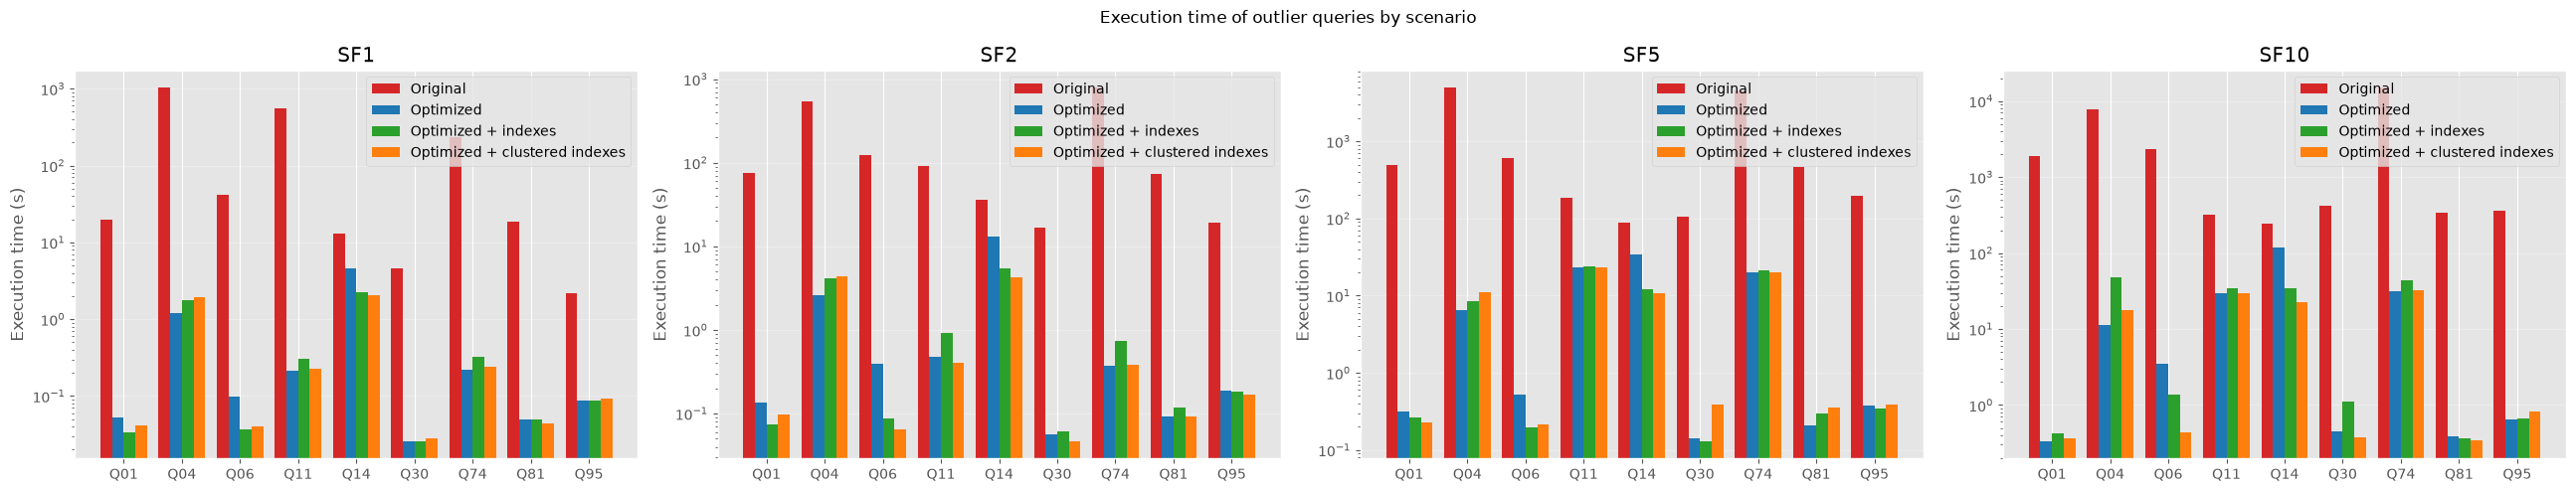

In [7]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------ CONFIG
OUTLIER_QUERIES = [1, 4, 6, 11, 14, 30, 74, 81, 95]          # <- your list of query numbers

# scale factor -> {scenario label: csv path}
FILES = {
        "SF1": {
        "Original":            "./benchmarks/sf1/results_no_timeout/exec_time_details.csv",
        "Optimized":           "./benchmarks/sf1/results_optimization/exec_time_details.csv",
        "Optimized + indexes": "./benchmarks/sf1/results_optimization_index/exec_time_details.csv",
        "Optimized + clustered indexes": "./benchmarks/sf1/results_clustered_indexes/exec_time_details.csv",
        
    },
        "SF2": {
        "Original":            "./benchmarks/sf2/results_no_timeout/exec_time_details.csv",
        "Optimized":           "./benchmarks/sf2/results_optimization/exec_time_details.csv",
        "Optimized + indexes": "./benchmarks/sf2/results_optimization_index/exec_time_details.csv",
        "Optimized + clustered indexes": "./benchmarks/sf2/results_clustered_indexes/exec_time_details.csv",
        
    },
    "SF5": {
            "Original":            "./benchmarks/sf5/results_no_timeout/exec_time_details.csv",
            "Optimized":           "./benchmarks/sf5/results_optimization/exec_time_details.csv",
            "Optimized + indexes": "./benchmarks/sf5/results_optimization_index/exec_time_details.csv",
            "Optimized + clustered indexes": "./benchmarks/sf5/results_clustered_indexes/exec_time_details.csv",
            
        },
    "SF10": {
        "Original":            "./benchmarks/sf10/results-baseline-original-without-timeout/exec_time_details.csv",
        "Optimized":           "./benchmarks/sf10/results_optimization/exec_time_details.csv",
        "Optimized + indexes": "./benchmarks/sf10/results_optimization_index/exec_time_details.csv",
        "Optimized + clustered indexes": "./benchmarks/sf10/results_clustered_indexes/exec_time_details.csv",

    },
}

QUERY_COL = None      # your query column name, or None to auto-detect
TIME_COL = None       # your time column name, or None to auto-detect
AGGREGATE = "median"  # if a query has several runs: "median", "mean", "min"
LOG_SCALE = True      # log y-axis; set False for linear
OUTPUT = "outlier_query_times.png"
# --------------------------------------------------------------------------

def find_col(df, override, keywords):
    if override:
        return override
    for c in df.columns:
        if any(k in c.lower() for k in keywords):
            return c
    raise ValueError(f"Can't auto-detect a column among {list(df.columns)}; "
                     "set QUERY_COL / TIME_COL.")

def query_number(value):
    m = re.search(r"\d+", str(value))      # 'Q04', 'query_04.sql', 4 -> 4
    return int(m.group()) if m else None

def load(path):
    df = pd.read_csv(path)
    q = find_col(df, QUERY_COL, ["query", "qid", "name"])
    t = find_col(df, TIME_COL, ["time", "exec", "duration", "elapsed", "seconds"])
    out = pd.DataFrame({"q": df[q].map(query_number),
                        "t": pd.to_numeric(df[t], errors="coerce")}).dropna()
    return out.groupby("q")["t"].agg(AGGREGATE)

n = len(FILES)
fig, axes = plt.subplots(1, n, figsize=(6.5 * n, 5), squeeze=False)
colors = ["#d62728", "#1f77b4", "#2ca02c", "#ff7f0e", "#9467bd"]

for ax, (sf, scenarios) in zip(axes[0], FILES.items()):
    data = pd.DataFrame({name: load(p) for name, p in scenarios.items()})
    data = data.reindex(OUTLIER_QUERIES)
    x = np.arange(len(data))
    w = 0.8 / len(scenarios)

    for i, (name, color) in enumerate(zip(data.columns, colors)):
        ax.bar(x + (i - (len(scenarios) - 1) / 2) * w, data[name], w,
               label=name, color=color)

    ax.set_xticks(x)
    ax.set_xticklabels([f"Q{int(q):02d}" for q in data.index])
    ax.set_title(sf)
    ax.set_ylabel("Execution time (s)")
    if LOG_SCALE:
        ax.set_yscale("log")
    ax.grid(axis="y", alpha=0.3)
    ax.legend()

    missing = data.index[data.isna().all(axis=1)].tolist()
    if missing:
        print(f"[{sf}] no data for queries: {missing}")

fig.suptitle("Execution time of outlier queries by scenario")
fig.tight_layout()
fig.savefig(OUTPUT, dpi=150)
plt.show()

Loaded: SF1 - Original
Loaded: SF1 - Optimized
Loaded: SF2 - Original
Loaded: SF2 - Optimized
Loaded: SF5 - Original
Loaded: SF5 - Optimized
Loaded: SF10 - Original
Loaded: SF10 - Optimized
Generated: query_comparison_plots/query_16_comparison.png


/var/folders/w5/_mbxz4k91djfvbp9r227lzsm0000gn/T/ipykernel_70457/3776346659.py:254: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax.set_ylim(bottom=0)


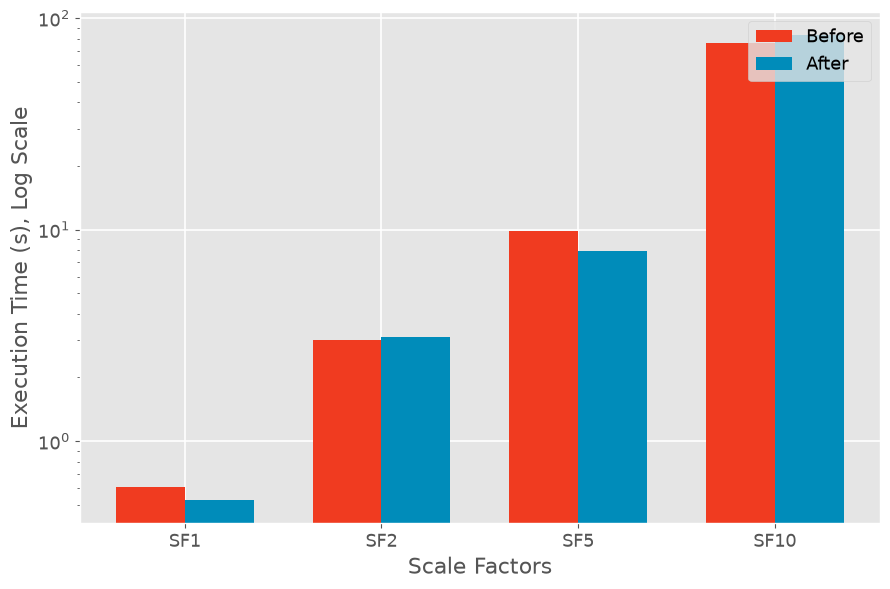


All query comparison plots have been generated!


In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import re

# ============================================================
# 1. FILE PATHS
# ============================================================

# Scale factor -> {scenario label: CSV path}
FILES = {
    "SF1": {
        "Original": "./benchmarks/sf1/results_no_timeout/exec_time_details.csv",
        "Optimized": "./benchmarks/sf1/results_optimization/exec_time_details.csv",
    },
    "SF2": {
        "Original": "./benchmarks/sf2/results_no_timeout/exec_time_details.csv",
        "Optimized": "./benchmarks/sf2/results_optimization/exec_time_details.csv",
    },
    "SF5": {
        "Original": "./benchmarks/sf5/results_no_timeout/exec_time_details.csv",
        "Optimized": "./benchmarks/sf5/results_optimization/exec_time_details.csv",
    },
    "SF10": {
        "Original": "./benchmarks/sf10/results-baseline-original-without-timeout/exec_time_details.csv",
        "Optimized": "./benchmarks/sf10/results_optimization/exec_time_details.csv",
    },
}


# ============================================================
# 2. QUERIES TO PLOT
# ============================================================

# Enter the query numbers you want to visualize.
# Example: [10, 30, 41, 74]

QUERY_IDS = [16]

# Alternatively, use None to generate plots for every query
# found in the CSV files.
# QUERY_IDS = None


# ============================================================
# 3. CONFIGURATION
# ============================================================

TIME_COLUMN = "avg_exec_time"  # your execution time column name

OUTPUT_DIR = "query_comparison_plots"

os.makedirs(OUTPUT_DIR, exist_ok=True)


# ============================================================
# 4. LOAD CSV FILES
# ============================================================

DATA = {}

def find_query_column(df):

    candidates = [
        "query_id",
        "query_number",
        "query_num",
        "query_file",
        "query_name",
        "query"
    ]

    for column in candidates:
        if column in df.columns:
            return column

    raise ValueError(
        f"Could not identify the query column. "
        f"Available columns: {df.columns.tolist()}"
    )


def extract_query_number(value):

    if pd.isna(value):
        return np.nan

    match = re.search(r"(\d+)", str(value))

    if match:
        return int(match.group(1))

    return np.nan


for sf, scenarios in FILES.items():

    for scenario, path in scenarios.items():

        if not os.path.exists(path):
            print(f"WARNING: File not found: {path}")
            continue

        df = pd.read_csv(path)

        query_column = find_query_column(df)

        if TIME_COLUMN not in df.columns:
            raise ValueError(
                f"Column '{TIME_COLUMN}' not found in {path}. "
                f"Available columns: {df.columns.tolist()}"
            )

        df["query_number"] = df[query_column].apply(
            extract_query_number
        )

        df[TIME_COLUMN] = pd.to_numeric(
            df[TIME_COLUMN],
            errors="coerce"
        )

        DATA[(sf, scenario)] = df

        print(f"Loaded: {sf} - {scenario}")


# ============================================================
# 5. DETERMINE WHICH QUERIES TO PLOT
# ============================================================

if QUERY_IDS is None:

    available_queries = set()

    for df in DATA.values():

        available_queries.update(
            df["query_number"].dropna().astype(int).tolist()
        )

    QUERY_IDS = sorted(available_queries)


# ============================================================
# 6. GENERATE ONE PLOT FOR EACH QUERY
# ============================================================

scale_factors = list(FILES.keys())

x = np.arange(len(scale_factors))

bar_width = 0.35


for query_id in QUERY_IDS:

    original_times = []
    optimized_times = []

    # Collect execution times for each scale factor

    for sf in scale_factors:

        # Original execution time
        original_df = DATA.get((sf, "Original"))

        if original_df is not None:

            values = original_df.loc[
                original_df["query_number"] == query_id,
                TIME_COLUMN
            ].dropna()

            original_time = values.mean() if not values.empty else np.nan

        else:
            original_time = np.nan


        # Optimized execution time
        optimized_df = DATA.get((sf, "Optimized"))

        if optimized_df is not None:

            values = optimized_df.loc[
                optimized_df["query_number"] == query_id,
                TIME_COLUMN
            ].dropna()

            optimized_time = values.mean() if not values.empty else np.nan

        else:
            optimized_time = np.nan


        original_times.append(original_time)
        optimized_times.append(optimized_time)


    # Skip queries without any measurements
    if np.all(np.isnan(original_times)) and np.all(np.isnan(optimized_times)):
        print(f"Skipping Query {query_id}: no measurements found.")
        continue


    # --------------------------------------------------------
    # CREATE FIGURE
    # --------------------------------------------------------

    fig, ax = plt.subplots(figsize=(9, 6))

    # Background similar to the example figure
    ax.set_facecolor("#E5E5E5")
    fig.patch.set_facecolor("white")


    # Original (Before)
    ax.bar(
        x - bar_width / 2,
        original_times,
        bar_width,
        label="Before",
        color="#F03B20"
    )


    # Optimized (After)
    ax.bar(
        x + bar_width / 2,
        optimized_times,
        bar_width,
        label="After",
        color="#008CBA"
    )


    # --------------------------------------------------------
    # AXIS LABELS AND FORMATTING
    # --------------------------------------------------------

    ax.set_xlabel("Scale Factors", fontsize=16)

    ax.set_ylabel("Execution Time (s), Log Scale", fontsize=16)
    ax.set_yscale("log")

    ax.set_xticks(x)

    ax.set_xticklabels(scale_factors, fontsize=13)

    ax.tick_params(axis="y", labelsize=13)

    ax.set_ylim(bottom=0)

    # Grid
    ax.grid(
        True,
        axis="both",
        color="white",
        linewidth=1.2
    )

    ax.set_axisbelow(True)

    # Legend
    ax.legend(
        loc="upper right",
        fontsize=13,
        frameon=True
    )


    # --------------------------------------------------------
    # SAVE FIGURE
    # --------------------------------------------------------

    output_path = os.path.join(
        OUTPUT_DIR,
        f"query_{query_id:02d}_comparison.png"
    )

    plt.tight_layout()

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    print(f"Generated: {output_path}")

    plt.show()

    plt.close(fig)


print("\nAll query comparison plots have been generated!")

Queries compared per SF: {'SF1': 99, 'SF2': 99, 'SF5': 99, 'SF10': 99}


,Optimized,Optimized + indexes
SF,,
SF1,23.51,19.06
SF2,58.39,49.17
SF5,180.16,168.48
SF10,536.67,492.31


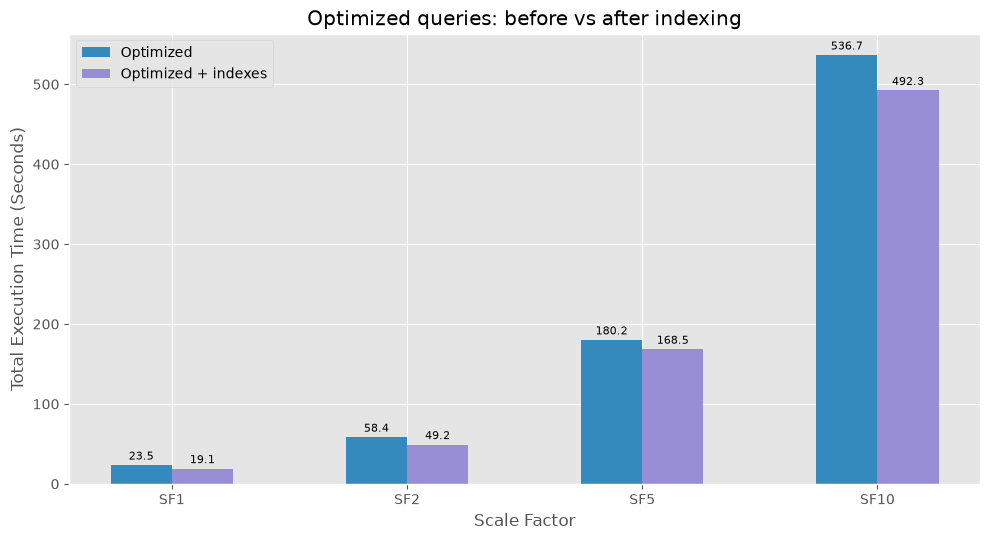

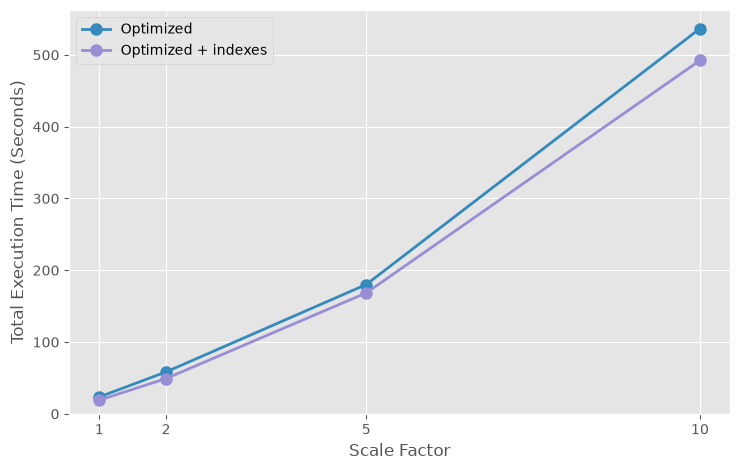

In [4]:
import re
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("ggplot")

# scale factor -> {scenario label: csv path}
FILES = {
    "SF1": {
        "Optimized":           "./benchmarks/sf1/results_optimization/exec_time_details.csv",
        "Optimized + indexes": "./benchmarks/sf1/results_optimization_index/exec_time_details.csv",
    },
    "SF2": {
        "Optimized":           "./benchmarks/sf2/results_optimization/exec_time_details.csv",
        "Optimized + indexes": "./benchmarks/sf2/results_optimization_index/exec_time_details.csv",
    },
    "SF5": {
        "Optimized":           "./benchmarks/sf5/results_optimization/exec_time_details.csv",
        "Optimized + indexes": "./benchmarks/sf5/results_optimization_index/exec_time_details.csv",
    },
    "SF10": {
        "Optimized":           "./benchmarks/sf10/results_optimization/exec_time_details.csv",
        "Optimized + indexes": "./benchmarks/sf10/results_optimization_index/exec_time_details.csv",
    },
}

METRIC    = "total"   # "avg" = average time per query, "total" = sum over queries
QUERY_COL = None    # set to your query-id column name if auto-detect picks wrong
TIME_COL  = "avg_exec_time"    # set to your execution-time column name if auto-detect picks wrong

SCENARIOS = ["Optimized", "Optimized + indexes"]
COLORS = {"Optimized": "#348ABD", "Optimized + indexes": "#988ED5"}


def qnum(v):
    """Q04 / query_04 / 4 / 'query04.sql' -> 4"""
    m = re.search(r"(\d+)", str(v))
    return int(m.group(1)) if m else None


def guess_cols(df):
    qc = QUERY_COL or next((c for c in df.columns if "query" in c.lower() or c.lower() in ("q", "id", "name")), df.columns[0])
    if TIME_COL:
        tc = TIME_COL
    else:
        num = [c for c in df.select_dtypes("number").columns if c != qc]
        pref = [c for c in num if any(k in c.lower() for k in ("exec", "time", "sec", "duration", "elapsed"))]
        tc = (pref or num)[-1]
    return qc, tc


def load(path):
    df = pd.read_csv(path)
    qc, tc = guess_cols(df)
    df = df[[qc, tc]].copy()
    df["q"] = df[qc].map(qnum)
    df = df.dropna(subset=["q", tc])
    # if several runs per query, average them first -> one time per query
    return df.groupby("q")[tc].mean()


# ---- load everything, compare only queries present in BOTH scenarios ----
rows, used = [], {}
for sf, scen in FILES.items():
    t = {s: load(p) for s, p in scen.items()}
    common = sorted(set.intersection(*[set(v.index) for v in t.values()]))
    used[sf] = common
    agg = (lambda s: s.mean()) if METRIC == "avg" else (lambda s: s.sum())
    rows.append({"SF": sf, **{s: agg(t[s].loc[common]) for s in SCENARIOS}})

g = pd.DataFrame(rows).set_index("SF")
ylabel = ("Avg Execution Time per Query (Seconds)" if METRIC == "avg"
          else "Total Execution Time (Seconds)")

print("Queries compared per SF:", {sf: len(q) for sf, q in used.items()})
display(g.round(2))

# ---- 1) grouped bar plot ----
sfs = list(g.index)
x = list(range(len(sfs)))
w = 0.26
fig, ax = plt.subplots(figsize=(10, 5.5))
for i, s in enumerate(SCENARIOS):
    bars = ax.bar([k + (i - 0.5) * w for k in x], g[s], w, label=s, color=COLORS[s])
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(sfs)
ax.set_xlabel("Scale Factor")
ax.set_ylabel(ylabel)
ax.set_title("Optimized queries: before vs after indexing")
ax.legend()
fig.tight_layout()
fig.savefig("before_after_bar.png", dpi=200)
plt.show()

# ---- 2) line plot (same style as your screenshot) ----
xn = [int(re.search(r"\d+", s).group()) for s in sfs]
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for s in SCENARIOS:
    ax.plot(xn, g[s], marker="o", markersize=8, linewidth=2, color=COLORS[s], label=s)
ax.set_xticks(xn)
ax.set_xlabel("Scale Factor")
ax.set_ylabel(ylabel)
ax.set_ylim(bottom=0)
ax.legend()
fig.tight_layout()
fig.savefig("before_after_line.png", dpi=200)
plt.show()

Queries compared per SF: {'SF1': 99, 'SF2': 99, 'SF5': 99, 'SF10': 99}


,Optimized,Optimized + clustered indexes
SF,,
SF1,23.51,21.14
SF2,58.39,42.99
SF5,180.16,171.53
SF10,536.67,416.90


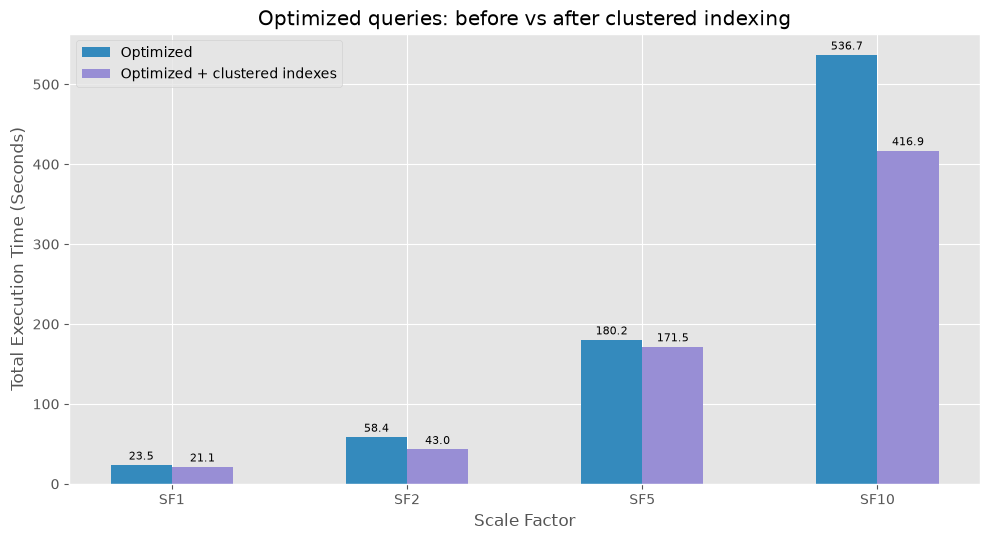

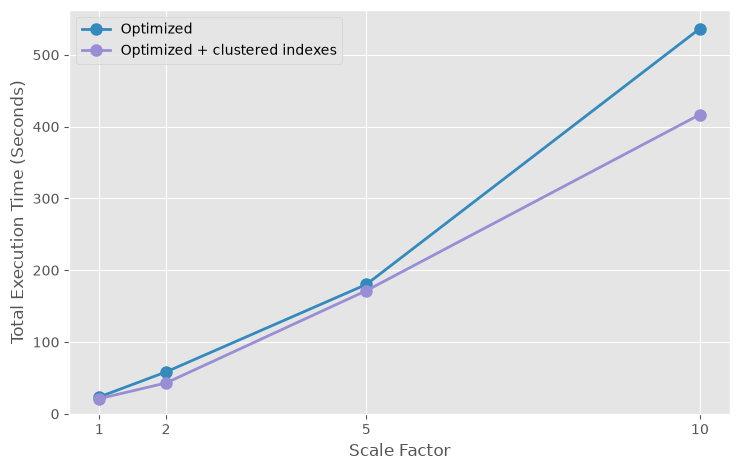

In [8]:

import re
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("ggplot")

# scale factor -> {scenario label: csv path}
FILES = {
    "SF1": {
        "Optimized": "./benchmarks/sf1/results_optimization/exec_time_details.csv",
        "Optimized + clustered indexes": "./benchmarks/sf1/results_clustered_indexes/exec_time_details.csv",
    },
    "SF2": {
        "Optimized": "./benchmarks/sf2/results_optimization/exec_time_details.csv",
        "Optimized + clustered indexes": "./benchmarks/sf2/results_clustered_indexes/exec_time_details.csv",
    },
    "SF5": {
        "Optimized": "./benchmarks/sf5/results_optimization/exec_time_details.csv",
        "Optimized + clustered indexes": "./benchmarks/sf5/results_clustered_indexes/exec_time_details.csv",
    },
    "SF10": {
        "Optimized": "./benchmarks/sf10/results_optimization/exec_time_details.csv",
        "Optimized + clustered indexes": "./benchmarks/sf10/results_clustered_indexes/exec_time_details.csv",
    },
}

METRIC = "total"  # "avg" = average time per query, "total" = sum over queries
QUERY_COL = None
TIME_COL = "avg_exec_time"

SCENARIOS = ["Optimized", "Optimized + clustered indexes"]

COLORS = {
    "Optimized": "#348ABD",
    "Optimized + clustered indexes": "#988ED5"
}


def qnum(v):
    """Q04 / query_04 / 4 / 'query04.sql' -> 4"""
    m = re.search(r"(\d+)", str(v))
    return int(m.group(1)) if m else None


def guess_cols(df):
    qc = QUERY_COL or next(
        (c for c in df.columns
         if "query" in c.lower() or c.lower() in ("q", "id", "name")),
        df.columns[0]
    )

    if TIME_COL:
        tc = TIME_COL
    else:
        num = [c for c in df.select_dtypes("number").columns if c != qc]
        pref = [
            c for c in num
            if any(k in c.lower() for k in
                   ("exec", "time", "sec", "duration", "elapsed"))
        ]
        tc = (pref or num)[-1]

    return qc, tc


def load(path):
    df = pd.read_csv(path)
    qc, tc = guess_cols(df)

    df = df[[qc, tc]].copy()
    df["q"] = df[qc].map(qnum)
    df = df.dropna(subset=["q", tc])

    # If several runs per query, average them first
    return df.groupby("q")[tc].mean()


# ---- Load everything, compare only queries present in BOTH scenarios ----
rows, used = [], {}

for sf, scen in FILES.items():
    t = {s: load(p) for s, p in scen.items()}

    common = sorted(
        set.intersection(*[set(v.index) for v in t.values()])
    )

    used[sf] = common

    agg = (
        (lambda s: s.mean())
        if METRIC == "avg"
        else (lambda s: s.sum())
    )

    rows.append({
        "SF": sf,
        **{s: agg(t[s].loc[common]) for s in SCENARIOS}
    })

g = pd.DataFrame(rows).set_index("SF")

ylabel = (
    "Avg Execution Time per Query (Seconds)"
    if METRIC == "avg"
    else "Total Execution Time (Seconds)"
)

print("Queries compared per SF:", {sf: len(q) for sf, q in used.items()})
display(g.round(2))


# ---- 1) Grouped bar plot ----
sfs = list(g.index)
x = list(range(len(sfs)))
w = 0.26

fig, ax = plt.subplots(figsize=(10, 5.5))

for i, s in enumerate(SCENARIOS):
    bars = ax.bar(
        [k + (i - 0.5) * w for k in x],
        g[s],
        w,
        label=s,
        color=COLORS[s]
    )
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(sfs)
ax.set_xlabel("Scale Factor")
ax.set_ylabel(ylabel)
ax.set_title("Optimized queries: before vs after clustered indexing")
ax.legend()

fig.tight_layout()
fig.savefig("clustered_indexes_bar.png", dpi=200)
plt.show()


# ---- 2) Line plot ----
xn = [int(re.search(r"\d+", s).group()) for s in sfs]

fig, ax = plt.subplots(figsize=(7.5, 4.8))

for s in SCENARIOS:
    ax.plot(
        xn,
        g[s],
        marker="o",
        markersize=8,
        linewidth=2,
        color=COLORS[s],
        label=s
    )

ax.set_xticks(xn)
ax.set_xlabel("Scale Factor")
ax.set_ylabel(ylabel)
ax.set_ylim(bottom=0)
ax.legend()

fig.tight_layout()
fig.savefig("clustered_indexes_line.png", dpi=200)
plt.show()


Queries compared per SF:
{'SF1': 99, 'SF2': 99, 'SF5': 99, 'SF10': 99}


,Optimized,Optimized + indexes,Optimized + clustered indexes
SF,,,
SF1,23.51,19.06,21.14
SF2,58.39,49.17,42.99
SF5,180.16,168.48,171.53
SF10,536.67,492.31,416.90


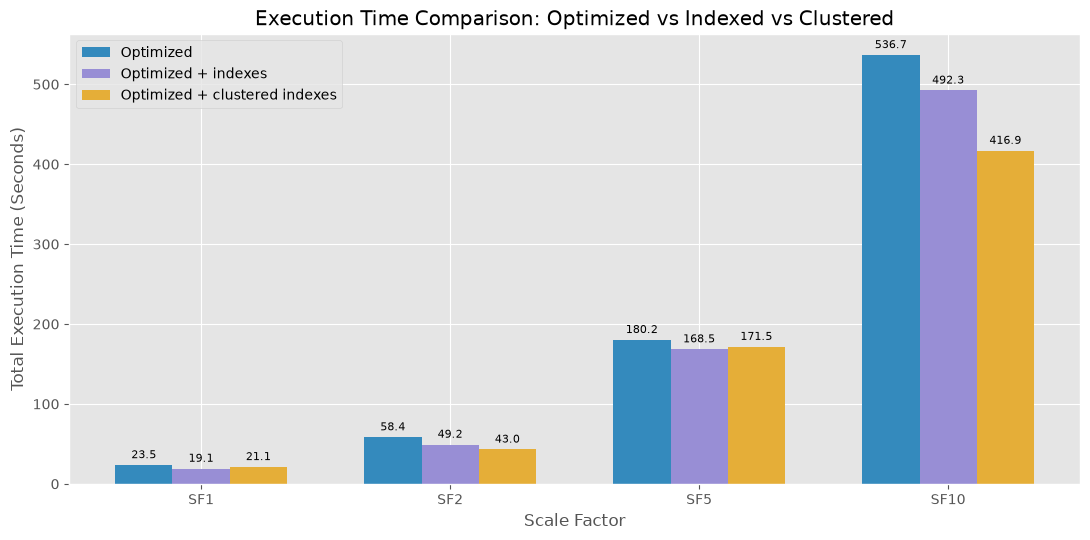

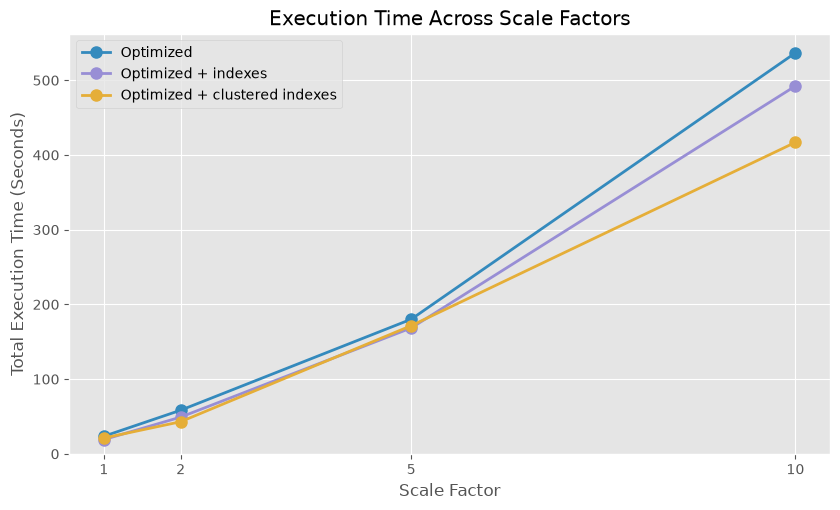

In [9]:

import re
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("ggplot")

# Scale factor -> {scenario label: CSV path}
FILES = {
    "SF1": {
        "Optimized": "./benchmarks/sf1/results_optimization/exec_time_details.csv",
        "Optimized + indexes": "./benchmarks/sf1/results_optimization_index/exec_time_details.csv",
        "Optimized + clustered indexes": "./benchmarks/sf1/results_clustered_indexes/exec_time_details.csv",
    },
    "SF2": {
        "Optimized": "./benchmarks/sf2/results_optimization/exec_time_details.csv",
        "Optimized + indexes": "./benchmarks/sf2/results_optimization_index/exec_time_details.csv",
        "Optimized + clustered indexes": "./benchmarks/sf2/results_clustered_indexes/exec_time_details.csv",
    },
    "SF5": {
        "Optimized": "./benchmarks/sf5/results_optimization/exec_time_details.csv",
        "Optimized + indexes": "./benchmarks/sf5/results_optimization_index/exec_time_details.csv",
        "Optimized + clustered indexes": "./benchmarks/sf5/results_clustered_indexes/exec_time_details.csv",
    },
    "SF10": {
        "Optimized": "./benchmarks/sf10/results_optimization/exec_time_details.csv",
        "Optimized + indexes": "./benchmarks/sf10/results_optimization_index/exec_time_details.csv",
        "Optimized + clustered indexes": "./benchmarks/sf10/results_clustered_indexes/exec_time_details.csv",
    },
}

METRIC = "total"  # "avg" or "total"
QUERY_COL = None
TIME_COL = "avg_exec_time"

SCENARIOS = [
    "Optimized",
    "Optimized + indexes",
    "Optimized + clustered indexes"
]

COLORS = {
    "Optimized": "#348ABD",
    "Optimized + indexes": "#988ED5",
    "Optimized + clustered indexes": "#E5AE38"
}


def qnum(v):
    """Q04 / query_04 / 4 / 'query04.sql' -> 4"""
    m = re.search(r"(\d+)", str(v))
    return int(m.group(1)) if m else None


def guess_cols(df):
    qc = QUERY_COL or next(
        (c for c in df.columns
         if "query" in c.lower() or c.lower() in ("q", "id", "name")),
        df.columns[0]
    )

    if TIME_COL:
        tc = TIME_COL
    else:
        num = [
            c for c in df.select_dtypes("number").columns
            if c != qc
        ]
        pref = [
            c for c in num
            if any(k in c.lower() for k in
                   ("exec", "time", "sec", "duration", "elapsed"))
        ]
        tc = (pref or num)[-1]

    return qc, tc


def load(path):
    df = pd.read_csv(path)
    qc, tc = guess_cols(df)

    df = df[[qc, tc]].copy()
    df["q"] = df[qc].map(qnum)
    df[tc] = pd.to_numeric(df[tc], errors="coerce")
    df = df.dropna(subset=["q", tc])

    # Average multiple rows per query if necessary
    return df.groupby("q")[tc].mean()


# --------------------------------------------------
# Load all three scenarios for each scale factor
# --------------------------------------------------
rows, used = [], {}

for sf, scen in FILES.items():

    t = {s: load(scen[s]) for s in SCENARIOS}

    # Compare only queries present in ALL three scenarios
    common = sorted(
        set.intersection(*[set(v.index) for v in t.values()])
    )

    used[sf] = common

    agg = (
        (lambda s: s.mean())
        if METRIC == "avg"
        else (lambda s: s.sum())
    )

    rows.append({
        "SF": sf,
        **{
            s: agg(t[s].loc[common])
            for s in SCENARIOS
        }
    })

g = pd.DataFrame(rows).set_index("SF")

ylabel = (
    "Avg Execution Time per Query (Seconds)"
    if METRIC == "avg"
    else "Total Execution Time (Seconds)"
)

print("Queries compared per SF:")
print({sf: len(q) for sf, q in used.items()})

display(g.round(2))


# --------------------------------------------------
# 1) Grouped bar plot (all three scenarios)
# --------------------------------------------------
sfs = list(g.index)
x = list(range(len(sfs)))

w = 0.23

fig, ax = plt.subplots(figsize=(11, 5.5))

for i, s in enumerate(SCENARIOS):

    positions = [
        k + (i - 1) * w
        for k in x
    ]

    bars = ax.bar(
        positions,
        g[s],
        w,
        label=s,
        color=COLORS[s]
    )

    ax.bar_label(
        bars,
        fmt="%.1f",
        padding=3,
        fontsize=8
    )

ax.set_xticks(x)
ax.set_xticklabels(sfs)
ax.set_xlabel("Scale Factor")
ax.set_ylabel(ylabel)

ax.set_title(
    "Execution Time Comparison: Optimized vs Indexed vs Clustered"
)

ax.legend()
ax.set_ylim(bottom=0)

fig.tight_layout()
fig.savefig("three_scenarios_bar.png", dpi=200)
plt.show()


# --------------------------------------------------
# 2) Line plot (all three scenarios)
# --------------------------------------------------
xn = [
    int(re.search(r"\d+", s).group())
    for s in sfs
]

fig, ax = plt.subplots(figsize=(8.5, 5.2))

for s in SCENARIOS:

    ax.plot(
        xn,
        g[s],
        marker="o",
        markersize=8,
        linewidth=2,
        color=COLORS[s],
        label=s
    )

ax.set_xticks(xn)
ax.set_xlabel("Scale Factor")
ax.set_ylabel(ylabel)
ax.set_ylim(bottom=0)

ax.set_title(
    "Execution Time Across Scale Factors"
)

ax.legend()

fig.tight_layout()
fig.savefig("three_scenarios_line.png", dpi=200)
plt.show()


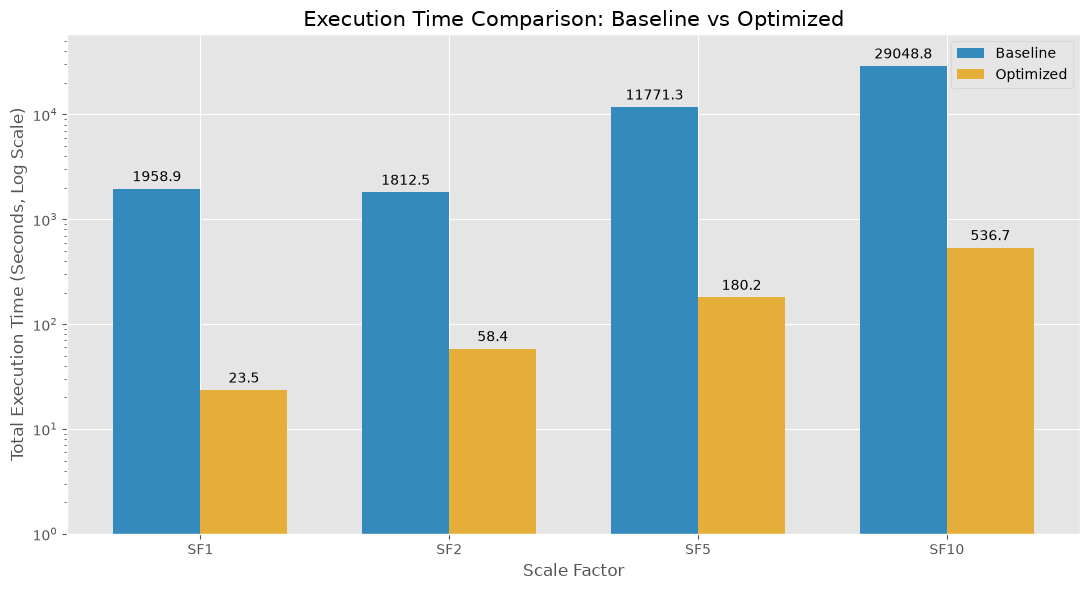

  SF  Baseline  Optimized
 SF1  1958.884     23.511
 SF2  1812.453     58.388
 SF5 11771.287    180.160
SF10 29048.767    536.673


In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("ggplot")

# Scale factor -> CSV paths
FILES = {
    "SF1": {
        "Baseline": "./benchmarks/sf1/results_no_timeout/exec_time_details.csv",
        "Optimized": "./benchmarks/sf1/results_optimization/exec_time_details.csv",
    },
    "SF2": {
        "Baseline": "./benchmarks/sf2/results_no_timeout/exec_time_details.csv",
        "Optimized": "./benchmarks/sf2/results_optimization/exec_time_details.csv",
    },
    "SF5": {
        "Baseline": "./benchmarks/sf5/results_no_timeout/exec_time_details.csv",
        "Optimized": "./benchmarks/sf5/results_optimization/exec_time_details.csv",
    },
    "SF10": {
        "Baseline": "./benchmarks/sf10/results-baseline-original-without-timeout/exec_time_details.csv",
        "Optimized": "./benchmarks/sf10/results_optimization/exec_time_details.csv",
    },
}

results = []

for sf, paths in FILES.items():
    baseline = pd.read_csv(paths["Baseline"])
    optimized = pd.read_csv(paths["Optimized"])

    # Only successful queries
    baseline = baseline[baseline["status"] == "SUCCESS"]
    optimized = optimized[optimized["status"] == "SUCCESS"]

    # Compare the same queries in both configurations
    common = baseline[["query", "avg_exec_time"]].merge(
        optimized[["query", "avg_exec_time"]],
        on="query",
        suffixes=("_baseline", "_optimized")
    )

    results.append({
        "SF": sf,
        "Baseline": common["avg_exec_time_baseline"].sum(),
        "Optimized": common["avg_exec_time_optimized"].sum()
    })

df = pd.DataFrame(results)

# Plot
x = np.arange(len(df))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

bars1 = ax.bar(
    x - width/2, df["Baseline"], width,
    label="Baseline", color="#348ABD"
)

bars2 = ax.bar(
    x + width/2, df["Optimized"], width,
    label="Optimized", color="#E5AE38"
)

# Value labels
for bars in [bars1, bars2]:
    ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=10)

ax.set_xlabel("Scale Factor", fontsize=12)
ax.set_ylabel("Total Execution Time (Seconds)", fontsize=12)
ax.set_title(
    "Execution Time Comparison: Baseline vs Optimized",
    fontsize=15
)
ax.set_xticks(x)
ax.set_xticklabels(df["SF"])
ax.legend()
ax.set_ylim(0, max(df["Baseline"].max(), df["Optimized"].max()) * 1.15)

# Use logarithmic scale for Y-axis
ax.set_yscale("log")

# Update Y-axis label
ax.set_ylabel("Total Execution Time (Seconds, Log Scale)", fontsize=12)

# Set logarithmic axis limits
ax.set_ylim(1, max(df["Baseline"].max(), df["Optimized"].max()) * 2)

plt.tight_layout()
plt.show()

# Display total execution times
print(df.to_string(index=False))


Status,Faster,Slower,Unchanged,Total
SF,,,,
SF1,53,32,14,99
SF2,59,38,2,99
SF5,50,49,0,99
SF10,51,48,0,99



=== SF1: 32 queries slower with indexes ===


,Query,Optimized (s),Optimized + indexes (s),Increase (s),Increase (%)
0,Q04,1.19,1.76,0.57,48.15
1,Q67,0.52,0.81,0.29,54.77
2,Q51,0.36,0.48,0.12,31.94
3,Q74,0.22,0.32,0.11,48.39
4,Q11,0.22,0.30,0.09,40.55
5,Q27,0.21,0.29,0.08,40.58
6,Q07,0.17,0.24,0.07,44.12
7,Q65,0.27,0.30,0.04,13.43
8,Q97,0.18,0.21,0.04,19.55
9,Q16,0.53,0.56,0.03,6.27



=== SF2: 38 queries slower with indexes ===


,Query,Optimized (s),Optimized + indexes (s),Increase (s),Increase (%)
0,Q04,2.58,3.92,1.34,51.92
1,Q78,1.45,2.32,0.86,59.61
2,Q67,1.21,1.82,0.60,49.96
3,Q97,0.38,0.83,0.44,114.81
4,Q47,1.20,1.56,0.36,30.00
5,Q74,0.39,0.72,0.33,83.85
6,Q11,0.48,0.78,0.31,64.57
7,Q51,0.77,0.98,0.21,27.86
8,Q27,0.41,0.58,0.16,39.81
9,Q65,0.58,0.70,0.11,19.35



=== SF5: 49 queries slower with indexes ===


,Query,Optimized (s),Optimized + indexes (s),Increase (s),Increase (%)
0,Q04,5.90,8.44,2.53,42.92
1,Q67,2.56,5.06,2.49,97.23
2,Q78,3.62,5.92,2.31,63.83
3,Q35,1.22,2.65,1.43,116.97
4,Q97,0.92,2.29,1.37,148.32
5,Q74,19.82,21.13,1.31,6.63
6,Q45,0.15,1.26,1.11,739.33
7,Q11,23.26,24.22,0.95,4.11
8,Q65,1.58,2.53,0.95,60.20
9,Q47,2.50,3.33,0.83,33.07



=== SF10: 48 queries slower with indexes ===


,Query,Optimized (s),Optimized + indexes (s),Increase (s),Increase (%)
0,Q04,12.31,28.82,16.51,134.08
1,Q25,6.64,15.80,9.16,138.05
2,Q74,31.35,40.39,9.04,28.83
3,Q78,8.17,14.87,6.70,81.94
4,Q97,2.23,6.91,4.67,209.31
5,Q65,3.71,8.22,4.51,121.78
6,Q67,6.94,11.42,4.48,64.60
7,Q17,10.24,14.53,4.29,41.92
8,Q72,3.58,7.14,3.56,99.44
9,Q45,0.55,3.75,3.20,587.89


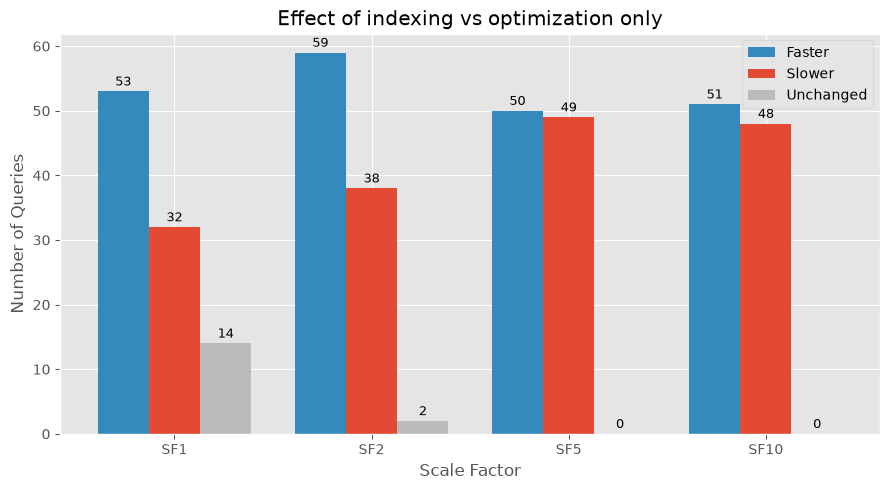

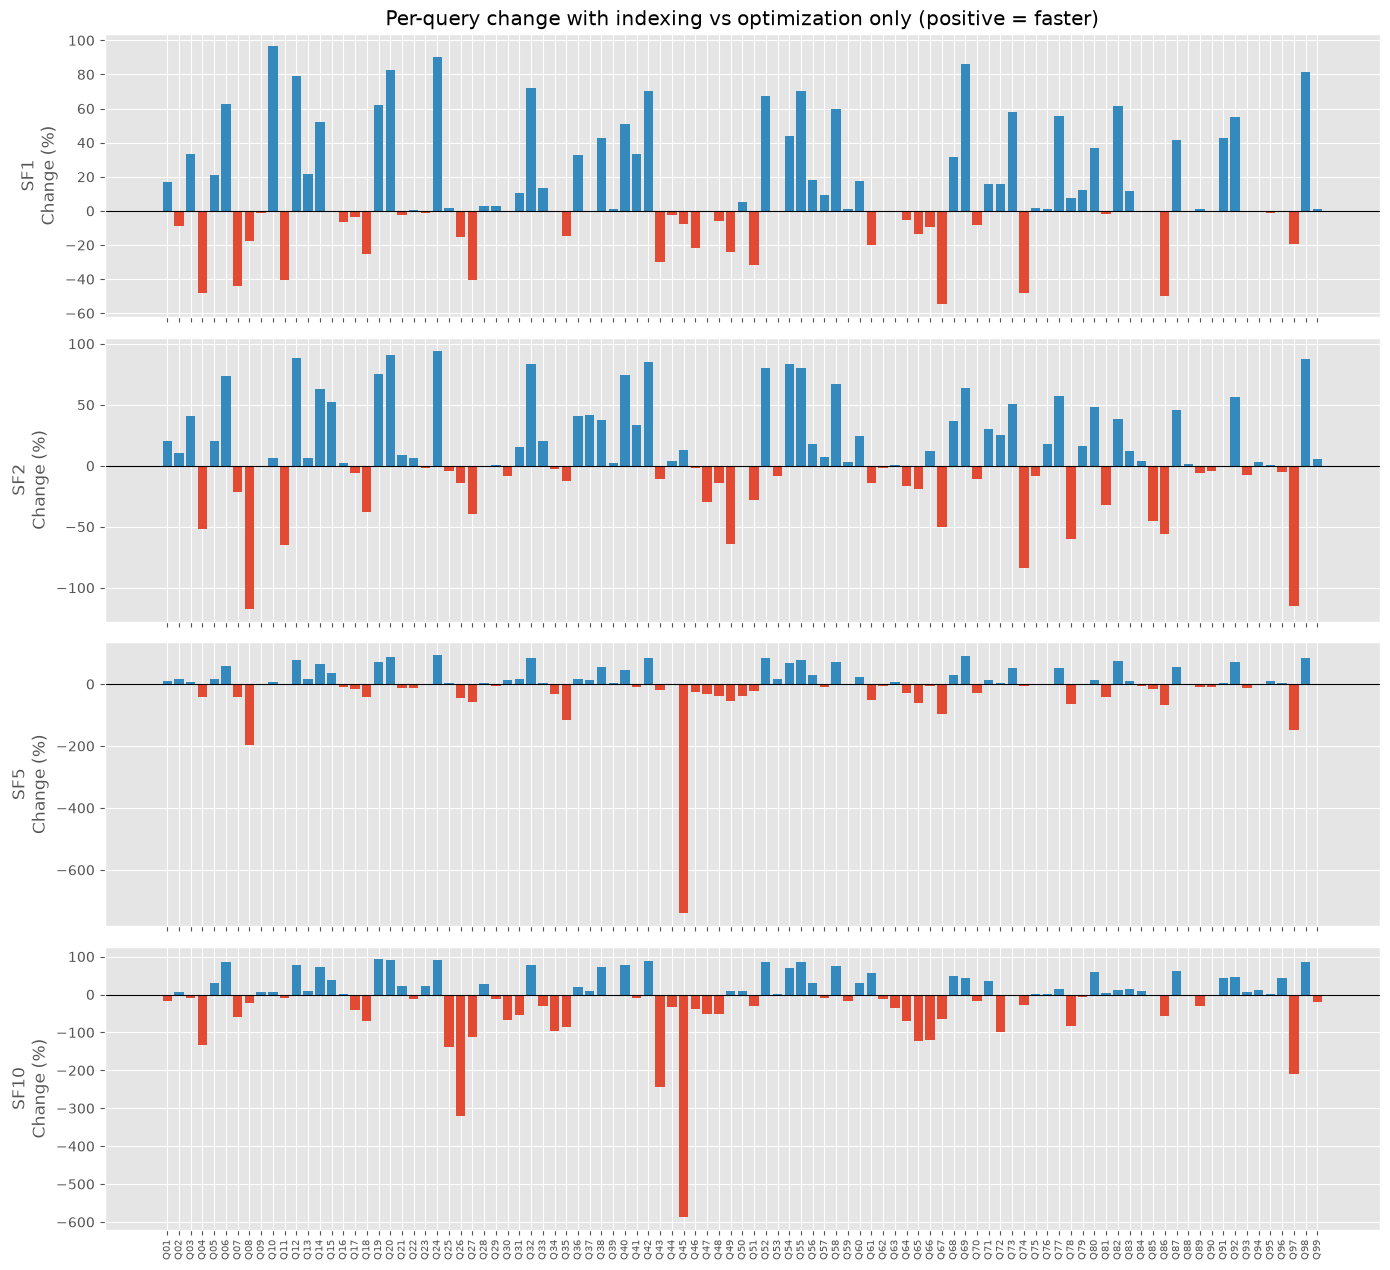

In [7]:
# Reuses cmp_df, FILES from the previous cells (run those first).
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("ggplot")
TOL_PCT = 0   # differences within +/- this % count as "unchanged" (e.g. 5 to ignore noise)

def status(p):
    if p > TOL_PCT:  return "Faster"
    if p < -TOL_PCT: return "Slower"
    return "Unchanged"

cmp_df["Status"] = cmp_df["Improvement (%)"].map(status)

# ---- counts per SF ----
counts = (cmp_df.groupby(["SF", "Status"]).size().unstack(fill_value=0)
          .reindex(index=list(FILES), columns=["Faster", "Slower", "Unchanged"], fill_value=0))
counts["Total"] = counts.sum(axis=1)
display(counts)

# ---- list of the queries that got slower (increase in time) ----
slower = (cmp_df[cmp_df["Status"] == "Slower"]
          .sort_values(["SF", "Saved (s)"])           # most negative saved = biggest increase first
          .rename(columns={"Saved (s)": "Increase (s)"}))
slower["Increase (s)"] = -slower["Increase (s)"]
slower["Increase (%)"] = -slower["Improvement (%)"]
for sf in FILES:
    sub = slower[slower["SF"] == sf]
    print(f"\n=== {sf}: {len(sub)} queries slower with indexes ===")
    display(sub[["Query", "Optimized (s)", "Optimized + indexes (s)", "Increase (s)", "Increase (%)"]]
            .round(2).reset_index(drop=True))
slower.round(3).to_csv("queries_slower_with_indexes.csv", index=False)

# ---- plot 1: number of queries faster / slower / unchanged per SF ----
colors = {"Faster": "#348ABD", "Slower": "#E24A33", "Unchanged": "#BBBBBB"}
cats = ["Faster", "Slower", "Unchanged"]
x = np.arange(len(counts)); w = 0.26
fig, ax = plt.subplots(figsize=(9, 5))
for i, c in enumerate(cats):
    bars = ax.bar(x + (i - 1) * w, counts[c], w, label=c, color=colors[c])
    ax.bar_label(bars, padding=2, fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(counts.index)
ax.set_xlabel("Scale Factor")
ax.set_ylabel("Number of Queries")
ax.set_title("Effect of indexing vs optimization only")
ax.legend()
fig.tight_layout()
fig.savefig("index_effect_counts.png", dpi=200)
plt.show()

# ---- plot 2: per-query change (%) for every SF; blue = faster, red = slower ----
fig, axes = plt.subplots(len(FILES), 1, figsize=(14, 3.2 * len(FILES)), sharex=True)
for ax, sf in zip(np.atleast_1d(axes), FILES):
    sub = cmp_df[cmp_df["SF"] == sf].sort_values("Query")
    cols = sub["Improvement (%)"].map(lambda p: colors["Faster"] if p > 0 else colors["Slower"])
    ax.bar(sub["Query"], sub["Improvement (%)"], color=cols)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_ylabel(f"{sf}\nChange (%)")
    ax.tick_params(axis="x", rotation=90, labelsize=7)
np.atleast_1d(axes)[0].set_title("Per-query change with indexing vs optimization only (positive = faster)")
plt.tight_layout()
fig.savefig("index_effect_per_query.png", dpi=200)
plt.show()

SF,SF1,SF2,SF5,SF10
# Faster,53.00,59.00,50.00,51.00
# Slower,32.00,38.00,49.00,48.00
Time saved (s),6.14,15.01,32.81,138.03
Time added (s),1.69,5.80,21.13,93.66
Net change (s),4.45,9.22,11.68,44.36
"Saved, % of faster queries' time",41.45,41.13,47.97,38.76
"Added, % of slower queries' time",21.28,26.55,18.91,51.88
"Saved, % of total suite time",26.11,25.71,18.21,25.72
"Added, % of total suite time",7.18,9.92,11.73,17.45
"Net, % of total suite time",18.94,15.78,6.48,8.27


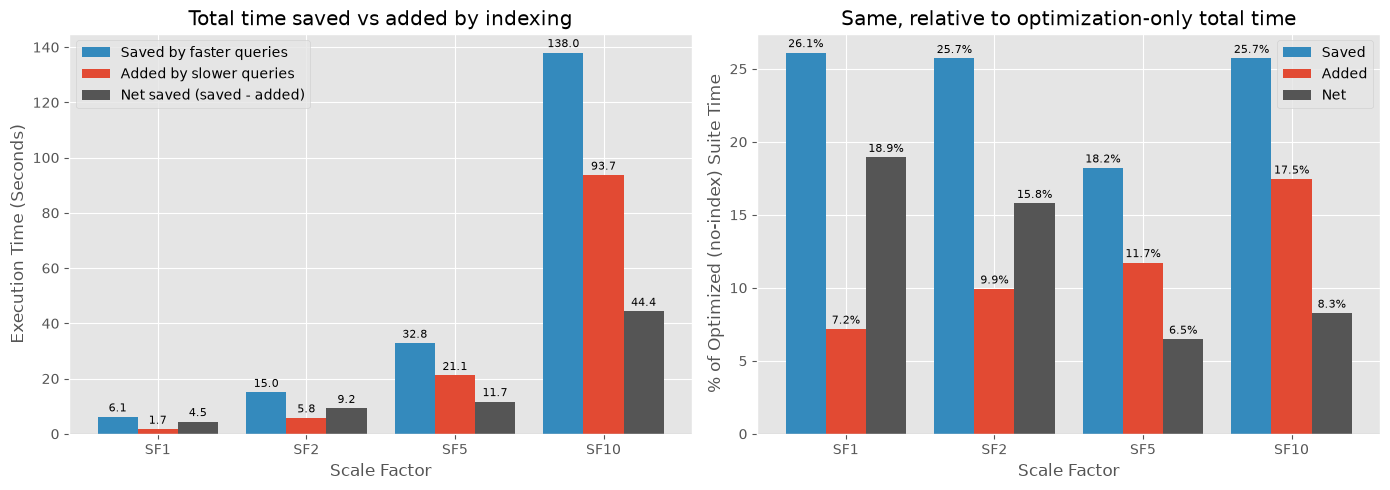

In [8]:
# Reuses cmp_df (with the "Status" column) and FILES from the previous cells.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("ggplot")
BLUE, RED, GREY = "#348ABD", "#E24A33", "#555555"

rows = []
for sf in FILES:
    d = cmp_df[cmp_df["SF"] == sf]
    fast = d[d["Status"] == "Faster"]
    slow = d[d["Status"] == "Slower"]

    saved = fast["Saved (s)"].sum()           # total seconds removed by faster queries
    added = -slow["Saved (s)"].sum()          # total seconds added by slower queries
    base  = d["Optimized (s)"].sum()          # total time of optimization-only (all compared queries)
    fast_base = fast["Optimized (s)"].sum()
    slow_base = slow["Optimized (s)"].sum()

    rows.append({
        "SF": sf,
        "# Faster": len(fast),
        "# Slower": len(slow),
        "Time saved (s)": saved,
        "Time added (s)": added,
        "Net change (s)": saved - added,
        "Saved, % of faster queries' time": saved / fast_base * 100 if fast_base else 0,
        "Added, % of slower queries' time": added / slow_base * 100 if slow_base else 0,
        "Saved, % of total suite time": saved / base * 100 if base else 0,
        "Added, % of total suite time": added / base * 100 if base else 0,
        "Net, % of total suite time": (saved - added) / base * 100 if base else 0,
    })

impact = pd.DataFrame(rows).set_index("SF")
display(impact.round(2).T)
impact.round(3).to_csv("index_impact_summary.csv")

x = np.arange(len(impact)); w = 0.27
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# ---- plot 1: seconds saved vs added (+ net) ----
b1 = ax1.bar(x - w, impact["Time saved (s)"], w, color=BLUE, label="Saved by faster queries")
b2 = ax1.bar(x,     impact["Time added (s)"], w, color=RED,  label="Added by slower queries")
b3 = ax1.bar(x + w, impact["Net change (s)"], w, color=GREY, label="Net saved (saved - added)")
for b in (b1, b2, b3):
    ax1.bar_label(b, fmt="%.1f", padding=2, fontsize=8)
ax1.axhline(0, color="black", linewidth=0.8)
ax1.set_xticks(x); ax1.set_xticklabels(impact.index)
ax1.set_xlabel("Scale Factor")
ax1.set_ylabel("Execution Time (Seconds)")
ax1.set_title("Total time saved vs added by indexing")
ax1.legend()

# ---- plot 2: same thing as % of total optimized-suite time ----
b1 = ax2.bar(x - w, impact["Saved, % of total suite time"], w, color=BLUE, label="Saved")
b2 = ax2.bar(x,     impact["Added, % of total suite time"], w, color=RED,  label="Added")
b3 = ax2.bar(x + w, impact["Net, % of total suite time"],   w, color=GREY, label="Net")
for b in (b1, b2, b3):
    ax2.bar_label(b, fmt="%.1f%%", padding=2, fontsize=8)
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_xticks(x); ax2.set_xticklabels(impact.index)
ax2.set_xlabel("Scale Factor")
ax2.set_ylabel("% of Optimized (no-index) Suite Time")
ax2.set_title("Same, relative to optimization-only total time")
ax2.legend()

fig.tight_layout()
fig.savefig("index_time_impact.png", dpi=200)
plt.show()

In [8]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.style.use("ggplot")

# Scale factor -> results CSV file
FILES = {
    "SF1":  "./benchmarks/sf1/results_load_independent/run4/scenario_totals.csv",
    "SF2":  "./benchmarks/sf2/results_load_independent/run2/scenario_totals.csv",
    "SF5":  "./benchmarks/sf5/results_load_independent/run2/scenario_totals.csv",
    "SF10": "./benchmarks/sf10/results_load_independent/run2/scenario_totals.csv",
}

SCENARIOS = {
    "baseline": "Baseline",
    "indexed_14": "Non-clustered indexes",
    "clustered_8": "Clustered indexes",
}

frames = []

for sf_label, path in FILES.items():
    if not Path(path).exists():
        print(f"Skipping {sf_label}: file not found")
        continue

    df = pd.read_csv(path)
    df = df[df["status"] == "SUCCESS"].copy()

    df["SF"] = int(sf_label.replace("SF", ""))
    df["Scenario"] = df["scenario"].map(SCENARIOS)
    df["Load Time (s)"] = pd.to_numeric(
        df["measured_total_s"], errors="coerce"
    )

    frames.append(df)

if not frames:
    raise FileNotFoundError("No load-test CSV files found. Check FILES paths.")

results = pd.concat(frames, ignore_index=True)
results = results.dropna(subset=["Scenario", "Load Time (s)"])

# Final table: one row per SF
scenario_order = list(SCENARIOS.values())

load_times = results.pivot_table(
    index="SF",
    columns="Scenario",
    values="Load Time (s)",
    aggfunc="first"
)

load_times = load_times.reindex(columns=scenario_order)
load_times = load_times.sort_index()

# Directory for saving figures
OUTPUT_DIR = Path("./benchmarks/load_test_plots")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

display(load_times.round(3))


Scenario,Baseline,Non-clustered indexes,Clustered indexes
SF,,,
1,25.656,28.243,32.664
2,41.800,47.453,56.317
5,113.227,131.098,170.391
10,264.964,298.890,422.998


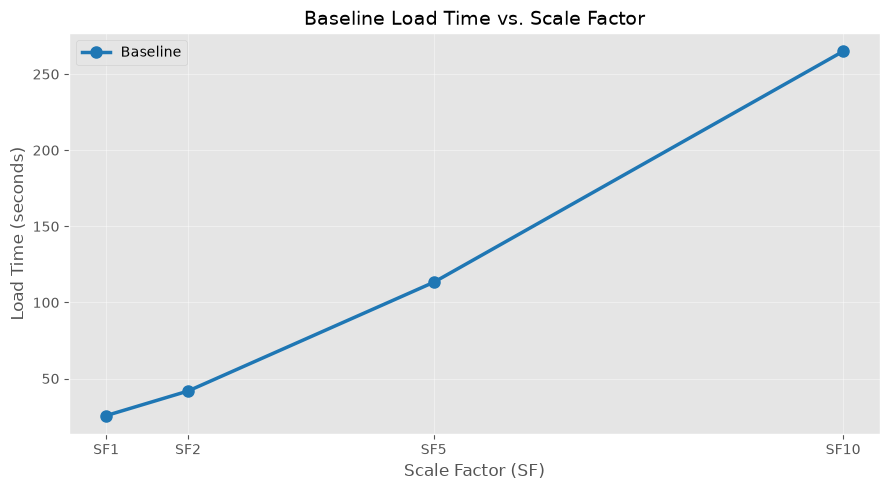

In [9]:

# Baseline load times
baseline = load_times["Baseline"].dropna()

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    baseline.index,
    baseline.values,
    marker="o",
    linewidth=2.5,
    markersize=8,
    color="tab:blue",
    label="Baseline"
)

ax.set_xlabel("Scale Factor (SF)", fontsize=12)
ax.set_ylabel("Load Time (seconds)", fontsize=12)
ax.set_title("Baseline Load Time vs. Scale Factor", fontsize=14)

ax.set_xticks(baseline.index)
ax.set_xticklabels([f"SF{x}" for x in baseline.index])

ax.legend()
ax.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "baseline_load_vs_sf.png", dpi=300, bbox_inches="tight")
plt.show()


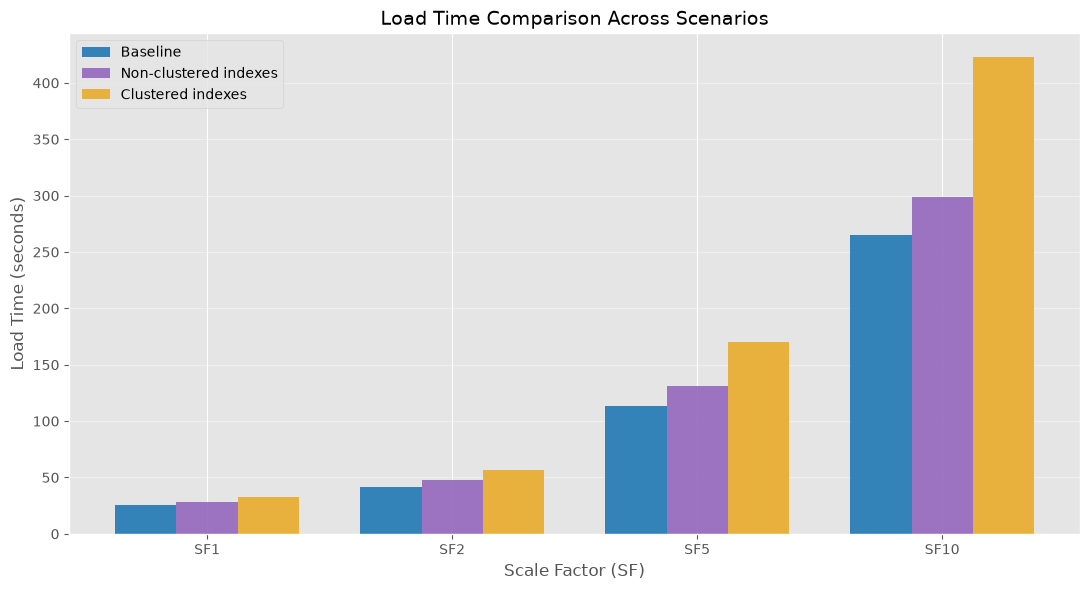

In [10]:

fig, ax = plt.subplots(figsize=(11, 6))

sf_values = load_times.index
x = np.arange(len(sf_values))
width = 0.25

colors = ["tab:blue", "tab:purple", "#E9AC2C"]

for i, scenario in enumerate(scenario_order):
    values = load_times[scenario].values

    ax.bar(
        x + (i - 1) * width,
        values,
        width=width,
        label=scenario,
        color=colors[i],
        alpha=0.9
    )

ax.set_xlabel("Scale Factor (SF)", fontsize=12)
ax.set_ylabel("Load Time (seconds)", fontsize=12)
ax.set_title("Load Time Comparison Across Scenarios", fontsize=14)

ax.set_xticks(x)
ax.set_xticklabels([f"SF{sf}" for sf in sf_values])

ax.legend()
ax.grid(axis="y", alpha=0.4)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "load_scenarios_bar.png", dpi=300, bbox_inches="tight")
plt.show()


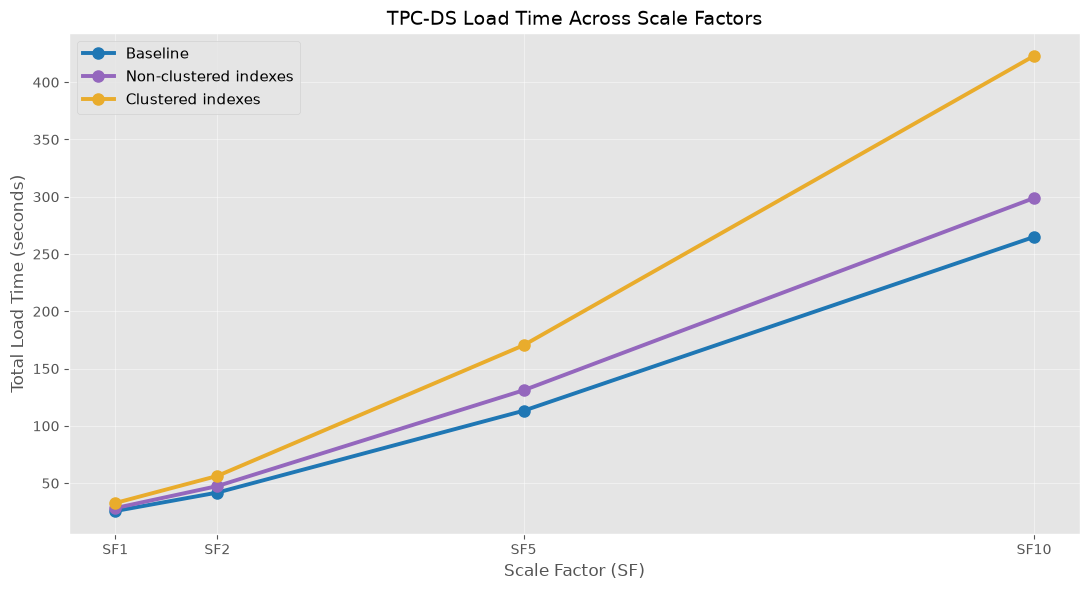

In [11]:

fig, ax = plt.subplots(figsize=(11, 6))

styles = {
    "Baseline": {
        "color": "tab:blue",
        "marker": "o",
    },
    "Non-clustered indexes": {
        "color": "tab:purple",
        "marker": "o",
    },
    "Clustered indexes": {
        "color": "#E9AC2C",
        "marker": "o",
    },
}

for scenario in scenario_order:
    series = load_times[scenario].dropna()

    ax.plot(
        series.index,
        series.values,
        label=scenario,
        color=styles[scenario]["color"],
        marker=styles[scenario]["marker"],
        linewidth=2.8,
        markersize=8
    )

ax.set_xlabel("Scale Factor (SF)", fontsize=12)
ax.set_ylabel("Total Load Time (seconds)", fontsize=12)
ax.set_title("TPC-DS Load Time Across Scale Factors", fontsize=14)

ax.set_xticks(load_times.index)
ax.set_xticklabels([f"SF{x}" for x in load_times.index])

ax.legend(loc="upper left", fontsize=11)
ax.grid(True, alpha=0.45)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "load_time_all_scenarios.png", dpi=300, bbox_inches="tight")
plt.show()


In [12]:
import pandas as pd

before = pd.read_csv(
    "./benchmarks/sf10/results_optimization/exec_time_details.csv"
)

after = pd.read_csv(
    "./benchmarks/sf10/results_optimization_index/exec_time_details.csv"
)

before = before.set_index("query")["avg_exec_time"]
after = after.set_index("query")["avg_exec_time"]

comparison = pd.concat(
    [before, after],
    axis=1,
    keys=["Before indexing", "After indexing"]
).dropna()

comparison["Time added (s)"] = (
    comparison["After indexing"]
    - comparison["Before indexing"]
)

# 15 queries with the largest performance regression
worst = comparison.sort_values(
    "Time added (s)", ascending=False
).head(15)

display(worst.round(3))

,Before indexing,After indexing,Time added (s)
query,,,
Q04,12.310,28.815,16.505
Q25,6.636,15.797,9.161
Q74,31.348,40.387,9.039
Q78,8.171,14.866,6.695
Q97,2.233,6.907,4.674
Q65,3.706,8.219,4.513
Q67,6.941,11.425,4.484
Q17,10.239,14.531,4.292
Q72,3.579,7.138,3.559


Upper fence: 45.1 s | Lower fence: 0.027 s
query  exec_time_run_1
  Q04         4934.266
  Q74         4537.976
  Q06          602.195
  Q01          486.684
  Q81          461.990
  Q95          197.480
  Q11          184.014
  Q30          106.186
  Q14           88.809
  Q37            0.020
  Q61            0.011


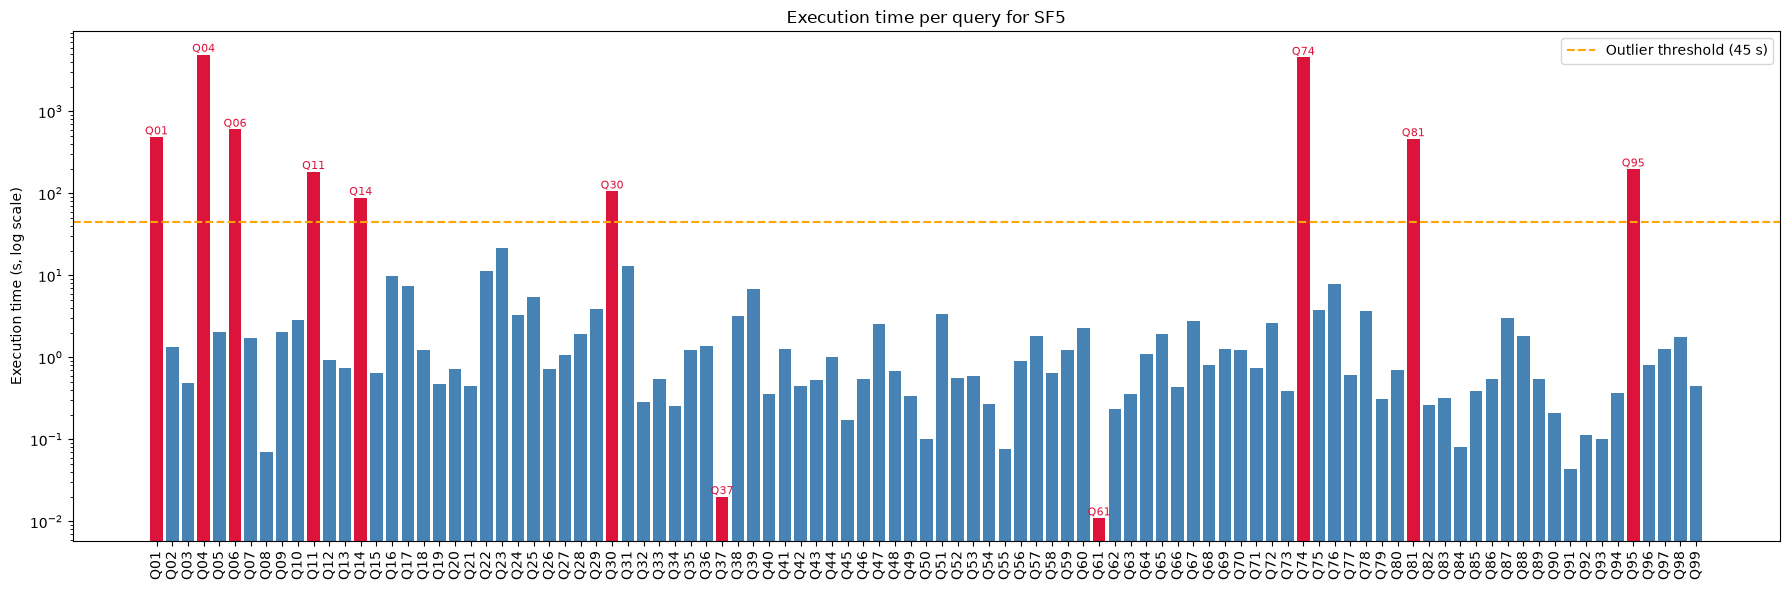

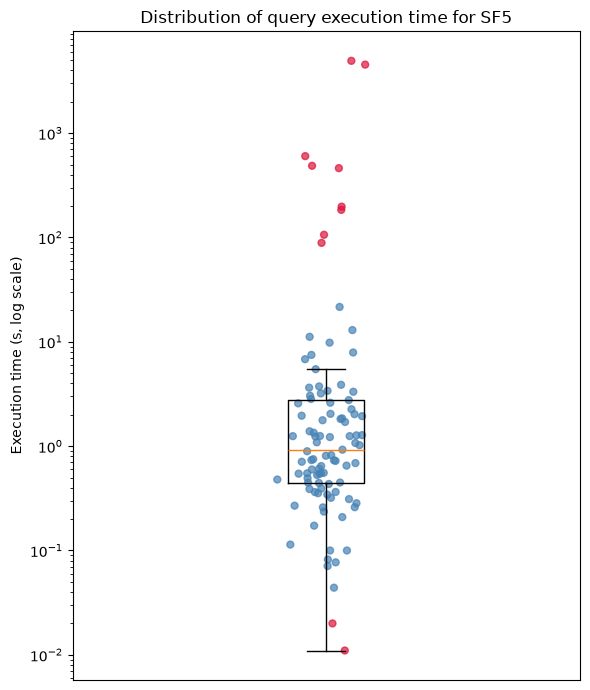

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Load ---
df = pd.read_csv("./benchmarks/sf5/results_no_timeout/exec_time_details.csv")          # change to your file name
df = df[df["status"] == "SUCCESS"].copy()

# Use the median time (same as run_1 if you only ran once)
col = "exec_time_run_1"
df["log_t"] = np.log10(df[col])

# --- Outlier detection: IQR on log scale ---
q1, q3 = df["log_t"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
lower = q1 - 1.5 * iqr
df["outlier"] = (df["log_t"] > upper) | (df["log_t"] < lower)

print(f"Upper fence: {10**upper:.1f} s | Lower fence: {10**lower:.3f} s")
print(df.loc[df["outlier"], ["query", col]]
        .sort_values(col, ascending=False)
        .to_string(index=False))

# --- Plot 1: bar chart per query ---
fig, ax = plt.subplots(figsize=(18, 6))
colors = np.where(df["outlier"], "crimson", "steelblue")
ax.bar(df["query"], df[col], color=colors)
ax.set_yscale("log")
ax.axhline(10**upper, color="orange", ls="--", label=f"Outlier threshold ({10**upper:.0f} s)")
ax.set_ylabel("Execution time (s, log scale)")
ax.set_title("Execution time per query for SF5")
ax.tick_params(axis="x", rotation=90)

for _, r in df[df["outlier"]].iterrows():
    ax.annotate(r["query"], (r["query"], r[col]),
                ha="center", va="bottom", fontsize=8, color="crimson")

ax.legend()
plt.tight_layout()
plt.show()

# --- Plot 2: boxplot (log scale) with outlier points labeled ---
fig, ax = plt.subplots(figsize=(6, 7))
ax.boxplot(df[col], whis=1.5, showfliers=False)   # whiskers drawn on raw scale; points below
ax.scatter(np.random.normal(1, 0.04, len(df)), df[col],
           c=colors, alpha=0.7, s=25)
ax.set_yscale("log")
ax.set_ylabel("Execution time (s, log scale)")
ax.set_xticks([])
ax.set_title("Distribution of query execution time for SF5")
plt.tight_layout()
plt.show()

Loaded scale factors: [np.int64(1), np.int64(2), np.int64(5), np.int64(10)]
Excluded queries: [1, 4, 6, 74]
Total data points: 380


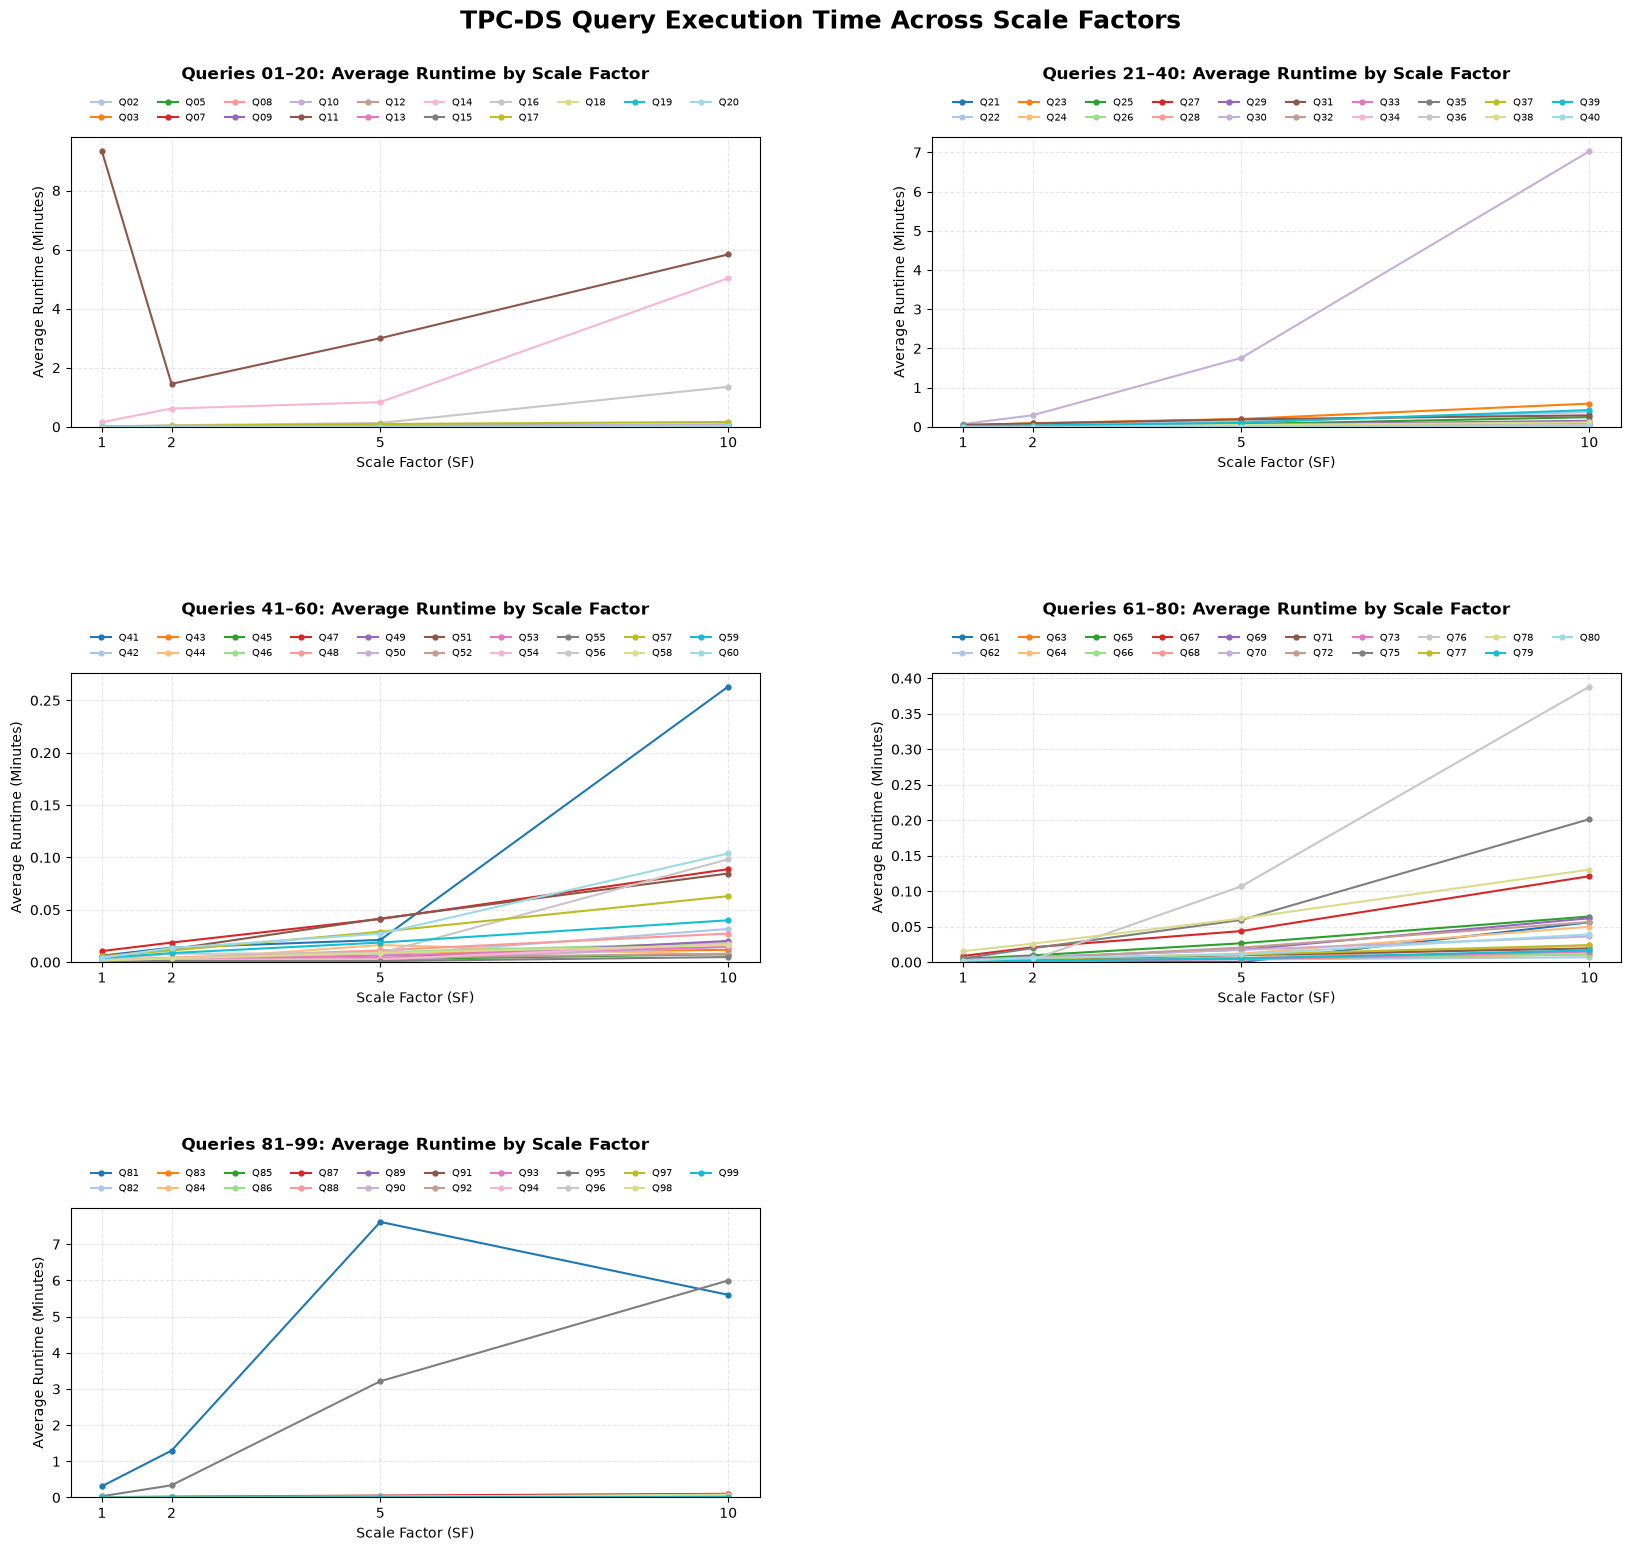

In [11]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# =====================================================
# 1. CSV FILE PATHS
# =====================================================

files = {
    1: "benchmarks/sf1/results_baseline/exec_time_details.csv",
    2: "benchmarks/sf2/results_baseline/exec_time_details.csv",
    5: "benchmarks/sf5/results_baseline/exec_time_details.csv",
    10: "benchmarks/sf10/results_baseline/exec_time_details.csv"
}

# Exclude these queries from ALL scale factors.
# Change to set() to include all 99 queries.
EXCLUDE_QUERIES = {1, 4, 6, 74}

# =====================================================
# 2. LOAD AND PREPARE DATA
# =====================================================

all_data = []

for sf, path in files.items():

    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()

    # Detect the query and average-time columns.
    normalized = {
        col: col.lower().replace(" ", "_")
        for col in df.columns
    }

    query_col = next(
        (col for col, name in normalized.items()
         if name in ("query", "query_id", "query_number",
                     "query_num", "query_name")),
        None
    )

    avg_col = next(
        (col for col, name in normalized.items()
         if ("avg" in name or "average" in name)
         and ("time" in name or "runtime" in name)),
        None
    )

    if query_col is None or avg_col is None:
        raise ValueError(
            f"Cannot identify columns in {path}.\n"
            f"Available columns: {list(df.columns)}"
        )

    # Extract query number (works for Q01, query_1, 1, etc.).
    df["Query"] = pd.to_numeric(
        df[query_col].astype(str).str.extract(r"(\d+)")[0],
        errors="coerce"
    )

    # Convert average time to numeric.
    df["Avg_Time"] = pd.to_numeric(
        df[avg_col], errors="coerce"
    )

    # Exclude failed/timed-out queries when status is recorded.
    status_col = next(
        (col for col, name in normalized.items()
         if name == "status"),
        None
    )
    if status_col is not None:
        failed = df[status_col].astype(str).str.contains(
            r"FAILED|TIMEOUT|ERROR",
            case=False, na=False
        )
        df.loc[failed, "Avg_Time"] = np.nan

    # Convert execution time to minutes.
    # Assumes seconds unless the column name specifies
    # milliseconds or minutes.
    avg_name = normalized[avg_col]

    if "ms" in avg_name or "millisecond" in avg_name:
        df["Avg_Minutes"] = df["Avg_Time"] / 60000
    elif "min" in avg_name:
        df["Avg_Minutes"] = df["Avg_Time"]
    else:
        df["Avg_Minutes"] = df["Avg_Time"] / 60

    df["SF"] = sf

    df = df[
        (df["Query"].between(1, 99)) &
        (~df["Query"].isin(EXCLUDE_QUERIES))
    ]

    all_data.append(
        df[["Query", "SF", "Avg_Minutes"]]
    )

data = pd.concat(all_data, ignore_index=True)

print("Loaded scale factors:", sorted(data["SF"].unique()))
print("Excluded queries:", sorted(EXCLUDE_QUERIES))
print("Total data points:", len(data))

# =====================================================
# 3. GROUP QUERIES
# =====================================================

groups = [
    (1, 20),
    (21, 40),
    (41, 60),
    (61, 80),
    (81, 99)
]

scale_factors = sorted(files.keys())

# =====================================================
# 4. PLOT EXECUTION TIME BY SCALE FACTOR
# =====================================================

fig, axes = plt.subplots(
    3, 2,
    figsize=(20, 16)
)

axes = axes.flatten()

colors = plt.cm.tab20(np.linspace(0, 1, 20))

for idx, (start, end) in enumerate(groups):

    ax = axes[idx]

    for q in range(start, end + 1):

        if q in EXCLUDE_QUERIES:
            continue

        query_data = data[data["Query"] == q]
        query_data = query_data.sort_values("SF")

        # Keep missing scale factors as NaN instead of zero.
        series = (
            query_data.set_index("SF")["Avg_Minutes"]
            .reindex(scale_factors)
        )

        if series.notna().sum() == 0:
            continue

        ax.plot(
            scale_factors,
            series,
            marker="o",
            linewidth=1.5,
            markersize=3.5,
            color=colors[(q - start) % 20],
            label=f"Q{q:02d}"
        )

    ax.set_title(
        f"Queries {start:02d}–{end:02d}: "
        "Average Runtime by Scale Factor",
        fontsize=12,
        fontweight="bold",
        pad=42
    )

    ax.set_xlabel("Scale Factor (SF)", fontsize=10)
    ax.set_ylabel("Average Runtime (Minutes)", fontsize=10)

    ax.set_xticks(scale_factors)
    ax.set_ylim(bottom=0)

    ax.grid(True, linestyle="--", alpha=0.3)

    ax.legend(
        loc="lower center",
        bbox_to_anchor=(0.5, 1.02),
        ncol=10,
        fontsize=7,
        frameon=False
    )

# Remove the unused sixth subplot.
fig.delaxes(axes[-1])

fig.suptitle(
    "TPC-DS Query Execution Time Across Scale Factors",
    fontsize=18,
    fontweight="bold",
    y=0.99
)

fig.subplots_adjust(
    hspace=0.85,
    wspace=0.25,
    top=0.91,
    bottom=0.06
)

plt.savefig(
    "tpcds_query_runtime_by_sf.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


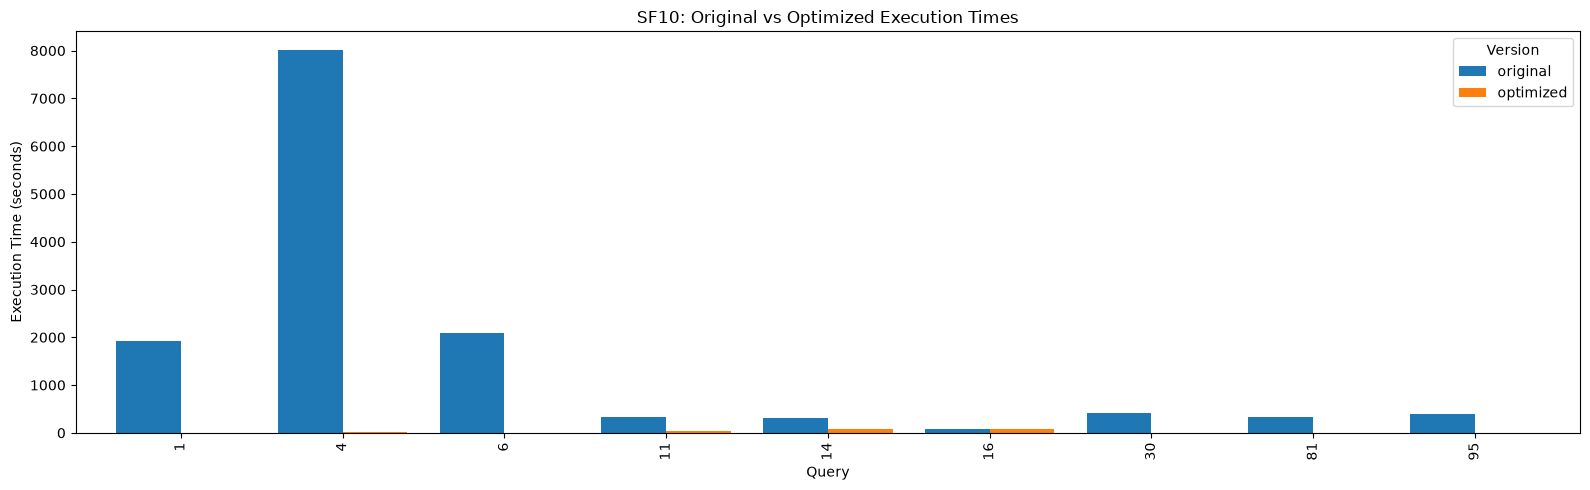

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

runs_path = "benchmarks/sf10/results_compare/sf10_compare/runs.csv"

runs = pd.read_csv(runs_path)

# Keep only successful executions
runs = runs[runs["status"] == "ok"].copy()
runs["seconds"] = runs["ms"] / 1000

comparison = runs.pivot_table(
    index="query",
    columns="version",
    values="seconds",
    aggfunc="mean"
)

# Handle both integer and string query identifiers
comparison["query_num"] = (
    comparison.index.to_series()
    .astype(str)
    .str.extract(r"(\d+)")[0]
    .astype(int)
)

comparison = comparison.sort_values("query_num")

ax = comparison[["original", "optimized"]].plot(
    kind="bar",
    figsize=(16, 5),
    width=0.8
)

plt.xlabel("Query")
plt.ylabel("Execution Time (seconds)")
plt.title("SF10: Original vs Optimized Execution Times")
plt.xticks(rotation=90)
plt.legend(title="Version")
plt.tight_layout()
plt.show()



Skipping SF1: benchmarks/sf1/results_compare/sf1_compare/summary.csv not found


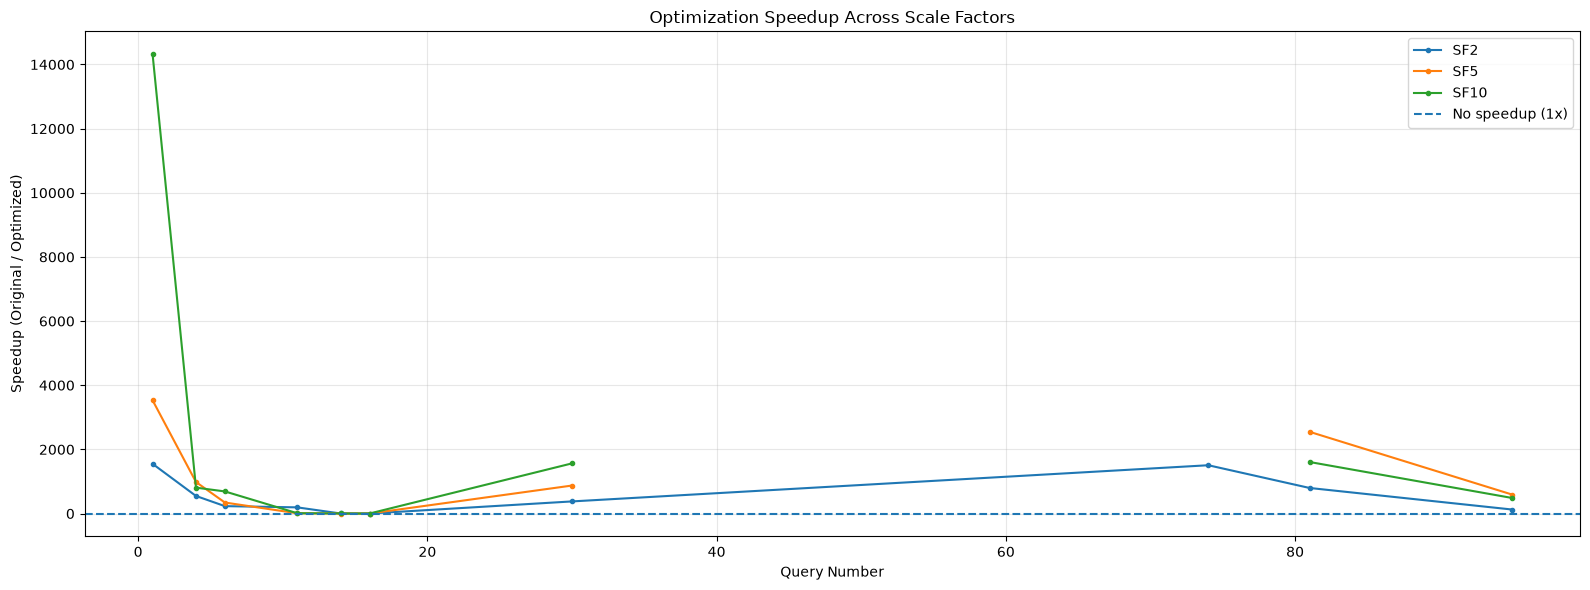

In [4]:

files = {
    1: "benchmarks/sf1/results_compare/sf1_compare/summary.csv",
    2: "benchmarks/sf2/results_compare/sf2_compare/summary.csv",
    5: "benchmarks/sf5/results_compare/sf5_compare/summary.csv",
    10: "benchmarks/sf10/results_compare/sf10_compare/summary.csv"
}

all_data = []

for sf, path in files.items():
    if Path(path).exists():
        temp = pd.read_csv(path)
        temp["sf"] = sf

        # Include only successful, matching queries
        matches = temp["results_match"].astype("string").str.lower()
        temp = temp[
            (temp["status"] == "ok") &
            (matches == "true") &
            (temp["speedup_median"] > 0)
        ].copy()

        all_data.append(temp)
    else:
        print(f"Skipping SF{sf}: {path} not found")

if all_data:
    combined = pd.concat(all_data, ignore_index=True)

    combined["query_num"] = (
        combined["query"]
        .astype(str)
        .str.extract(r"(\d+)")[0]
        .astype(int)
)

    speedup = combined.pivot_table(
        index="query_num",
        columns="sf",
        values="speedup_median",
        aggfunc="mean"
    ).sort_index()

    plt.figure(figsize=(16, 6))

    for sf in speedup.columns:
        plt.plot(
            speedup.index,
            speedup[sf],
            marker="o",
            markersize=3,
            label=f"SF{sf}"
        )

    plt.axhline(1, linestyle="--", label="No speedup (1x)")

    plt.xlabel("Query Number")
    plt.ylabel("Speedup (Original / Optimized)")
    plt.title("Optimization Speedup Across Scale Factors")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("No valid comparison results found.")


In [25]:
"""TPC-DS: compare ORIGINAL, OPTIMIZED, and OPTIMIZED + INDEXES for SF1/2/5/10.

Requirements: pip install pandas numpy matplotlib
Run from your repository root, or edit CSV_FILES to use absolute paths.
"""
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. CONFIGURATION — CHANGE PATHS / FILE NAMES HERE
# ============================================================
# The three scenario keys are used in the legends and calculations.
# These directories and filenames are EXAMPLES: edit to your real paths.
CSV_FILES = {
    sf: {
        "original": f"benchmarks/sf{sf}/results_baseline/exec_time_details.csv",
        "optimized": f"benchmarks/sf{sf}/results_optimization/exec_time_details.csv",
        "optimized_indexes": f"benchmarks/sf{sf}/results_optimization_index/exec_time_details.csv",
    }
    for sf in (1, 2, 5, 10)
}
# For example, if your SF1 baseline CSV is in results_3runs, change just this:
# CSV_FILES[1]["original"] = "benchmarks/sf1/results_3runs/exec_time_details.csv"
# You can also use distinct CSV filenames, e.g. original_queries.csv.

SCENARIOS = {
    "original": "Original queries",
    "optimized": "Optimized queries",
    "optimized_indexes": "Optimized queries + indexes",
}
TIMEOUT_SECONDS = 600  # statement_timeout = 600000 ms
TOP_N_SLOWEST = {1: 8, 2: 8, 5: 10, 10: 10}
MANUAL_SLOW_QUERIES = {
    1: [],                # e.g. ["Q01", "Q04", "Q14"]
    2: [],
    5: [],
    10: [],               # e.g. ["Q01", "Q04", "Q06", "Q74"]
}
TOTALS_LOG_SCALE = False  # Switch to True if large SFs hide SF1/SF2 bars
OUTPUT_DIR = Path("benchmark_plots")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
QUERY_ORDER = [f"Q{i:02d}" for i in range(1, 100)]


In [26]:
# ============================================================
# 2. READ THE THREE CSVs FOR EACH SF
# ============================================================
def read_results(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"CSV not found: {path}\nEdit CSV_FILES to use your real CSV path.")

    df = pd.read_csv(path)
    df.columns = (df.columns.astype(str).str.strip()
                  .str.replace("*", "", regex=False)
                  .str.replace("\ufeff", "", regex=False))
    required = {"query", "status", "avg_exec_time"} | {
        f"exec_time_run_{i}" for i in (1, 2, 3)
    }
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{path}: missing columns {sorted(missing)}")

    ids = df["query"].astype(str).str.extract(r"(\d+)", expand=False)
    if ids.isna().any():
        raise ValueError(f"{path}: some query IDs contain no number")
    df["query"] = ids.astype(int).map(lambda n: f"Q{n:02d}")
    df["status"] = df["status"].fillna("").astype(str).str.strip().str.upper()
    errors = (df["error"] if "error" in df.columns else
              pd.Series("", index=df.index)).fillna("").astype(str)
    has_per_run_error = errors.str.contains(r"run\s*[123]\s*:", case=False, regex=True)
    general_timeout = errors.str.contains(r"timeout|timed out", case=False, regex=True)

    measured_runs, adjusted_runs, timeout_runs = [], [], []
    for run_idx in (1, 2, 3):
        measured = pd.to_numeric(df[f"exec_time_run_{run_idx}"], errors="coerce")
        # Parse run-specific errors so a failed run is not incorrectly called a timeout.
        run_error = errors.str.extract(
            rf"run\s*{run_idx}\s*:\s*([^|]*)", flags=re.IGNORECASE,
            expand=False,
        ).fillna("")
        this_run_timed_out = (
            run_error.str.contains(r"timeout|timed out", case=False, regex=True)
            | (~has_per_run_error & general_timeout)
        ) & measured.isna()
        adjusted = measured.mask(this_run_timed_out, TIMEOUT_SECONDS)
        measured_runs.append(measured)
        adjusted_runs.append(adjusted)
        timeout_runs.append(this_run_timed_out)

    measured_df = pd.concat(measured_runs, axis=1)
    adjusted_df = pd.concat(adjusted_runs, axis=1)
    fully_measured = measured_df.notna().all(axis=1)
    complete_for_plot = adjusted_df.notna().all(axis=1)
    fully_successful = df["status"].eq("SUCCESS") & fully_measured
    any_timeout = pd.concat(timeout_runs, axis=1).any(axis=1)

    # A timed-out execution contributes 600 seconds as a LOWER BOUND, not actual time.
    df["seconds"] = adjusted_df.mean(axis=1).where(complete_for_plot)
    reported_avg = pd.to_numeric(df["avg_exec_time"], errors="coerce")
    df.loc[fully_successful & reported_avg.notna(), "seconds"] = reported_avg
    # Other failures are unknown; don't silently count them as successful timings.
    df.loc[~fully_successful & ~any_timeout, "seconds"] = np.nan
    df["timeout_lower_bound"] = any_timeout & complete_for_plot
    df["fully_successful"] = fully_successful

    if df["query"].duplicated().any():
        raise ValueError(f"{path}: duplicate query IDs")
    if set(df["query"]) != set(QUERY_ORDER):
        raise ValueError(f"{path}: expected exactly Q01 through Q99")
    return df.set_index("query").reindex(QUERY_ORDER)

results = {
    sf: {scenario: read_results(paths[scenario]) for scenario in SCENARIOS}
    for sf, paths in CSV_FILES.items()
}


/var/folders/w5/_mbxz4k91djfvbp9r227lzsm0000gn/T/ipykernel_93860/178637907.py:26: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  pd.Series("", index=df.index)).fillna("").astype(str)
/var/folders/w5/_mbxz4k91djfvbp9r227lzsm0000gn/T/ipykernel_93860/178637907.py:26: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  pd.Series("", index=df.index)).fillna("").astype(str)
/var/folders/w5/_mbxz4k91djfvbp9r227lzsm0000gn/T/ipykernel_93860/178637907.py:26: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  pd.Series("", index=df.index)).fillna("").a

In [27]:
# ============================================================
# 3. COMPUTE TOTALS AND SAVE THE SUMMARY CSV
# ============================================================
summary_rows = []
for sf, versions in results.items():
    for scenario, df in versions.items():
        unresolved = int(df["seconds"].isna().sum())
        summary_rows.append({
            "scale_factor": sf,
            "scenario": scenario,
            "sum_seconds": df["seconds"].sum() if unresolved == 0 else np.nan,
            "successful_queries": int(df["fully_successful"].sum()),
            "timeout_queries": int(df["timeout_lower_bound"].sum()),
            "unresolved_queries": unresolved,
        })

summary = pd.DataFrame(summary_rows)
summary.to_csv(OUTPUT_DIR / "sum_of_average_times_three_scenarios.csv", index=False)
print("Sums of the 99 average query times (seconds):")
print(summary.to_string(index=False, float_format=lambda value: f"{value:,.3f}"))
print("\nNOTE: rows with timeouts are lower bounds; other failures give N/A totals.\n")


Sums of the 99 average query times (seconds):
 scale_factor          scenario  sum_seconds  successful_queries  timeout_queries  unresolved_queries
            1          original    1,526.109                  97                2                   0
            1         optimized       23.511                  99                0                   0
            1 optimized_indexes       19.059                  99                0                   0
            2          original    1,630.422                  98                1                   0
            2         optimized       58.388                  99                0                   0
            2 optimized_indexes       49.172                  99                0                   0
            5          original    3,393.295                  96                3                   0
            5         optimized      180.160                  99                0                   0
            5 optimized_indexes     

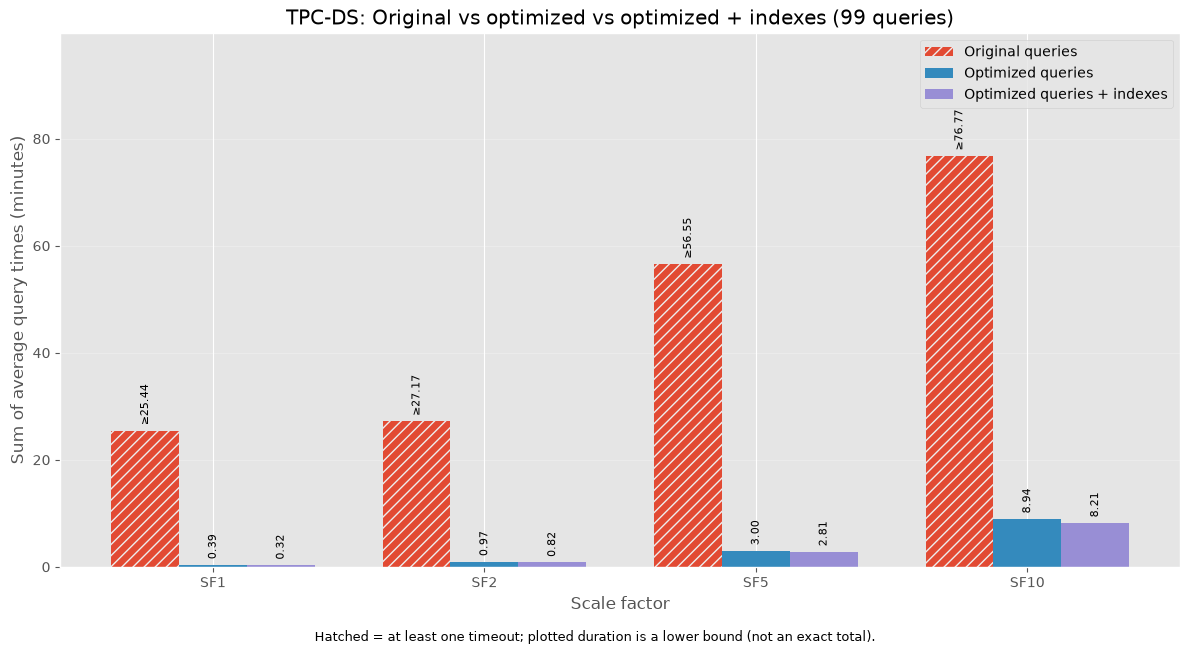

In [28]:
# ============================================================
# 4. PLOT 1 — THREE BARS PER SCALE FACTOR
# ============================================================
sfs = list(CSV_FILES)
x = np.arange(len(sfs))
bar_width = 0.25
fig, ax = plt.subplots(figsize=(12, 6.5))

for i, (scenario, label) in enumerate(SCENARIOS.items()):
    subset = summary.loc[summary["scenario"].eq(scenario)].set_index("scale_factor").loc[sfs]
    values_min = subset["sum_seconds"] / 60
    bars = ax.bar(x + (i - 1) * bar_width, values_min, bar_width, label=label)
    for bar, (_, row) in zip(bars, subset.iterrows()):
        if pd.isna(row["sum_seconds"]):
            ax.annotate("N/A", (bar.get_x() + bar.get_width()/2, 0),
                        xytext=(0, 5), textcoords="offset points",
                        ha="center", va="bottom", fontsize=8, rotation=90)
            continue
        censored = row["timeout_queries"] > 0
        if censored:
            bar.set_hatch("///")
        label_text = f"{'≥' if censored else ''}{row['sum_seconds']/60:.2f}"
        ax.annotate(label_text, (bar.get_x() + bar.get_width()/2, bar.get_height()),
                    xytext=(0, 4), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8, rotation=90)

ax.set_xticks(x, [f"SF{sf}" for sf in sfs])
ax.set_ylabel("Sum of average query times (minutes)")
ax.set_xlabel("Scale factor")
ax.set_title("TPC-DS: Original vs optimized vs optimized + indexes (99 queries)")
ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
if TOTALS_LOG_SCALE:
    positives = summary.loc[summary["sum_seconds"] > 0, "sum_seconds"] / 60
    ax.set_yscale("log")
    ax.set_ylim(bottom=max(0.0001, positives.min() / 2) if len(positives) else 0.0001)
else:
    hmax = (summary["sum_seconds"] / 60).max()
    ax.set_ylim(0, hmax * 1.30 if pd.notna(hmax) and hmax > 0 else 1)
fig.text(0.5, 0.005,
         "Hatched = at least one timeout; plotted duration is a lower bound (not an exact total).",
         ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0.025, 1, 1])
fig.savefig(OUTPUT_DIR / "total_times_three_scenarios.png", dpi=220, bbox_inches="tight")
plt.show()


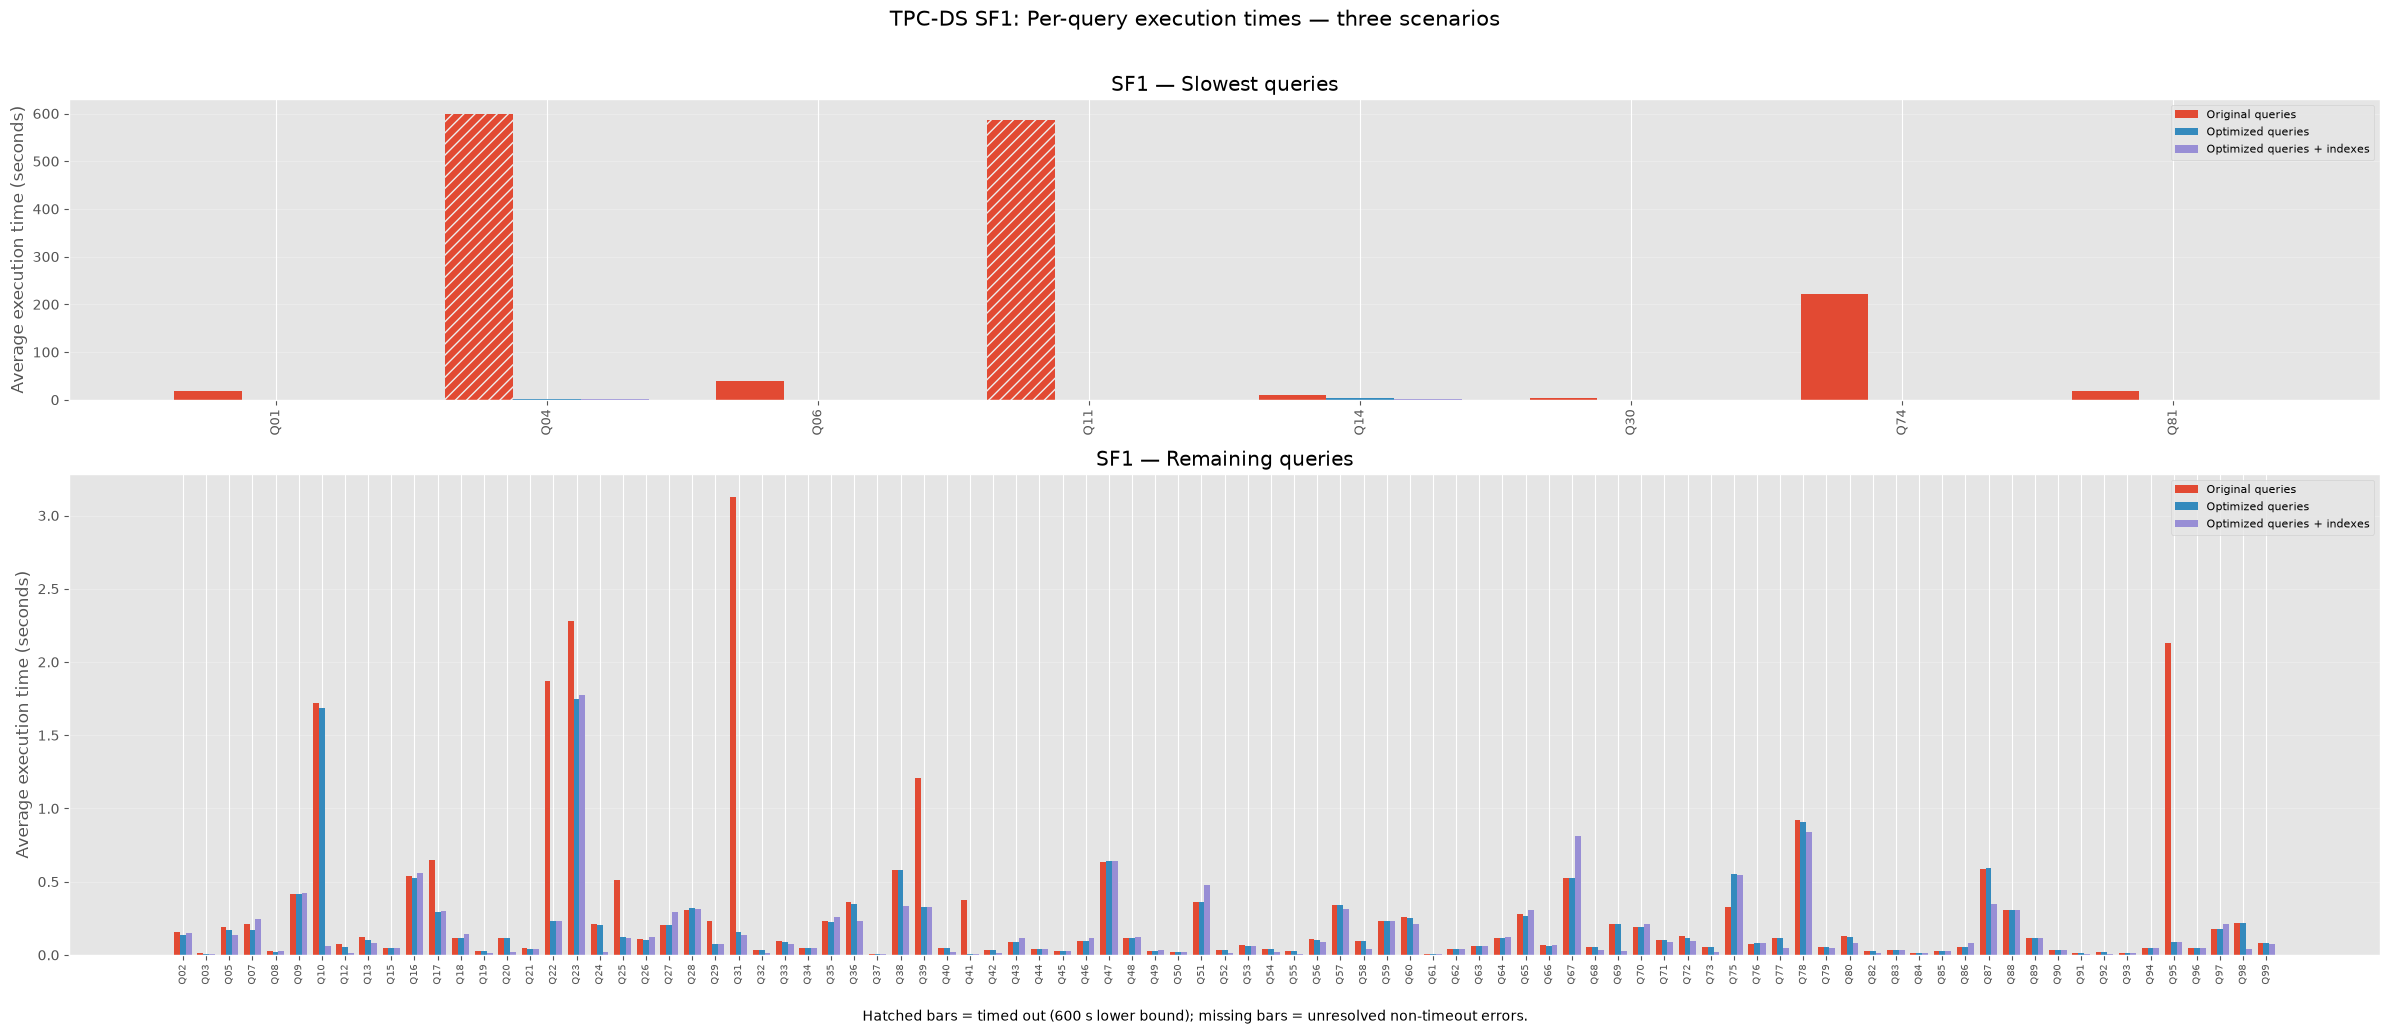

SF1 slowest: Q01, Q04, Q06, Q11, Q14, Q30, Q74, Q81


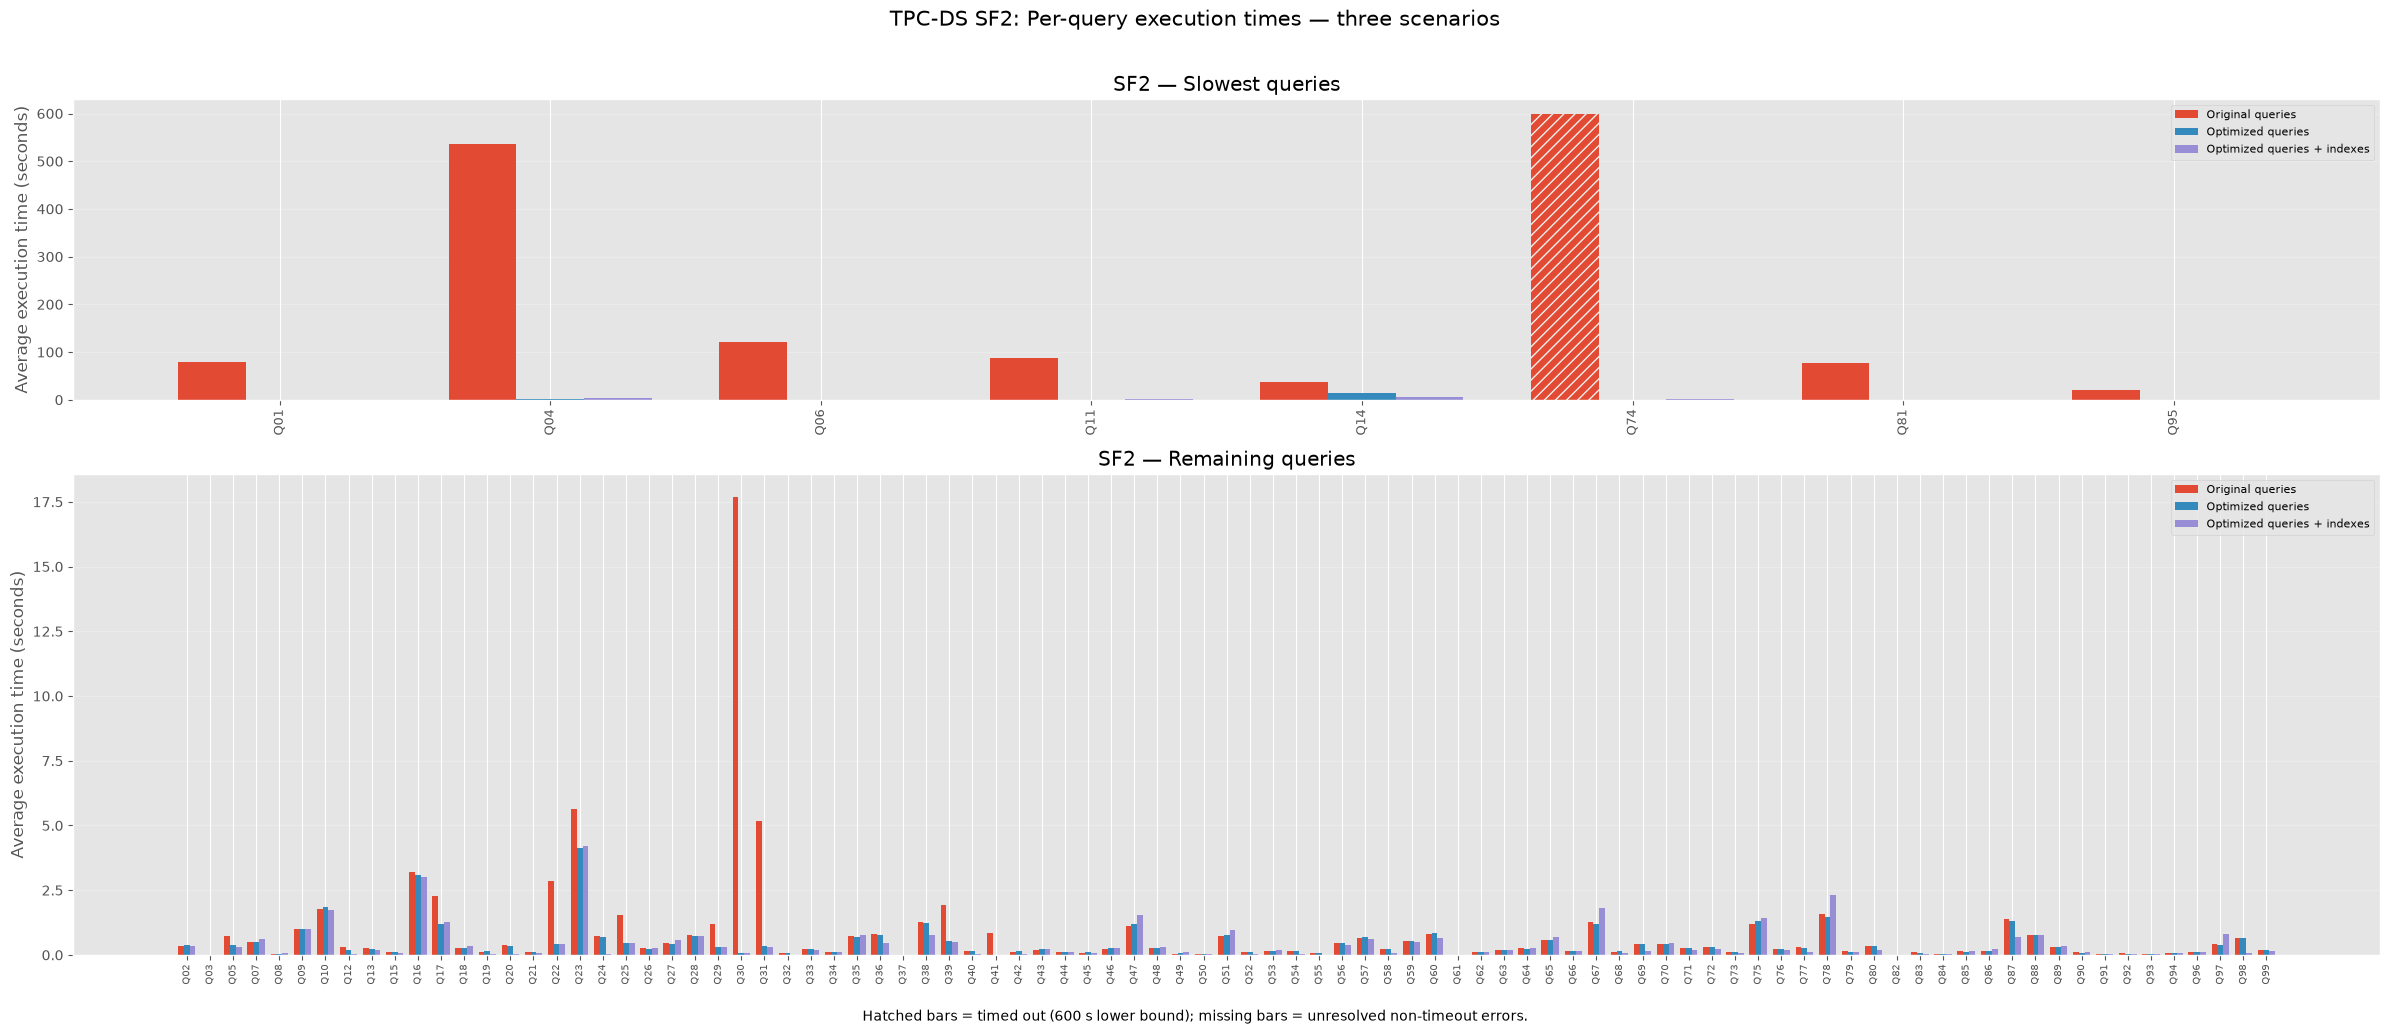

SF2 slowest: Q01, Q04, Q06, Q11, Q14, Q74, Q81, Q95


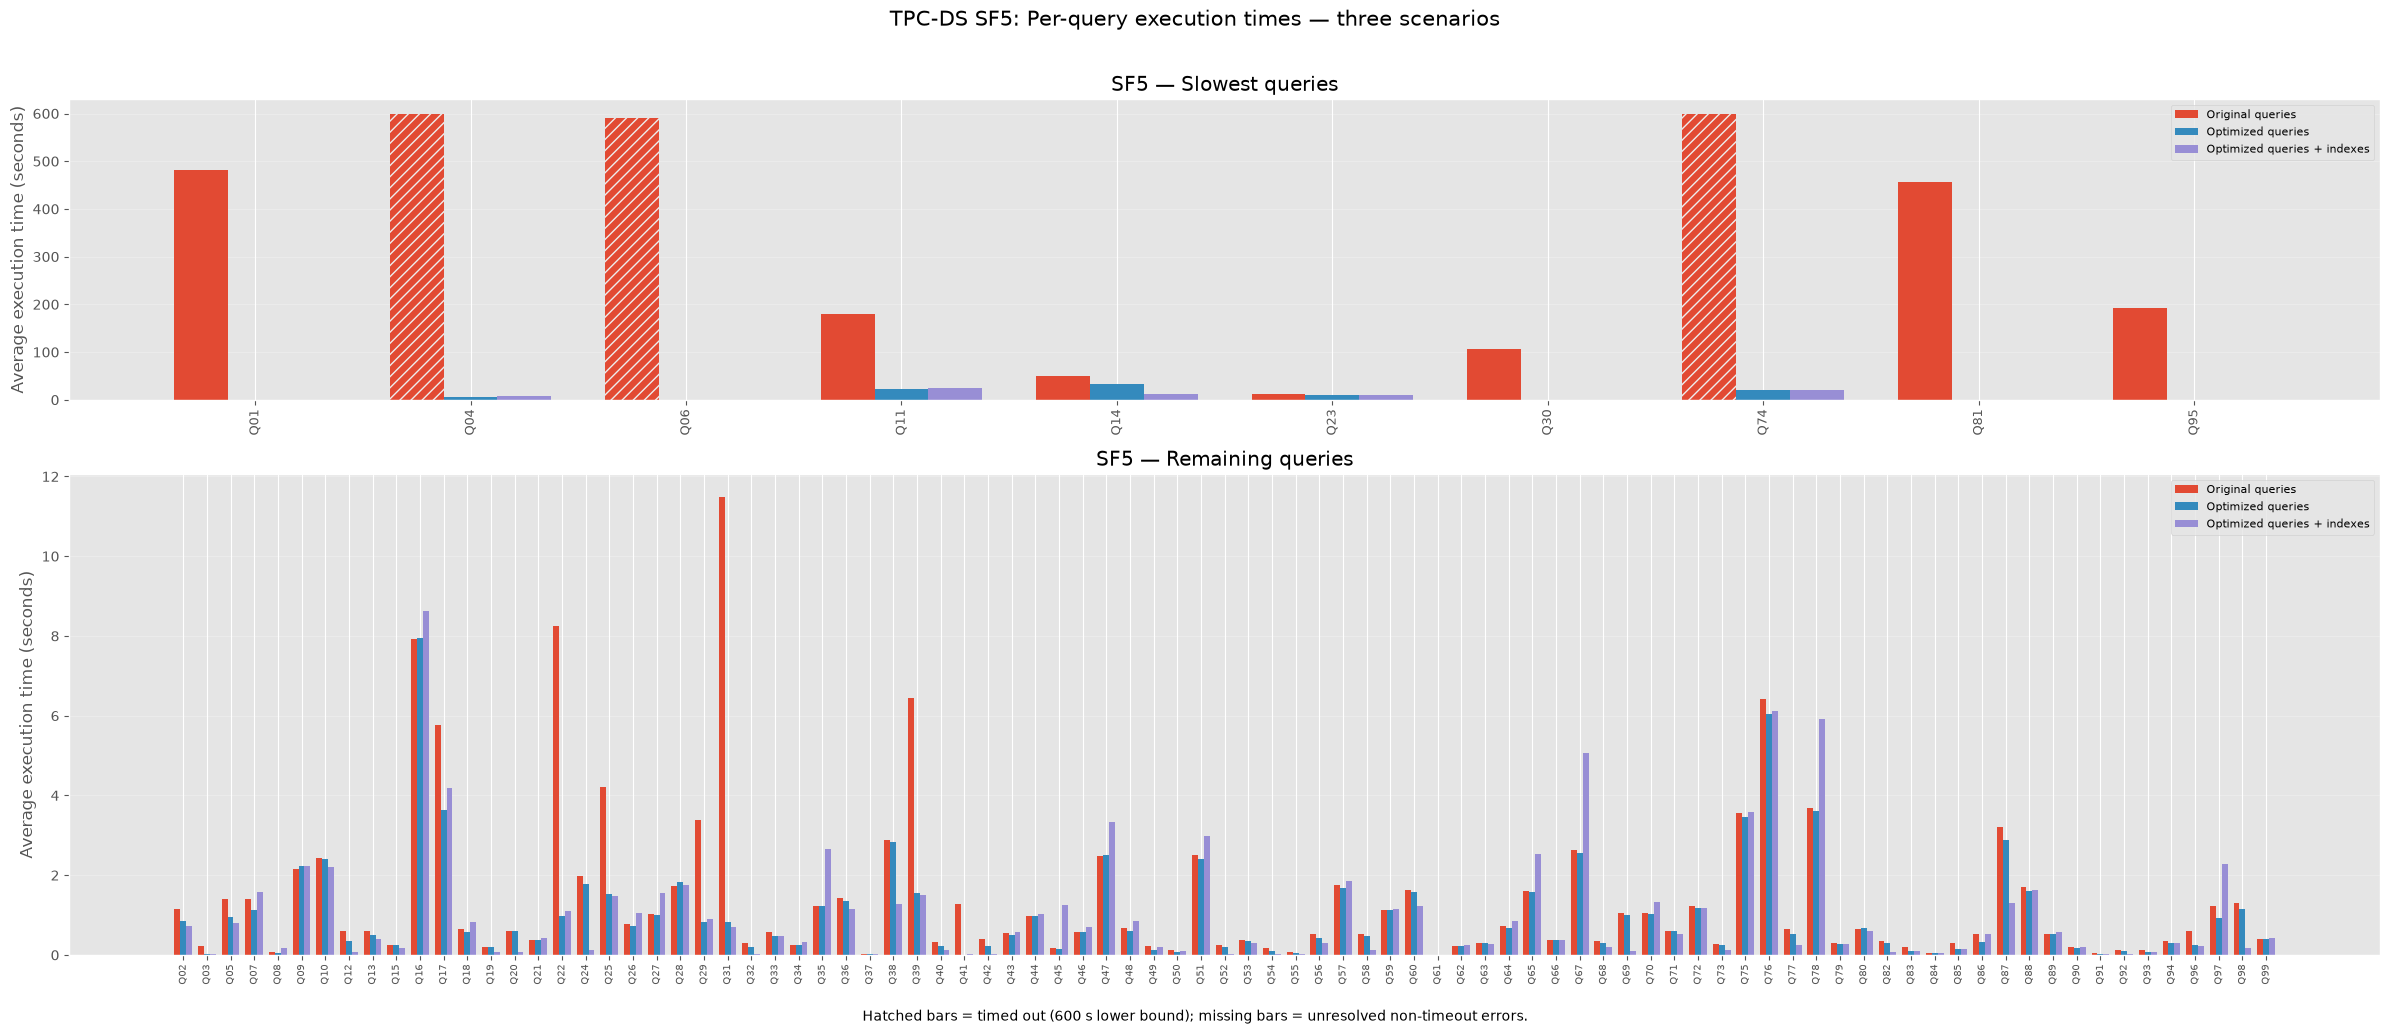

SF5 slowest: Q01, Q04, Q06, Q11, Q14, Q23, Q30, Q74, Q81, Q95


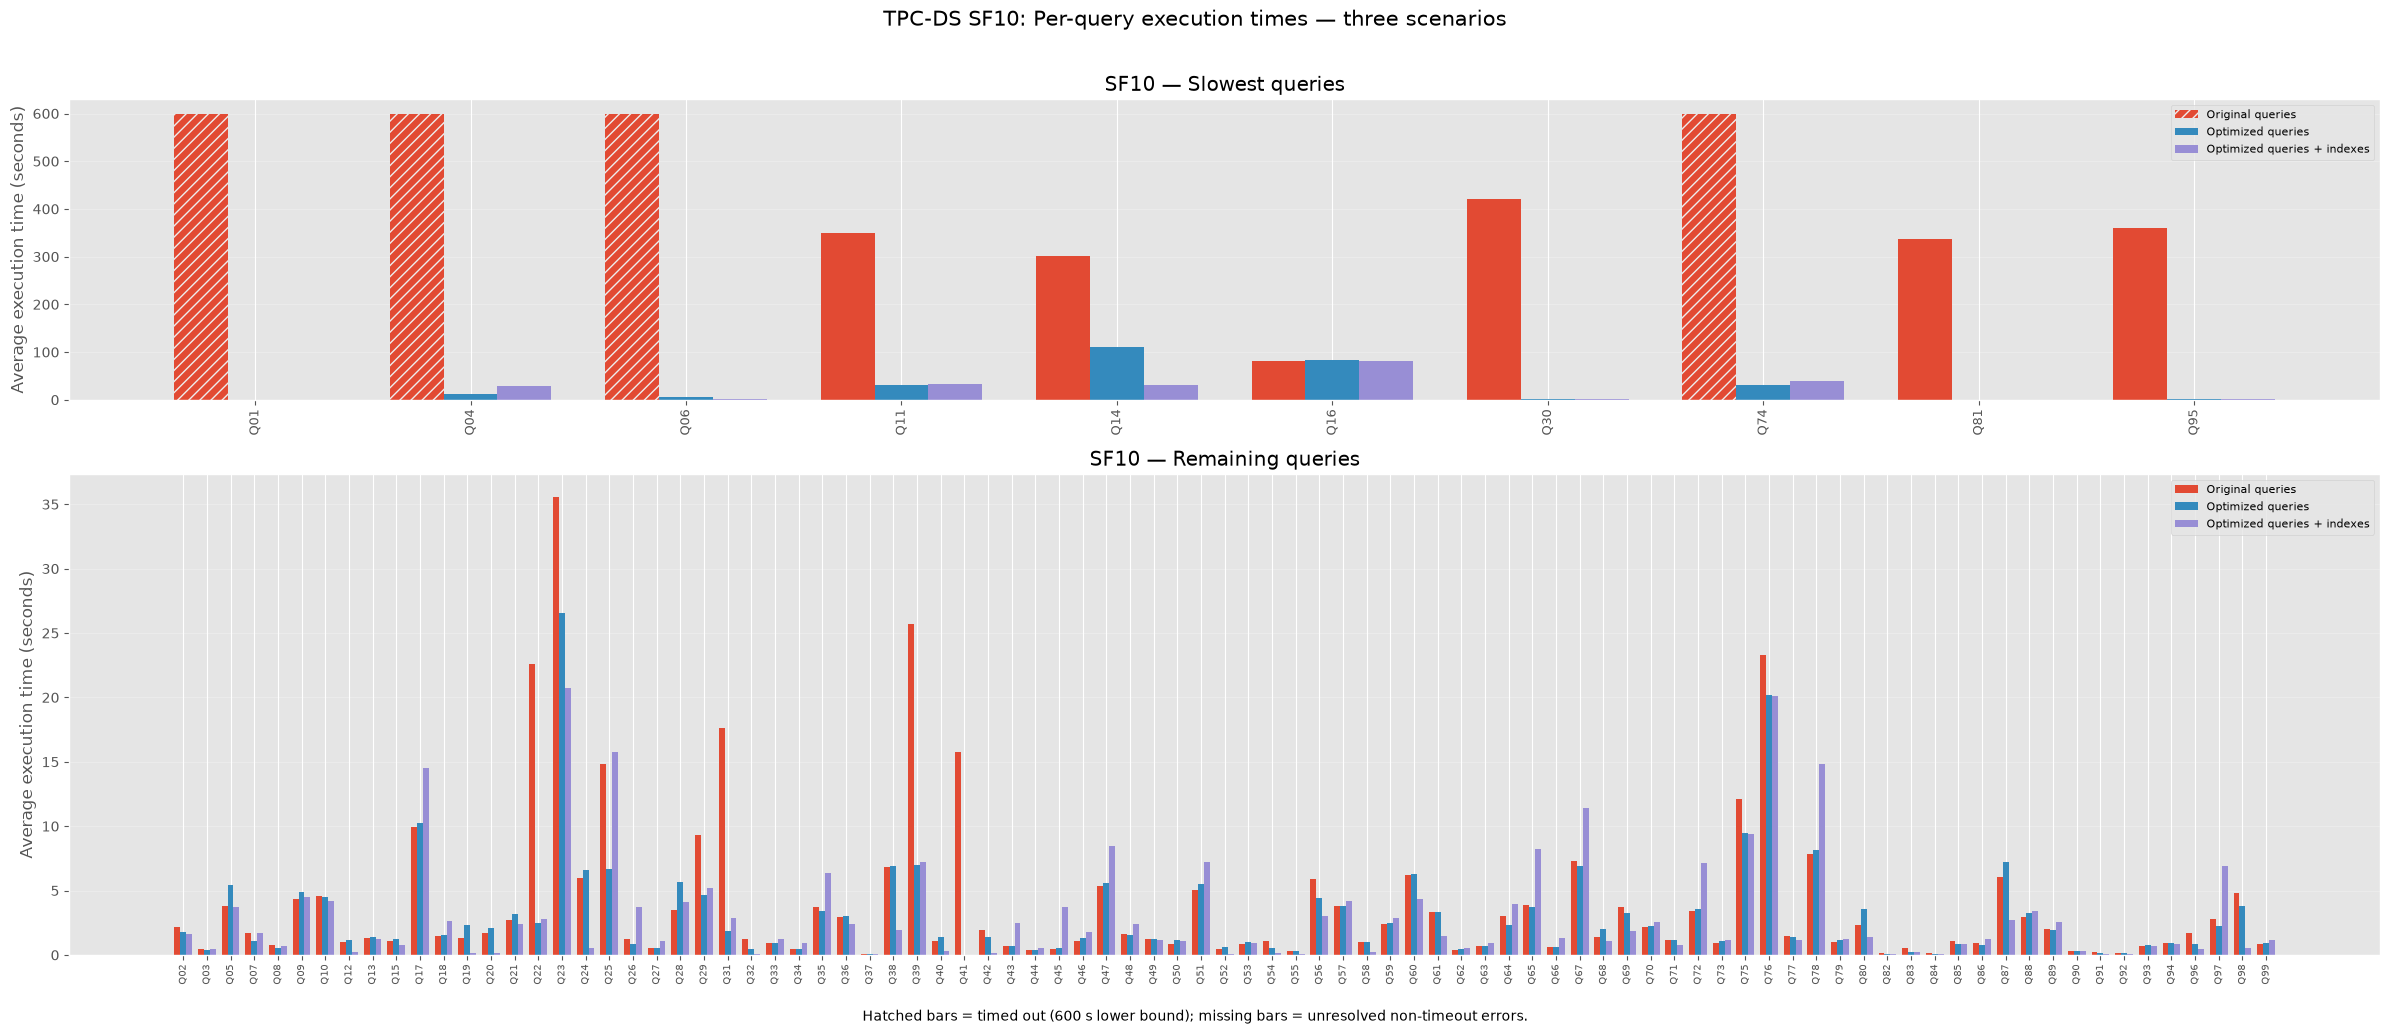

SF10 slowest: Q01, Q04, Q06, Q11, Q14, Q16, Q30, Q74, Q81, Q95

Saved charts and summary CSV to: /Users/negarsourati/Documents/ULB-first-semester/Data-Warehouses/TPC_DS/tpcds-postgresql/benchmark_plots


In [29]:
# ============================================================
# 5. PLOT 2 — PER-QUERY COMPARISON; SLOWEST SEPARATED FOR EACH SF
# ============================================================
def normalize_query_id(query):
    match = re.search(r"\d+", str(query))
    if not match:
        raise ValueError(f"Invalid query ID: {query}")
    return f"Q{int(match.group()):02d}"

def draw_group(ax, compare, title, compact=False):
    xs = np.arange(len(compare))
    width = 0.25
    for i, (scenario, label) in enumerate(SCENARIOS.items()):
        bars = ax.bar(xs + (i - 1) * width, compare[scenario],
                      width, label=label)
        for bar, timed_out in zip(bars, compare[f"{scenario}_timeout"]):
            if timed_out:
                bar.set_hatch("///")
    ax.set_xticks(xs, compare["query"], rotation=90, fontsize=7 if compact else 9)
    ax.set_ylabel("Average execution time (seconds)")
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(fontsize=8, loc="upper right")

for sf, versions in results.items():
    compare = pd.DataFrame({"query": QUERY_ORDER})
    for scenario, df in versions.items():
        compare[scenario] = df["seconds"].to_numpy()
        compare[f"{scenario}_timeout"] = df["timeout_lower_bound"].to_numpy()
    compare["worst_time"] = compare[list(SCENARIOS)].max(axis=1)

    chosen = MANUAL_SLOW_QUERIES.get(sf, [])
    if chosen:
        slow_ids = {normalize_query_id(q) for q in chosen}
        if not slow_ids.issubset(set(QUERY_ORDER)):
            raise ValueError(f"Invalid slow-query ID for SF{sf}: {slow_ids}")
    else:
        slow_ids = set(compare.nlargest(TOP_N_SLOWEST[sf], "worst_time")["query"])

    slow = compare.loc[compare["query"].isin(slow_ids)]
    remaining = compare.loc[~compare["query"].isin(slow_ids)]
    fig, axes = plt.subplots(2, 1, figsize=(24, 10),
                             gridspec_kw={"height_ratios": [1, 1.6]})
    draw_group(axes[0], slow, f"SF{sf} — Slowest queries")
    draw_group(axes[1], remaining, f"SF{sf} — Remaining queries", compact=True)
    fig.suptitle(f"TPC-DS SF{sf}: Per-query execution times — three scenarios",
                 fontsize=15, y=1.015)
    fig.text(0.5, 0.004,
             "Hatched bars = timed out (600 s lower bound); missing bars = unresolved non-timeout errors.",
             ha="center", fontsize=10)
    fig.tight_layout(rect=[0, 0.025, 1, 1])
    fig.savefig(OUTPUT_DIR / f"query_comparison_three_scenarios_sf{sf}.png",
                dpi=220, bbox_inches="tight")
    plt.show()
    print(f"SF{sf} slowest: {', '.join(slow['query'])}")

print(f"\nSaved charts and summary CSV to: {OUTPUT_DIR.resolve()}")


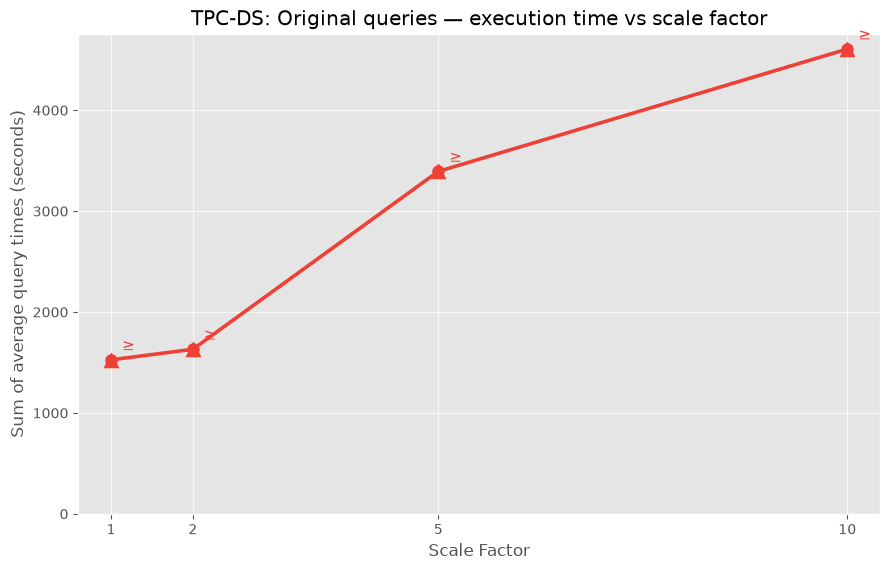

Saved: benchmark_plots/line_separate_original.png


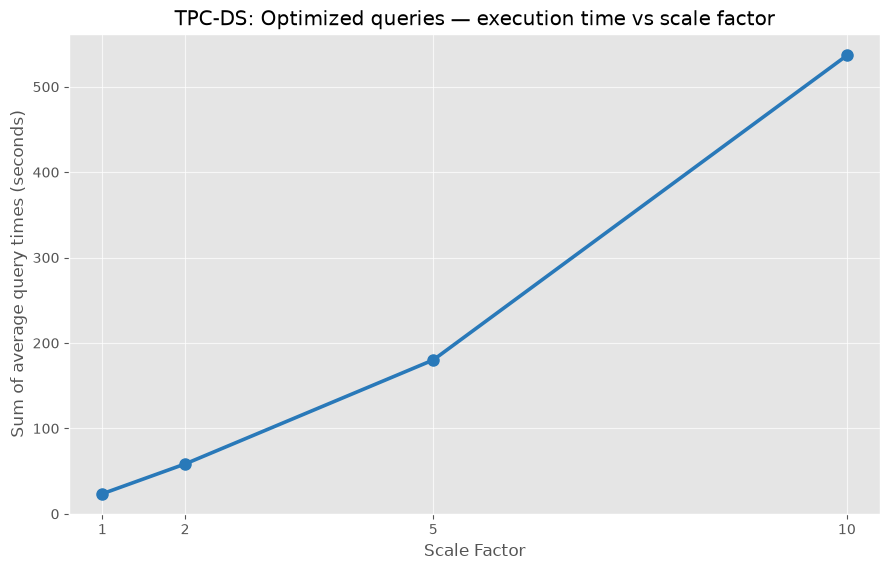

Saved: benchmark_plots/line_separate_optimized.png


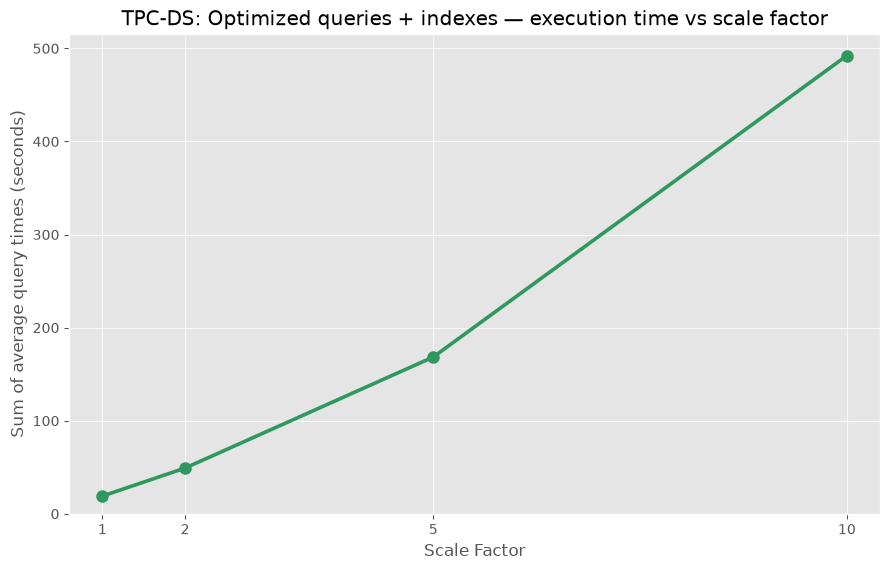

Saved: benchmark_plots/line_separate_optimized_indexes.png


In [34]:
# ============================================================
# 6. LINE PLOTS — ONE SEPARATE GRAPH FOR EACH SCENARIO
# ============================================================
# Run the cells above first: this uses the `summary` DataFrame created in cell 3.
# Edit colors and LABEL_LINE_POINTS if you want a different appearance.
LINE_COLORS = {
    "original": "#ef4036",
    "optimized": "#2979b9",
    "optimized_indexes": "#2e985e",
}
LABEL_LINE_POINTS = False   # True = show values next to the markers
LINE_Y_LOG_SCALE = False    # True = use logarithmic y-axis for combined chart

# One row per scale factor and scenario; includes known timeout metadata.
line_data = summary.copy().sort_values("scale_factor")
sfs = sorted(CSV_FILES.keys())

def plot_line_series(ax, rows, scenario, label):
    """Use measured totals; distinguish timeout-derived lower bounds."""
    rows = rows.set_index("scale_factor").reindex(sfs)
    ys = rows["sum_seconds"].astype(float).to_numpy()
    timeout = rows["timeout_queries"].fillna(0).to_numpy() > 0
    color = LINE_COLORS[scenario]

    ax.plot(sfs, ys, color=color, marker="o", markersize=8,
            linewidth=2.6, label=label)
    for sf, val, is_lower in zip(sfs, ys, timeout):
        if np.isnan(val):
            continue
        if is_lower:
            ax.scatter([sf], [val], color=color, marker="^", s=115, zorder=5)
            ax.annotate("≥", (sf, val), xytext=(8, 7),
                        textcoords="offset points", fontsize=11, color=color)
        if LABEL_LINE_POINTS:
            ax.annotate(f"{val:,.1f} s", (sf, val), xytext=(0, 13),
                        textcoords="offset points", ha="center", fontsize=9)
    ax.set_xticks(sfs)
    ax.set_xlabel("Scale Factor")
    ax.set_ylabel("Sum of average query times (seconds)")
    ax.grid(True, alpha=0.7)
    ax.set_xlim(min(sfs) - 0.4, max(sfs) + 0.4)

for scenario, label in SCENARIOS.items():
    rows = line_data.loc[line_data["scenario"] == scenario]
    with plt.style.context("ggplot"):
        fig, ax = plt.subplots(figsize=(9, 5.8))
        plot_line_series(ax, rows, scenario, label)
        ax.set_title(f"TPC-DS: {label} — execution time vs scale factor")
        ax.set_ylim(bottom=0)
        fig.tight_layout()
        output = OUTPUT_DIR / f"line_separate_{scenario}.png"
        fig.savefig(output, dpi=220, bbox_inches="tight")
        plt.show()
        print(f"Saved: {output}")


KeyError: 'original'

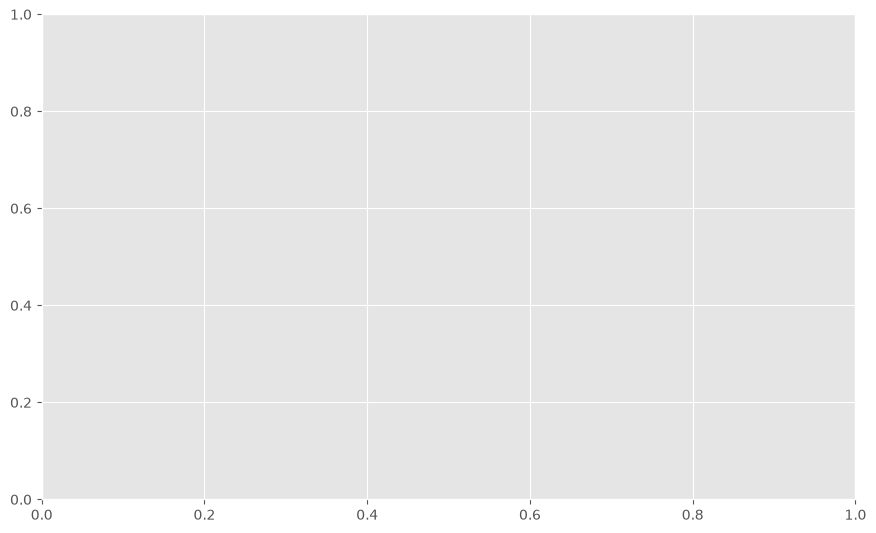

In [33]:
# ============================================================
# 7. LINE PLOT — ALL THREE SCENARIOS ON THE SAME GRAPH
# ============================================================
# Set LINE_Y_LOG_SCALE = True in cell 6 if SF10 dwarfs the smaller SFs.
with plt.style.context("ggplot"):
    fig, ax = plt.subplots(figsize=(10.5, 6.3))

    for scenario, label in SCENARIOS.items():
        rows = line_data.loc[line_data["scenario"] == scenario]
        plot_line_series(ax, rows, scenario, label)

    ax.set_title("TPC-DS: Execution time vs scale factor — 3 scenarios")
    if LINE_Y_LOG_SCALE:
        ax.set_yscale("log")
    else:
        ax.set_ylim(bottom=0)
    ax.legend(title="Benchmark scenario", loc="best")
    fig.tight_layout()
    output = OUTPUT_DIR / "line_all_three_scenarios.png"
    fig.savefig(output, dpi=220, bbox_inches="tight")
    plt.show()
    print(f"Saved: {output}")

print("Note: ▲/≥ denotes a lower bound when some query runs timed out at 600 s.")


In [40]:
arr = np.array([1503.0, 1543.9, 1545.3])

# Both lines do the exact same thing
avg_mean = np.mean(arr)
avg_mean

np.float64(1530.7333333333333)

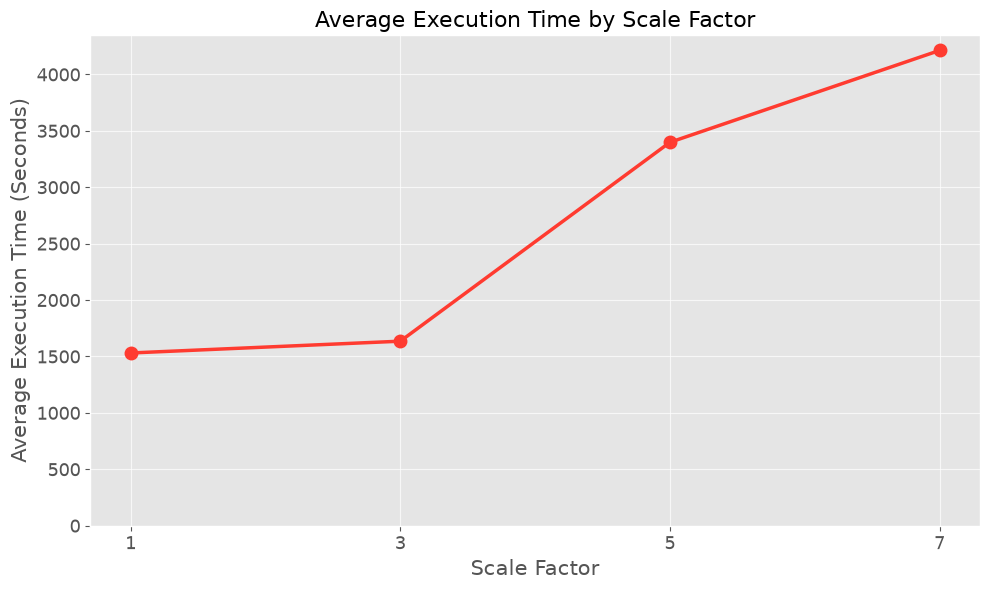

In [41]:
import numpy as np
import matplotlib.pyplot as plt

# Scale factors
scale_factors = [1, 3, 5, 7]

# Average execution times (in seconds)
# Replace these values with your actual results
avg_exec_times = [1530.7333333333333, 1635.2666666666667, 3398.366666666667, 4212.433333333333]

plt.style.use("ggplot")

plt.figure(figsize=(10, 6))

plt.plot(
    scale_factors,
    avg_exec_times,
    color="#FF3B30",
    marker="o",
    markersize=9,
    linewidth=2.5
)

plt.xlabel("Scale Factor", fontsize=15)
plt.ylabel("Average Execution Time (Seconds)", fontsize=15)
plt.title("Average Execution Time by Scale Factor", fontsize=16)

plt.xticks(scale_factors, fontsize=13)
plt.yticks(fontsize=13)

plt.ylim(bottom=0)
plt.grid(True, alpha=0.7)

plt.tight_layout()
plt.show()